# Product category classification: GNN experiments V2 (three seeds)

Compare **GCN, GraphSAGE and GAT** on the same TAPE subset and original released splits. The earlier single-seed notebook and its results are in the git history.

Each architecture has four conditions: **OGB only**, **OGB + raw degree**, **raw degree only**, and **OGB-only cold start**. Train the first three conditions with seeds **5284, 5285 and 5286**; cold start reuses each seed's OGB-only checkpoint. This gives **27 training runs and 9 additional cold-start evaluations**, with unchanged train/validation/test masks.

Results are saved under **`results/1_gnn_ogb/02_multi_seed/`**. Top-level condition CSVs represent the first seed; `per_seed/seed_<seed>/` contains individual seed results, and `seed_summary.csv` reports means, standard deviations and counts. Checkpoints use **`outputs/weights/GNN_experiments/02_multi_seed/`**. No stratified-split experiment is included.

Dependencies: PyTorch/PyG plus compatible DGL for the course residual GCN (`code02_dgl_exercise.ipynb`). GAT retains its custom four-layer implementation; GraphSAGE is defined locally as `ProductGraphSAGE` with four layers. All three architectures use four message-passing layers and classify nodes directly; parameter budgets and classifier heads still differ.

Run from the beginning. Validation/test predictions, confusion matrices, per-category metrics and recall intervals, support-group/seen-category diagnostics and common-mixture comparisons are retained. Test results never select checkpoints.

**Architecture revision (run on 2026-11-15, commit `2d95fe2`):** GCN has dropout, GraphSAGE has a separate MLP head, and GraphSAGE/GAT have identity residual updates. All three use four 128-wide graph layers and two MLP hidden layers. The results in `02_multi_seed` come from this revision; checkpoints from earlier versions are not interchangeable with it.


# Import packages

In [1]:
from pathlib import Path
import random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch_geometric
import torch_sparse
import torch
import torchdata
from torchdata.datapipes.iter import IterDataPipe
import dgl

from torch_geometric.nn import MessagePassing
from torch_geometric.utils import softmax, to_undirected, remove_self_loops, add_self_loops
from IPython.display import display

print("PyTorch:", torch.__version__)
print("TorchData:", torchdata.__version__)
print("DGL:", dgl.__version__)

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'requirements.txt').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter inside the project repository.')
DATA = ROOT / 'data' / 'TAPE'


<project>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.1.2+cpu
TorchData: 0.7.1
DGL: 2.2.1


# Constants

In [2]:
SEED = 5284
SEEDS = [5284, 5285, 5286]  # Three independent initialisations.
CPU_THREADS = 4
torch.set_num_threads(CPU_THREADS)
CLASSES = 47
HEADS = 4
WIDTH = 32  # Features per head; total hidden dimension is HEADS * WIDTH.
GAT_LAYERS = 4
MLP_HIDDEN_LAYERS = 2
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 40
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('Torch:', torch.__version__, '| PyG:', torch_geometric.__version__)
# Seed the random generators for repeatability.

Torch: 2.1.2+cpu | PyG: 2.5.1


# Load and validate the EDA subset

Load only the trusted official pickle retrieved by the EDA notebook. Preserve CSV row order and released masks; original nid values are not subset indices. Standardisation is fitted on training features only. Categories missing from training remain in the classification task.

## Load datasets

In [3]:
# 1. Define the cached graph and product-text file paths
paths = {'graph': DATA / 'ogbn-products_subset.pt', 
         'text': DATA / 'ogbn-products_subset.csv',
         'mapping': DATA / 'labelidx2productcategory.csv.gz'
         }

# 2. Load the graph 
graph = torch.load(paths['graph'], map_location='cpu', weights_only=False)
print("Graph:")
print(graph)

# 3. Load product text and identify the labels of each node
text = pd.read_csv(paths['text'])
mapping = pd.read_csv(paths['mapping'])
mapping = mapping.rename(columns={'label idx': 'label'})

n = int(graph.num_nodes)
labels = np.asarray(graph.y.detach().cpu().reshape(-1).long())
nodes = text.copy()
nodes.insert(0, 'node_id', np.arange(n))
nodes['label'] = labels
nodes = nodes.merge(mapping, on='label', how='left')

# 4. Identify each node's released train/val/test split
split_by_node = np.full(n, 'unassigned', dtype=object)
assigned = np.zeros(n, dtype=bool)
for split, attr in [('train', 'train_mask'), ('val', 'val_mask'), ('test', 'test_mask')]:
    mask = getattr(graph, attr).detach().cpu()
    if mask.shape == (n, 1):
        mask = mask[:, 0]
    assert mask.dtype == torch.bool and mask.shape == (n,), attr
    mask = mask.numpy()
    assert not (assigned & mask).any(), 'Overlapping splits'
    split_by_node[mask] = split
    assigned |= mask
nodes['split'] = split_by_node[nodes['node_id'].to_numpy()]

print('\nNodes:')
print(f"Distinct product categories in original mapping: {len(mapping)}")
print(f"Distinct product categories in ogbn subset data: {nodes['product category'].nunique()}")
display(nodes)

Graph:
Data(num_nodes=54025, x=[54025, 100], y=[54025, 1], adj_t=[54025, 54025, nnz=74420], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], e_id=[74420], input_id=[128], batch_size=128, n_asin=[54025])

Nodes:
Distinct product categories in original mapping: 47
Distinct product categories in ogbn subset data: 42


,node_id,uid,nid,title,content,label,product category,split
0,0,B00JXMX35K,1324660,Aimee Gowns Original Bra-less Nursing Gown (X-...,The one that started it all! The nightgown's m...,11,"Clothing, Shoes & Jewelry",test
1,1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Pr...,Heavy duty printing,18,Office Products,test
2,2,B00B67RO9Q,1780321,NaN,NaN,4,Books,test
3,3,B005JN9CKM,2447868,Muay Thai Shorts-Black,"for Size Chart, please see attached photos. Im...",11,"Clothing, Shoes & Jewelry",test
4,4,B00CU9YBVS,1940019,Smatree&reg; Chest Belt/Strap Harness Mount+ A...,1. Smatree chest strap is fully adjustable to ...,12,Electronics,test
...,...,...,...,...,...,...,...,...
54020,54020,0787965383,2276523,Distributed Leadership,&#8220;We all know how important leadership is...,4,Books,test
54021,54021,049591049X,18428,American Public School Law,"""Kern Alexander was the lead author of this te...",4,Books,train
54022,54022,0470651725,66543,The Leadership Challenge: How to Make Extraord...,NaN,4,Books,train
54023,54023,1930556748,1189359,Data Analysis for Continuous School Improvement,Solve your school's problems by using data.Thi...,4,Books,test


## Validate data

In [4]:
# 1. Extract features and labels; validate shapes, values, and category IDs
n = int(graph.num_nodes)

x = graph.x.detach().cpu().float()
print(f"Graph features:")
print(x.shape)
print(x)

y = graph.y.detach().cpu().reshape(-1).long()
print(f"\nGraph labels:")
print(y.shape)
print(y)

## Assertion checks
assert len(nodes) == len(y) == n
assert x.ndim == 2 and x.shape[0] == n and x.shape[1] > 0 and torch.isfinite(x).all()
assert ((y >= 0) & (y < CLASSES)).all()


# 2. Load the released split masks and check that they do not overlap
masks = {}
for split, attr in [('train', 'train_mask'), ('valid', 'val_mask'), ('test', 'test_mask')]:
    m = getattr(graph, attr).detach().cpu()
    if m.shape == (n, 1):
        m = m[:, 0]
    assert m.dtype == torch.bool and m.shape == (n,) and m.any(), attr
    masks[split] = m
assert (torch.stack(list(masks.values())).sum(0) <= 1).all(), 'Overlapping splits'

print('\nTrain/val/test masks:')
for k, v in masks.items():
    print(f"{k}: {v} ({v.sum()} products)")

Graph features:
torch.Size([54025, 100])
tensor([[-0.4452, -0.8554, -1.9767,  ...,  0.6105,  1.5563, -0.2888],
        [-0.1029, -0.0840, -0.3326,  ...,  0.2229, -0.0864,  0.0515],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 0.0410,  0.0170, -0.0311,  ...,  0.1006,  0.0102,  0.0751],
        [-1.9333,  0.7174, -1.2747,  ..., -0.6137,  4.2826,  0.9055],
        [ 0.5865, -0.1433, -0.1699,  ..., -0.3614,  0.0513,  0.0335]])

Graph labels:
torch.Size([54025])
tensor([11, 18,  4,  ...,  4,  4,  4])

Train/val/test masks:
train: tensor([False, False, False,  ...,  True, False, False]) (14708 products)
valid: tensor([False, False, False,  ..., False, False, False]) (1572 products)
test: tensor([ True,  True,  True,  ..., False,  True,  True]) (37745 products)


## Check splits

In [5]:
grouped = (
    nodes.groupby('split')['uid']
    .count()
    .reindex(['train', 'val', 'test'], fill_value=0)
    .to_frame('count')
)
grouped['pct'] = (grouped['count'] / len(nodes) * 100).round(2)
grouped = grouped.T.rename_axis(index=None, columns=None)
display(grouped)

# Train/val/test split by product
grouped = (
    nodes.groupby(['label', 'product category', 'split'])
    .agg(count=('uid', 'count'))
    .reset_index()
    .pivot(
        index=['label', 'product category'],
        columns='split',
        values='count'
    )
    .fillna(0)
    .astype(int)
)
grouped = grouped.rename(columns={'val': 'valid'})
grouped = grouped.reindex(columns=['train', 'valid', 'test'], fill_value=0)
grouped['total'] = grouped.sum(axis=1)

for split in ['train', 'valid', 'test']:
    grouped[f'{split}_proportion'] = round(grouped[split] / grouped['total']*100, 2)

grouped = grouped.reset_index().rename_axis(columns=None).sort_values('label')
display(grouped)

,train,val,test
count,14708.00,1572.00,37745.00
pct,27.22,2.91,69.87


,label,product category,train,valid,test,total,train_proportion,valid_proportion,test_proportion
0,0,Home & Kitchen,848,89,1784,2721,31.17,3.27,65.56
1,1,Health & Personal Care,1361,136,2497,3994,34.08,3.41,62.52
2,2,Beauty,1022,144,2552,3718,27.49,3.87,68.64
3,3,Sports & Outdoors,869,132,3604,4605,18.87,2.87,78.26
4,4,Books,4017,383,6556,10956,36.66,3.50,59.84
5,5,"Patio, Lawn & Garden",240,24,385,649,36.98,3.70,59.32
6,6,Toys & Games,1043,96,2302,3441,30.31,2.79,66.90
7,7,CDs & Vinyl,846,83,1753,2682,31.54,3.09,65.36
8,8,Cell Phones & Accessories,1154,127,1738,3019,38.22,4.21,57.57
9,9,Grocery & Gourmet Food,181,16,258,455,39.78,3.52,56.70


# Graph preparation

Convert transposed sparse adjacency (destination rows, source columns) into source-to-destination edge_index, symmetrise and deduplicate, then add exactly one self-loop per node. Isolated nodes are retained. This is transductive learning: all node features and edges participate in message passing, while only training labels contribute to the loss. Validation labels select a checkpoint; test labels are evaluated after training.

## Prepare edges

In [6]:
print(graph)
print(graph.adj_t)

row, col, values = graph.adj_t.coo()
edge_df = pd.DataFrame({
    'source': col.numpy(),
    'destination': row.numpy()
})
print('\nStored edge entries:', graph.adj_t.nnz())
display(edge_df.head(20))

Data(num_nodes=54025, x=[54025, 100], y=[54025, 1], adj_t=[54025, 54025, nnz=74420], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], e_id=[74420], input_id=[128], batch_size=128, n_asin=[54025])
SparseTensor(row=tensor([    0,     0,     0,  ..., 13335, 13335, 13335]),
             col=tensor([  128,   129,   130,  ..., 54022, 54023, 54024]),
             size=(54025, 54025), nnz=74420, density=0.00%)

Stored edge entries: 74420


,source,destination
0,128,0
1,129,0
2,130,0
3,131,0
4,132,0
5,133,0
6,134,0
7,135,0
8,136,0
9,137,0


In [7]:
# 1. Convert the released adjacency into PyG source-to-destination edges
# adj_t is transposed: rows are destinations and columns are sources.
# Each column of edges represents one connection: [source, destination].
if getattr(graph, 'adj_t', None) is not None:
    assert tuple(graph.adj_t.sparse_sizes()) == (n, n)
    row, col, _ = graph.adj_t.coo()
    edges = torch.stack([col, row]).long()
else:
    edges = graph.edge_index.detach().cpu().long()
print("Edges:")
print(edges.shape)
print(edges)

# 2. Check the edge tensor shape and ensure all endpoints are valid node IDs
assert edges.ndim == 2 and edges.shape[0] == 2
assert ((edges >= 0) & (edges < n)).all()

# 3. Remove existing self-loops and make co-purchase connections bidirectional
# to_undirected also merges duplicate edges; each undirected pair has two entries.
edges, _ = remove_self_loops(edges)
edges = to_undirected(edges, num_nodes=n)
print('\nUnique undirected edges without loops:', edges.shape[1] // 2)
print(edges.shape)
print(edges)

# Degree counts unique co-purchase neighbours, excluding self-loops.
# In this bidirectional undirected graph, in-degree equals out-degree.
node_degree = torch.bincount(edges[1], minlength=n).float().unsqueeze(1)
assert int(node_degree.sum()) == edges.shape[1]

print('Raw degree min / mean / max:', node_degree.min().item(),
      node_degree.mean().item(), node_degree.max().item())

# 4. Add exactly one self-loop per node so it can attend to its own features
# This also lets isolated products receive a message from themselves.
edges, _ = add_self_loops(edges, num_nodes=n)
assert int((edges[0] == edges[1]).sum()) == n
print("\nEdges with self loops:")
print(edges.shape)
print(edges)


Edges:
torch.Size([2, 74420])
tensor([[  128,   129,   130,  ..., 54022, 54023, 54024],
        [    0,     0,     0,  ..., 13335, 13335, 13335]])

Unique undirected edges without loops: 72319
torch.Size([2, 144638])
tensor([[    0,     0,     0,  ..., 54022, 54023, 54024],
        [  128,   129,   130,  ..., 13335, 13335, 13335]])
Raw degree min / mean / max: 0.0 2.6772420406341553 26.0

Edges with self loops:
torch.Size([2, 198663])
tensor([[    0,     0,     0,  ..., 54022, 54023, 54024],
        [  128,   129,   130,  ..., 54022, 54023, 54024]])


## Standardisation and feature variants

Fit each feature's mean and standard deviation on released training nodes only. Use **raw degree counts**, computed from unique undirected neighbours before self-loops, rather than log-degree. Prepare OGB-only (100 inputs), OGB + degree (101 inputs), and degree-only (1 input). All use the same released masks and graph. Cold start reuses the OGB-only checkpoint and removes every co-purchase edge incident to a test node at inference, retaining self-loops.


In [ ]:
ogb_x = graph.x.detach().cpu().float()
assert ogb_x.shape == (n, 100)
mean = ogb_x[masks['train']].mean(0, keepdim=True)
std = ogb_x[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
ogb_features = (ogb_x - mean) / std

degree_mean = node_degree[masks['train']].mean(0, keepdim=True)
degree_std = node_degree[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
degree_features = (node_degree - degree_mean) / degree_std
ogb_degree_features = torch.cat([ogb_features, degree_features], dim=1)
x = ogb_features  # First training run: OGB features only.
assert x.shape == (n, 100)
assert ogb_degree_features.shape == (n, 101) and degree_features.shape == (n, 1)
assert torch.isfinite(ogb_degree_features).all()

print('Input shapes:', x.shape)
print('ogb_degree_features.shape:', ogb_degree_features.shape)b
print('degree_features.shape:', degree_features.shape)

Input shapes: torch.Size([54025, 100])
ogb_degree_features.shape: torch.Size([54025, 101])
degree_features.shape: torch.Size([54025, 1])


In [46]:
from scipy.stats import norm
norm.cdf(0.883883)

0.8116203124733358

# Shared evaluation and training

All three models now use **four hidden-to-hidden message-passing layers of width 128**, **residual updates**, **dropout 0.3 on the message branch inputs**, and a separate **two-hidden-layer MLP classifier** (128 -> 128 -> 128 -> 47). The identity residual path is not dropped. GAT additionally retains attention-weight dropout; aggregation, activation functions and parameter counts still differ.

Adam settings, released splits, seeds, feature scaling, validation-loss checkpoint selection and early stopping are unchanged. GCN and GAT retain self-loops; GraphSAGE excludes explicit self-loops because SAGEConv has a separate self transformation (now supplemented with an identity residual path).

Cold start removes all test-incident co-purchase edges at inference only. Run the updated training cells before reusing cold-start checkpoints. Existing saved results describe the PREVIOUS architectures until the full rerun completes.


In [9]:
import sys
import dgl
sys.path.insert(0, str(ROOT))
from torch_geometric.nn import SAGEConv
from src.gnn_evaluation import (evaluate_predictions, save_evaluation,
                                seed_summary, plot_confusions)
names = dict(zip(mapping['label'], mapping['product category']))
HIDDEN_DIM = WIDTH * HEADS
NUM_LAYERS = GAT_LAYERS
feature_sets = {'1_ogb': ogb_features, '2_ogb_degree': ogb_degree_features,
                '3_degree': degree_features}
co_purchase_edges, _ = remove_self_loops(edges)
keep = ~(masks['test'][co_purchase_edges[0]] | masks['test'][co_purchase_edges[1]])
cold_co_purchase_edges = co_purchase_edges[:, keep]
cold_edges, _ = add_self_loops(cold_co_purchase_edges, num_nodes=n)
assert not masks['test'][cold_co_purchase_edges].any()
assert int((cold_edges[0] == cold_edges[1]).sum()) == n
# Construct each DGL graph once; all node IDs and isolated nodes are retained.
dgl_graphs = {setting: dgl.graph((ei[0], ei[1]), num_nodes=n)
              for setting, ei in [('normal', edges), ('cold', cold_edges)]}
experiment_runs = {}
print('DGL:', dgl.__version__)
print('Cold-start undirected edges removed:', int((~keep).sum()) // 2)

LABEL_NAMES = [names[i] for i in range(CLASSES)]
NUMPY_MASKS = {s: mask.detach().cpu().numpy() for s, mask in masks.items()}
NUMPY_Y = y.detach().cpu().numpy()
evaluation_bundles = {}


DGL: 2.2.1
Cold-start undirected edges removed: 63833


In [10]:
# 1. Define a helper to calculate classification metrics for one split
def metrics(target, prediction):
    # 1a. Count true/predicted category pairs in a 47-by-47 confusion matrix.
    ## Rows are true categories; columns are predictions; the diagonal is correct.
    cm = torch.bincount(target * CLASSES + prediction, minlength=CLASSES ** 2).reshape(CLASSES, CLASSES).numpy()

    # 1b. Count actual products, predicted products, and true positives per category.
    support, predicted, tp = cm.sum(1), cm.sum(0), np.diag(cm)

    # 1c. Precision = TP / predicted count; recall = TP / actual count.
    # F1 is their harmonic mean. Set undefined ratios to zero.
    precision = np.divide(tp, predicted, out=np.zeros(CLASSES, dtype=float), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros(CLASSES, dtype=float), where=support > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(CLASSES, dtype=float), where=(precision + recall) > 0)

    # 1d. Summarise accuracy and two macro-F1 conventions.
    # present averages only categories with true support in this split;
    # 47 averages all original category IDs, including absent ones with zero F1.
    summary = dict(accuracy=float(tp.sum() / support.sum()), 
                   macro_f1_present=float(f1[support > 0].mean()),
                   macro_f1_47=float(f1.mean()), 
                   products=int(support.sum())
                   )
    
    # 1e. Return overall metrics, per-category metrics, and the confusion matrix.
    detail = pd.DataFrame(dict(category=[names[i] for i in range(CLASSES)], support=support, precision=precision, recall=recall, f1=f1))
    return summary, detail, cm

In [11]:
def forward_model(model, architecture, features, setting='normal'):
    if architecture == 'GCN':
        return model(dgl_graphs[setting], features)
    graph_edges = (co_purchase_edges if setting == 'normal' else cold_co_purchase_edges) if architecture == 'GraphSAGE' else (edges if setting == 'normal' else cold_edges)
    return model(features, graph_edges)


def evaluate_run(model, architecture, features, condition, best_epoch, seed, setting='normal'):
    model.eval()
    with torch.no_grad():
        predictions = forward_model(model, architecture, features, setting).argmax(-1).cpu().numpy()
    bundle = evaluate_predictions(NUMPY_Y, predictions, NUMPY_MASKS, LABEL_NAMES,
                                  architecture, condition, seed, best_epoch, features.shape[1])
    evaluation_bundles[(architecture, condition, seed)] = bundle
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
    save_evaluation(bundle, out / 'per_seed' / f'seed_{seed}', condition)
    if seed == SEEDS[0]:
        # Existing filenames are overwritten with the primary seed, never pooled predictions.
        save_evaluation(bundle, out, condition)
        fig = plot_confusions(bundle, LABEL_NAMES, f'{architecture}/{condition}: seed {seed}')
        fig.savefig(out / f'{condition}_confusion_row_normalised.jpg', dpi=150, bbox_inches='tight')
        plt.show()
    return bundle['metrics'], bundle['details']['test']


def train_single_seed(architecture, condition, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    features = feature_sets[condition]
    model = make_model(architecture, features.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    records = []
    best_loss, best_epoch, stale, best_state = float('inf'), 0, 0, None
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits = forward_model(model, architecture, features)
        loss = F.cross_entropy(logits[masks['train']], y[masks['train']])
        if not torch.isfinite(loss):
            raise RuntimeError(f'{architecture}/{condition}: non-finite training loss')
        loss.backward()
        optimizer.step()
        train_loss = loss.item()
        del logits, loss
        model.eval()
        with torch.no_grad():
            scores = forward_model(model, architecture, features)
            valid_loss = F.cross_entropy(scores[masks['valid']], y[masks['valid']]).item()
            accuracy = {s: (scores[masks[s]].argmax(-1) == y[masks[s]]).float().mean().item()
                        for s in ['train', 'valid']}
        if not np.isfinite(valid_loss):
            raise RuntimeError(f'{architecture}/{condition}: non-finite validation loss')
        records.append(dict(epoch=epoch, train_loss=train_loss, valid_loss=valid_loss,
                            train_accuracy=accuracy['train'], valid_accuracy=accuracy['valid']))
        if valid_loss < best_loss:
            best_loss, best_epoch, stale = valid_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        del scores
        if epoch == 1 or epoch % 10 == 0:
            print(f'{architecture}/{condition} epoch {epoch}: train {train_loss:.4f}, '
                  f'valid {valid_loss:.4f}, accuracy {accuracy}', flush=True)
        if stale >= PATIENCE:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    result, detail = evaluate_run(model, architecture, features, condition, best_epoch, seed)
    run = dict(model=model, history=pd.DataFrame(records), metrics=result, per_category=detail,
               best_epoch=best_epoch, seconds=time.perf_counter() - started,
               parameters=sum(p.numel() for p in model.parameters()))
    experiment_runs[(architecture, condition, seed)] = run
    # Save every completed run before moving to the next architecture.
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
    out.mkdir(parents=True, exist_ok=True)
    run['history'].to_csv(out / f'{condition}_history.csv', index=False)
    result.to_csv(out / f'{condition}_metrics.csv', index=False)
    detail.to_csv(out / f'{condition}_test_per_category.csv', index=False)
    config = dict(architecture=architecture, condition=condition, input_dim=features.shape[1],
                  seed=seed, hidden_dim=HIDDEN_DIM, layers=NUM_LAYERS,
                  architecture_revision='v2_aligned_dropout_residual_mlp',
                  residual_connections=True, mlp_hidden_layers=MLP_HIDDEN_LAYERS,
                  dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                  max_epochs=MAX_EPOCHS, patience=PATIENCE, best_epoch=best_epoch,
                  selection='lowest validation cross-entropy', degree='raw, before self-loops',
                  degree_mean=degree_mean.item(), degree_std=degree_std.item(),
                  parameters=run['parameters'],
                  seconds=run['seconds'], torch_version=torch.__version__,
                  pyg_version=torch_geometric.__version__, dgl_version=dgl.__version__,
                  threads=torch.get_num_threads())
    (out / f'{condition}_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    h = run['history']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    h.plot(x='epoch', y=['train_loss', 'valid_loss'], ax=axes[0])
    h.plot(x='epoch', y=['train_accuracy', 'valid_accuracy'], ax=axes[1])
    for ax in axes:
        ax.axvline(best_epoch, linestyle='--', color='grey')
    fig.suptitle(f'{architecture}: {condition}, seed {seed}')
    plt.tight_layout(); plt.show()
    display(result)
    # Retain weights on disk for subsequent evaluation without another training run.
    weight_dir = ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture
    weight_dir.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, weight_dir / f'{condition}_seed{seed}.pt')
    if seed == SEEDS[0]:
        primary = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
        run['history'].to_csv(primary / f'{condition}_history.csv', index=False)
        (primary / f'{condition}_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    if condition != '1_ogb':
        run.pop('model')  # Only baseline weights are needed for cold-start inference.
    return run


def train_condition(architecture, condition):
    for seed in SEEDS:
        train_single_seed(architecture, condition, seed)
    result = pd.concat([experiment_runs[(architecture, condition, seed)]['metrics'] for seed in SEEDS], ignore_index=True)
    display(seed_summary(result, ['split'], ['accuracy', 'macro_f1_present', 'balanced_accuracy']))
    return result


def cold_condition(architecture):
    for seed in SEEDS:
        baseline = experiment_runs[(architecture, '1_ogb', seed)]
        if 'model' in baseline:
            baseline_model = baseline['model']
        else:
            baseline_model = make_model(architecture, ogb_features.shape[1])
            checkpoint = ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '02_multi_seed' / architecture / f'1_ogb_seed{seed}.pt'
            baseline_model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
        result, detail = evaluate_run(baseline_model, architecture, ogb_features,
                                      '4_ogb_cold', baseline['best_epoch'], seed, setting='cold')
        experiment_runs[(architecture, '4_ogb_cold', seed)] = dict(metrics=result, per_category=detail)
        baseline.pop('model', None)
    comparison = pd.concat([run['metrics'] for (a, c, seed), run in experiment_runs.items()
                            if a == architecture], ignore_index=True)
    out = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture
    comparison.to_csv(out / 'comparison.csv', index=False)
    display(seed_summary(comparison.query("split == 'test'"), ['condition'],
                         ['accuracy', 'macro_f1_present', 'balanced_accuracy']))


In [12]:
def make_model(architecture, in_dim):
    if architecture == 'GCN':
        return CourseGCN(in_dim)
    if architecture == 'GraphSAGE':
        return ProductGraphSAGE(in_dim, HIDDEN_DIM, CLASSES, dropout=DROPOUT,
                                num_layers=NUM_LAYERS, mlp_hidden_layers=MLP_HIDDEN_LAYERS)
    if architecture == 'GAT':
        return ProductGAT(in_dim, WIDTH, HEADS, CLASSES, DROPOUT, NUM_LAYERS, MLP_HIDDEN_LAYERS)
    raise ValueError(architecture)


# 1. GCN

Residual, symmetrically degree-normalised convolution from course `code02_dgl_exercise.ipynb`. Keep its linear embedding, four residual layers and classifier; replace graph mean pooling with per-node logits. Use local graph scope so temporary messages do not persist between calls.

**V2 update:** each residual GCN layer now applies `DROPOUT` to its input before the learned message transformation; the identity residual remains intact. The existing input projection and separate MLP head are retained.


In [13]:
class MLP_layer(nn.Module): 
    
    def __init__(self, input_dim, output_dim, L=2): # L = nb of hidden layers
        super(MLP_layer, self).__init__()
        # There 3 fully connected nn.Linear layers here
        list_FC_layers = [ nn.Linear( input_dim, input_dim, bias=True ) for l in range(L) ]
        list_FC_layers.append(nn.Linear( input_dim, output_dim , bias=True ))
        self.FC_layers = nn.ModuleList(list_FC_layers)
        self.L = L
        
    def forward(self, x):
        # 1. Apply L hidden layers with ReLU activation
        y = x
        for l in range(self.L):
            y = self.FC_layers[l](y)
            y = torch.relu(y)

        # 2. Apply final layer without ReLU activation to get the output scores for each of the 8 classes
        y = self.FC_layers[self.L](y)
        return y

class GCN_layer(nn.Module):
    
    def __init__(self, input_dim, output_dim, dropout=0.3):
        super(GCN_layer, self).__init__()
        self.W = nn.Linear(input_dim, output_dim, bias=True)
        self.dropout = dropout
        
    # Step 1 of message-passing with DGL: 
    #   Node feature and edge features are passed along edges (src/j => dst/i) 
    def message_func(self, edges):
        ########################################
        # YOUR CODE STARTS
        # Step 1: Pass the messages Wh_j and d_j (in-degree_j) to the node i
        ########################################
        # edges.src is used to access the features of the source node j
        # E is the total number of edges being processed across the batched graph
        ## For each edge j -> i, obtain source node j's transformed features and in-degree:
        ### Whj: source node j’s 128 transformed features.
        ### dj: source node j’s single in-degree value.
        ### Source node features and values are repeated if the source node j has multiple outgoing edges
        Whj = edges.src['Wh'] # (E, 128)
        dj = edges.src['d'] # (E, 1)
        ########################################
        # YOUR CODE ENDS
        ########################################
        return {'Whj' : Whj, 'dj' : dj} # Returns mailbox keys of Whj and dj to be used in reduce_func()

    # Step 2 of message-passing with DGL: 
    #   Reduce function combines (aggregates) all messages={Whj, dj} sent to node i from message_func()
    def reduce_func(self, nodes):
        ########################################
        # YOUR CODE STARTS
        # Step 2: Node i receives messages Wh_j and d_j (in-degree_j) 
        ########################################
        # 1. Collect incoming messages from nodes.mailbox which is used to access incoming messages
        # Note that the Whj shape changes for each iteration because
        # of how DGL process the batches based on the number of neighbours of the nodes each time

        ## Each processing handles the nodes with the same number of neighbours
        Whj = nodes.mailbox['Whj'] # (number of nodes being processed, number of neighbours, 128)
        dj = nodes.mailbox['dj'] # (number of nodes being processed, number of neighbours, 1)
        ########################################
        # YOUR CODE ENDS
        ########################################
        # 2. Get inverse square root of the in-degree of the source node j
        ## torch.pow is an element-wise power operation, 1/sqrt(d_j)
        inv_sqrt_dj = torch.pow(dj, -0.5) # (number of nodes being processed, number of neighbours, 1)

        # 3. Normalises and sums the messages recieved by i from all neighbours
        ## sum_j 1/sqrt(d_j) * W h_j
        source_normalized_neighbour_sum = torch.sum(inv_sqrt_dj * Whj, dim=1) # (number of nodes being processed, 128)

        ## Example shapes
        ### weighted = inv_sqrt_dj * Whj ==> (71, 2, 1) * (71, 2, 128) → (71, 2, 128)
        ### neighbour_sum = torch.sum(weighted, dim=1) ==> (71, 2, 128) → (71, 128)
        
        return {'neighbour_sum': source_normalized_neighbour_sum}

    def forward(self, g, h):
        # 1. Save the original feature vector (h_i)^l for later use
        # Residual connection - Instead of the standard GCN update in slide 47,
        # the notebook uses a residual GCN variant here
        h_in = h # (N_batch, 128) - N_batch is the total number of nodes across all graphs in the batch, 128 is the hidden dimension size

        # 2. Store the transformed feature vector (N, 1)
        ## The learnable weight matrix W^l is created using self.W and then applied using self.W(h)
        ## linear transformation -> Calculates (W^l)(h_j)^l
        g.ndata['Wh'] = self.W(F.dropout(h, p=self.dropout, training=self.training)) # (N_batch, 128)
        
        ## Store the in-degree of nodes which can be used for j and i later
        d = g.in_degrees().view(-1, 1).float() # (N_batch, 1)
        g.ndata['d'] = d # (N_batch, 1)

        # 3. Perform message passing over every edge in graph g 
        ## using update_all method from DGL's graph object
        g.update_all(self.message_func, self.reduce_func)

        # 4. Normalize the aggregated neighbour message and apply ReLU
        neighbour_message = g.ndata['neighbour_sum'] # collect the source-normalized neighbour sum
        inv_sqrt_d = torch.pow(d, -0.5) # 1/ sqrt(d_i)
        neighbour_message = inv_sqrt_d * neighbour_message # normalize by destination-node degree
        neighbour_message = torch.relu(neighbour_message) # normalized aggregated neighbour message m_i^l
        h = h_in + neighbour_message # residual update: h_i^(l+1) = h_i^l + m_i^l
        return h

class CourseGCN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.embedding_h = nn.Linear(in_dim, HIDDEN_DIM)
        self.layers = nn.ModuleList([GCN_layer(HIDDEN_DIM, HIDDEN_DIM, dropout=DROPOUT) for _ in range(NUM_LAYERS)])
        self.classifier = MLP_layer(HIDDEN_DIM, CLASSES, L=MLP_HIDDEN_LAYERS)

    def forward(self, g, x):
        with g.local_scope():
            h = self.embedding_h(x)
            for layer in self.layers:
                h = layer(g, h)
            return self.classifier(h)


## Run 1: OGB 100-dimensional features only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GCN/1_ogb epoch 1: train 3.8574, valid 3.5921, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/1_ogb epoch 10: train 2.3673, valid 2.2526, accuracy {'train': 0.44676366448402405, 'valid': 0.40712466835975647}
GCN/1_ogb epoch 20: train 1.4185, valid 1.4952, accuracy {'train': 0.6521620750427246, 'valid': 0.6272264719009399}
GCN/1_ogb epoch 30: train 1.0213, valid 1.1111, accuracy {'train': 0.7487761974334717, 'valid': 0.7239185571670532}
GCN/1_ogb epoch 40: train 0.8162, valid 0.9088, accuracy {'train': 0.7916780114173889, 'valid': 0.7741730213165283}
GCN/1_ogb epoch 50: train 0.6934, valid 0.8222, accuracy {'train': 0.8220016360282898, 'valid': 0.7958015203475952}
GCN/1_ogb epoch 60: train 0.6081, valid 0.7555, accuracy {'train': 0.8401550054550171, 'valid': 0.8072519302368164}
GCN/1_ogb epoch 70: train 0.5456, valid 0.7228, accuracy {'train': 0.8599401712417603, 'valid': 0.8244274854660034}
GCN/1_ogb epoch 80: train 0.4890, valid 0.7012, accuracy {'train': 0.

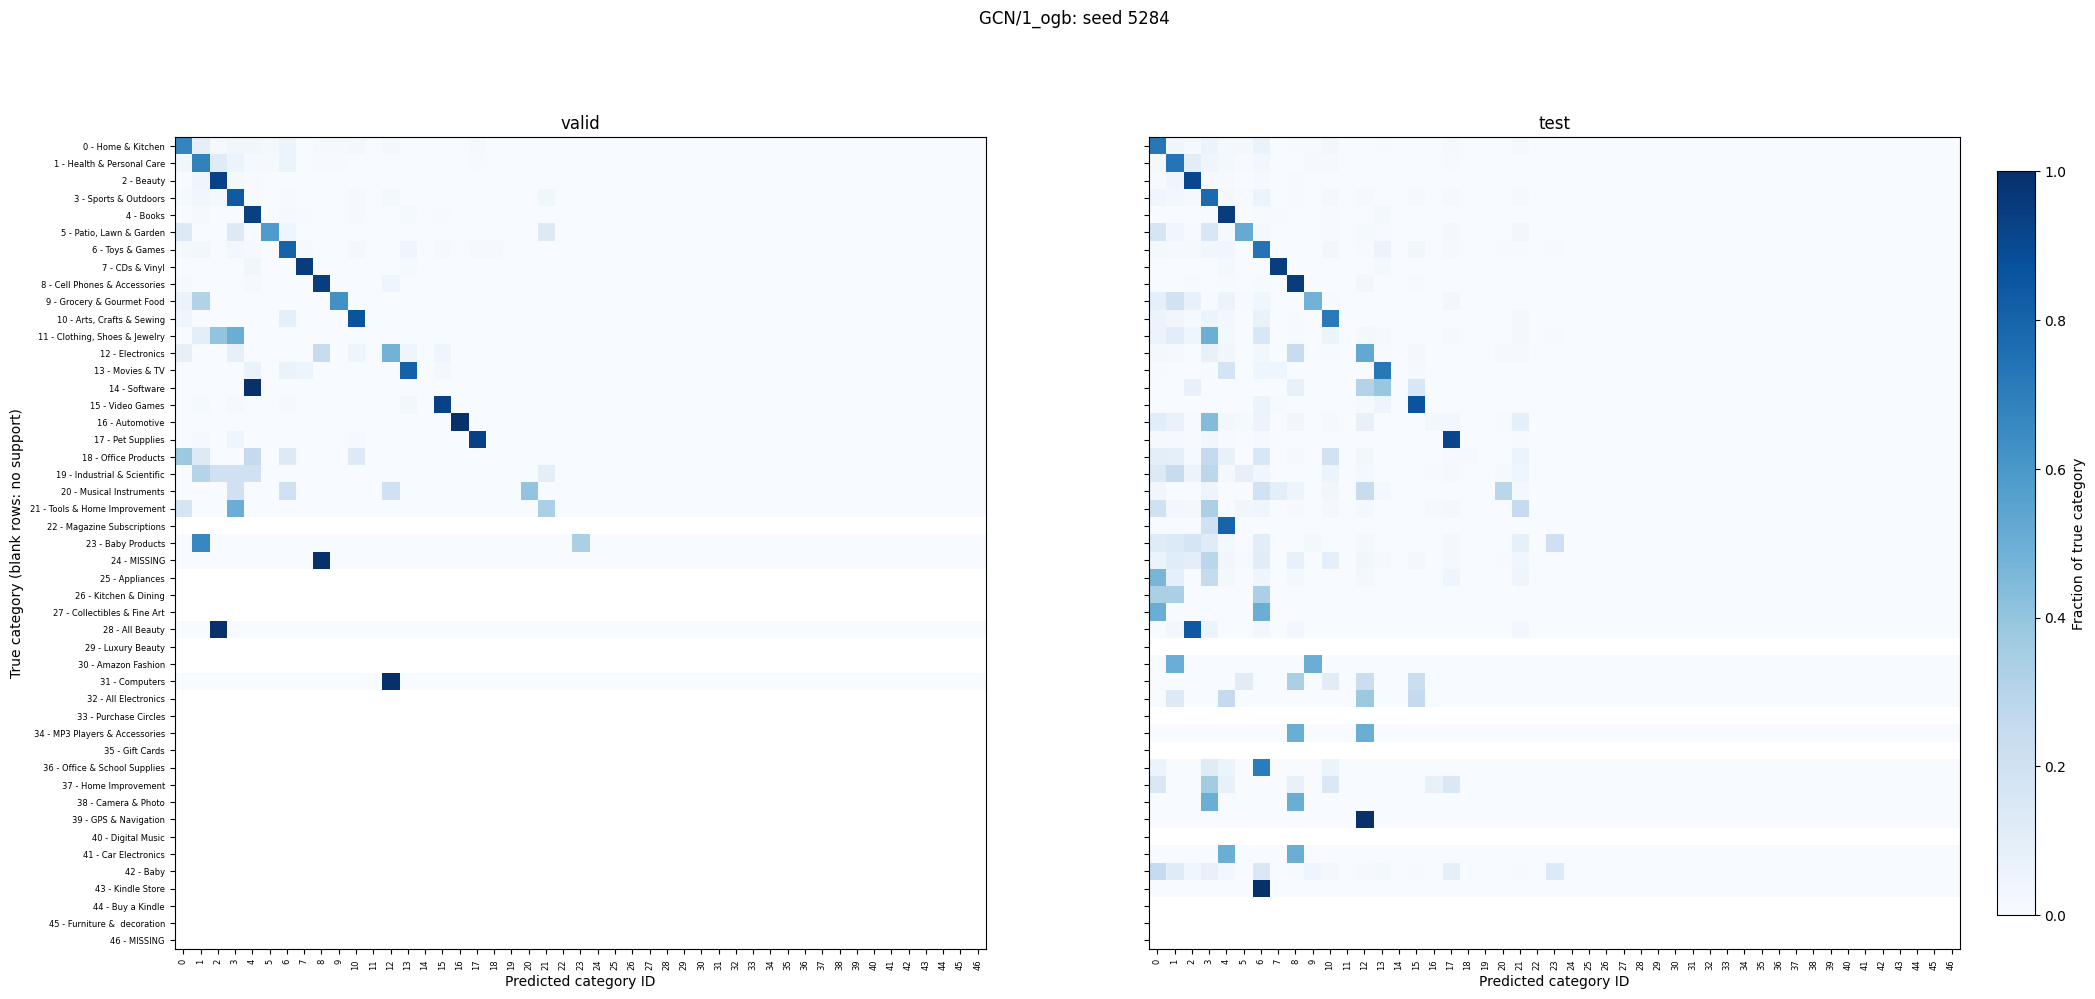

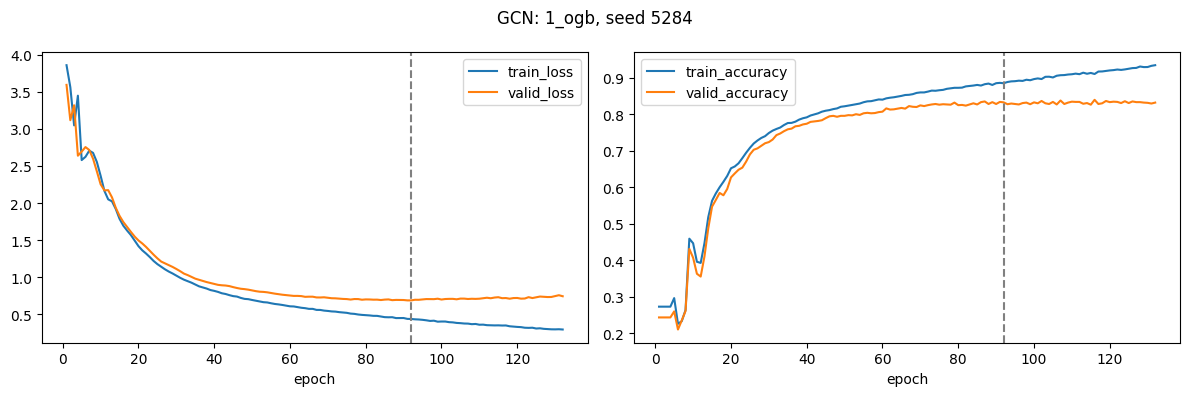

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,1_ogb,5284,92,100,train,0.885097,0.468872,0.329208,0.456175,14708
1,GCN,1_ogb,5284,92,100,valid,0.832697,0.547480,0.302861,0.540034,1572
2,GCN,1_ogb,5284,92,100,test,0.681415,0.282589,0.240502,0.305743,37745


GCN/1_ogb epoch 1: train 3.8279, valid 3.5761, accuracy {'train': 0.2731846570968628, 'valid': 0.2442748099565506}
GCN/1_ogb epoch 10: train 2.2767, valid 2.1566, accuracy {'train': 0.4232390522956848, 'valid': 0.3918575048446655}
GCN/1_ogb epoch 20: train 1.3261, valid 1.3772, accuracy {'train': 0.6736469864845276, 'valid': 0.6685750484466553}
GCN/1_ogb epoch 30: train 0.9623, valid 1.0273, accuracy {'train': 0.7631900906562805, 'valid': 0.7468193173408508}
GCN/1_ogb epoch 40: train 0.7760, valid 0.8745, accuracy {'train': 0.8028283715248108, 'valid': 0.7792620658874512}
GCN/1_ogb epoch 50: train 0.6642, valid 0.7823, accuracy {'train': 0.828120768070221, 'valid': 0.8027989864349365}
GCN/1_ogb epoch 60: train 0.5921, valid 0.7382, accuracy {'train': 0.8472260236740112, 'valid': 0.8148854970932007}
GCN/1_ogb epoch 70: train 0.5312, valid 0.7092, accuracy {'train': 0.8611639738082886, 'valid': 0.822519063949585}
GCN/1_ogb epoch 80: train 0.4819, valid 0.6922, accuracy {'train': 0.874218

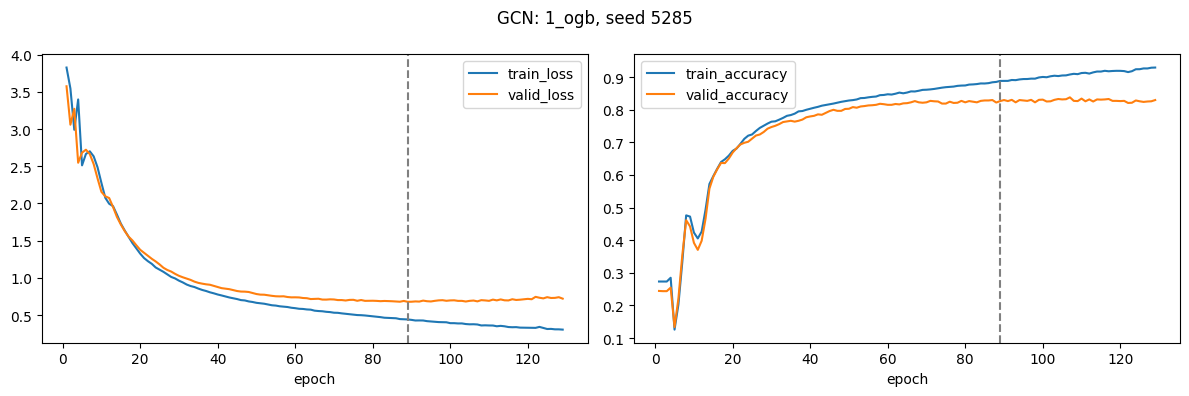

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,1_ogb,5285,89,100,train,0.888156,0.471236,0.330868,0.454483,14708
1,GCN,1_ogb,5285,89,100,valid,0.826336,0.543313,0.300556,0.546244,1572
2,GCN,1_ogb,5285,89,100,test,0.677679,0.279759,0.238092,0.305747,37745


GCN/1_ogb epoch 1: train 3.8950, valid 3.6397, accuracy {'train': 0.21022573113441467, 'valid': 0.2054707407951355}
GCN/1_ogb epoch 10: train 1.8940, valid 1.8686, accuracy {'train': 0.5435817241668701, 'valid': 0.5241730213165283}
GCN/1_ogb epoch 20: train 1.1146, valid 1.2034, accuracy {'train': 0.7310987114906311, 'valid': 0.7131043076515198}
GCN/1_ogb epoch 30: train 0.8332, valid 0.9102, accuracy {'train': 0.7961653470993042, 'valid': 0.775445282459259}
GCN/1_ogb epoch 40: train 0.6907, valid 0.7917, accuracy {'train': 0.8256050944328308, 'valid': 0.8021628260612488}
GCN/1_ogb epoch 50: train 0.6029, valid 0.7356, accuracy {'train': 0.8443024158477783, 'valid': 0.8123409748077393}
GCN/1_ogb epoch 60: train 0.5396, valid 0.6995, accuracy {'train': 0.8618438839912415, 'valid': 0.8231552243232727}
GCN/1_ogb epoch 70: train 0.4843, valid 0.6847, accuracy {'train': 0.8751699924468994, 'valid': 0.8288804292678833}
GCN/1_ogb epoch 80: train 0.4367, valid 0.6741, accuracy {'train': 0.8887

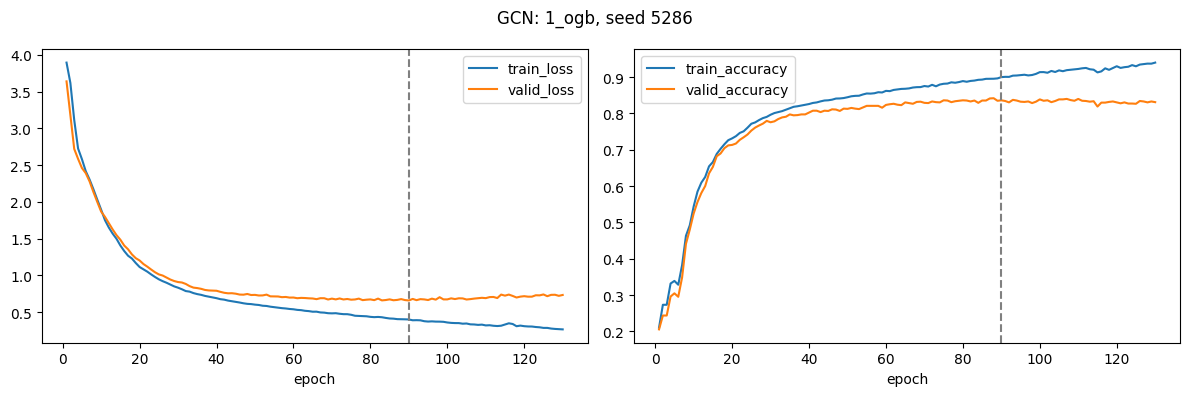

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,1_ogb,5286,90,100,train,0.899646,0.509588,0.357796,0.487082,14708
1,GCN,1_ogb,5286,90,100,valid,0.835878,0.543412,0.300611,0.553234,1572
2,GCN,1_ogb,5286,90,100,test,0.682845,0.288058,0.245156,0.311719,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.680646  0.002667     3         0.283469  0.004219     3   
train  0.890966  0.007671     3         0.483232  0.022855     3   
valid  0.831637  0.004859     3         0.544735  0.002377     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.307736  0.003449     3  
train          0.465913  0.018352     3  
valid          0.546504  0.006604     3

In [14]:
gcn_1_ogb = train_condition('GCN', '1_ogb')


## Run 2: OGB features + raw degree

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GCN/2_ogb_degree epoch 1: train 3.8162, valid 3.5062, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/2_ogb_degree epoch 10: train 1.8409, valid 1.8024, accuracy {'train': 0.5505847334861755, 'valid': 0.5286259651184082}
GCN/2_ogb_degree epoch 20: train 1.0799, valid 1.0902, accuracy {'train': 0.7465324997901917, 'valid': 0.7404580116271973}
GCN/2_ogb_degree epoch 30: train 0.8139, valid 0.8716, accuracy {'train': 0.7933777570724487, 'valid': 0.7703562378883362}
GCN/2_ogb_degree epoch 40: train 0.6921, valid 0.7878, accuracy {'train': 0.8218656778335571, 'valid': 0.8034350872039795}
GCN/2_ogb_degree epoch 50: train 0.6189, valid 0.7463, accuracy {'train': 0.8400870561599731, 'valid': 0.8072519302368164}
GCN/2_ogb_degree epoch 60: train 0.5577, valid 0.7195, accuracy {'train': 0.8553848266601562, 'valid': 0.8187022805213928}
GCN/2_ogb_degree epoch 70: train 0.5049, valid 0.6899, accuracy {'train': 0.8673511147499084, 'valid': 0.8231552243232727}
GCN/2_ogb_degre

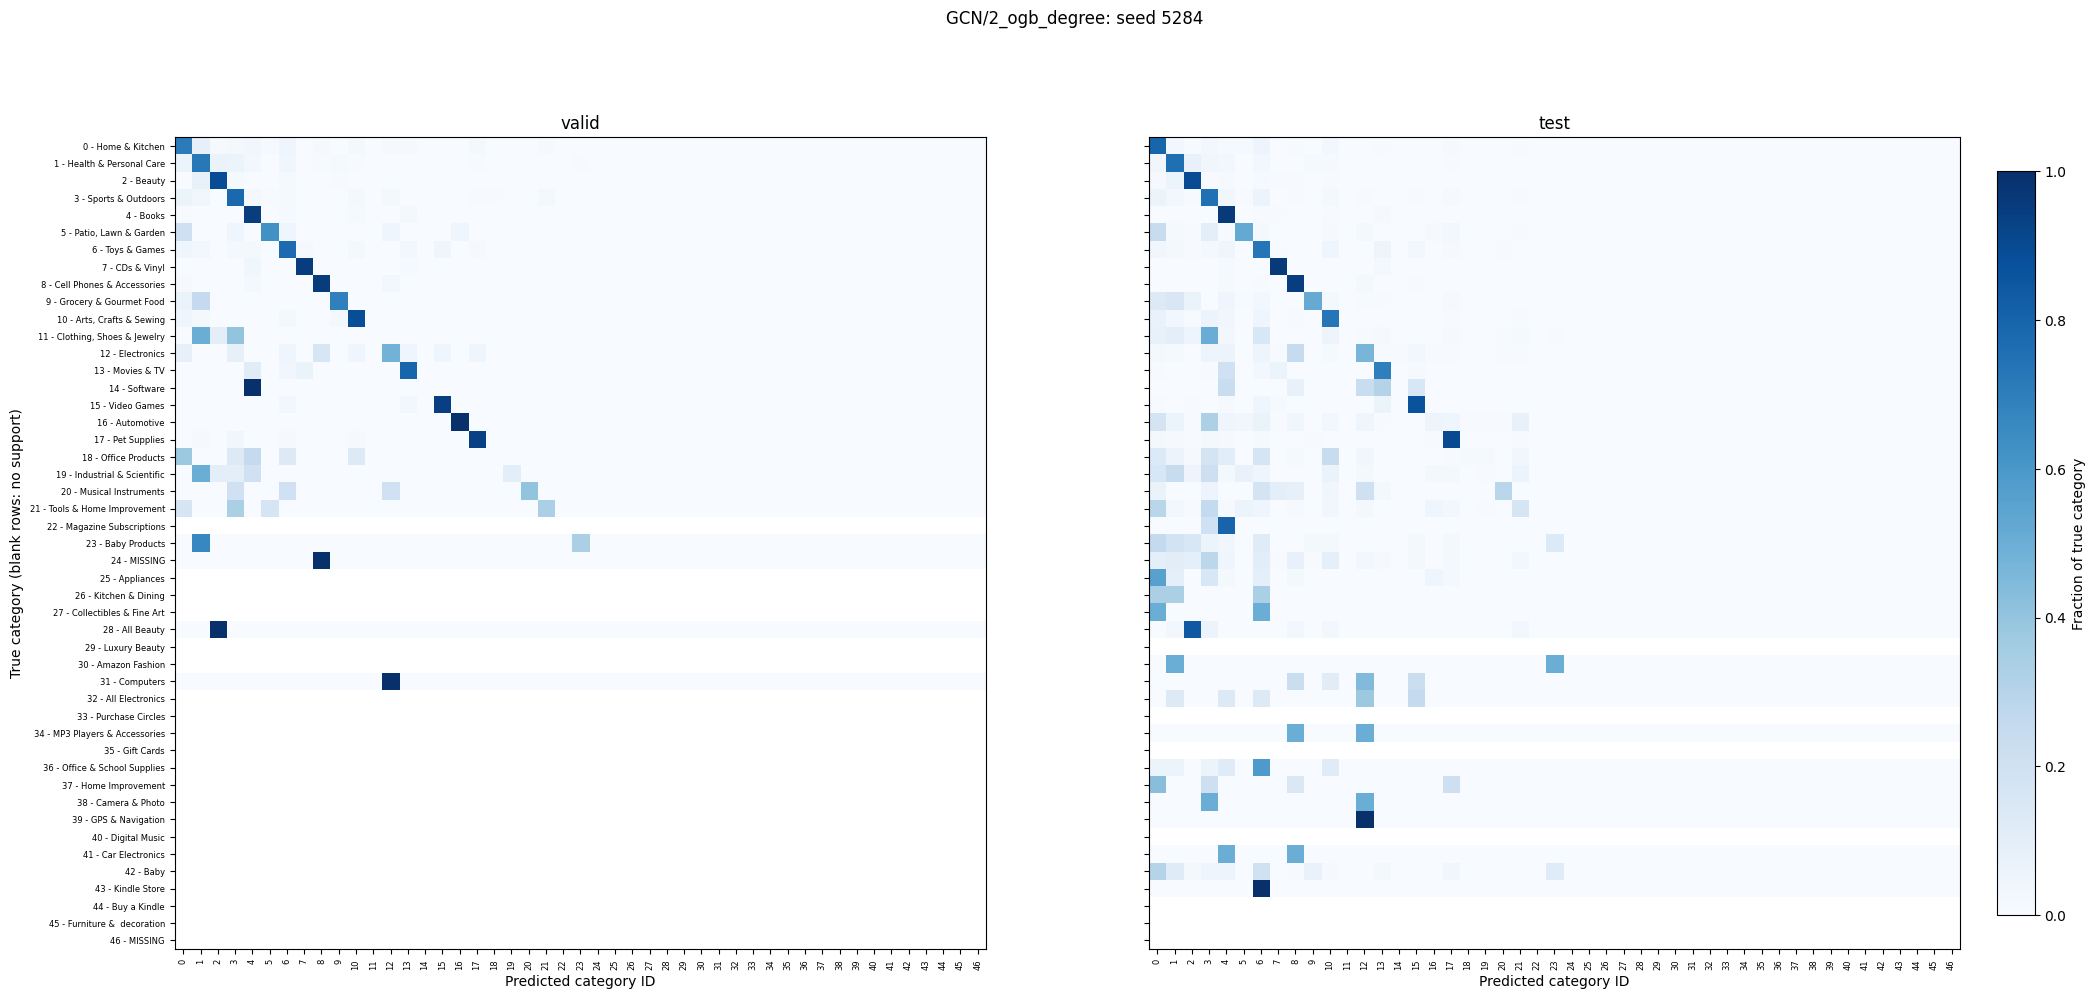

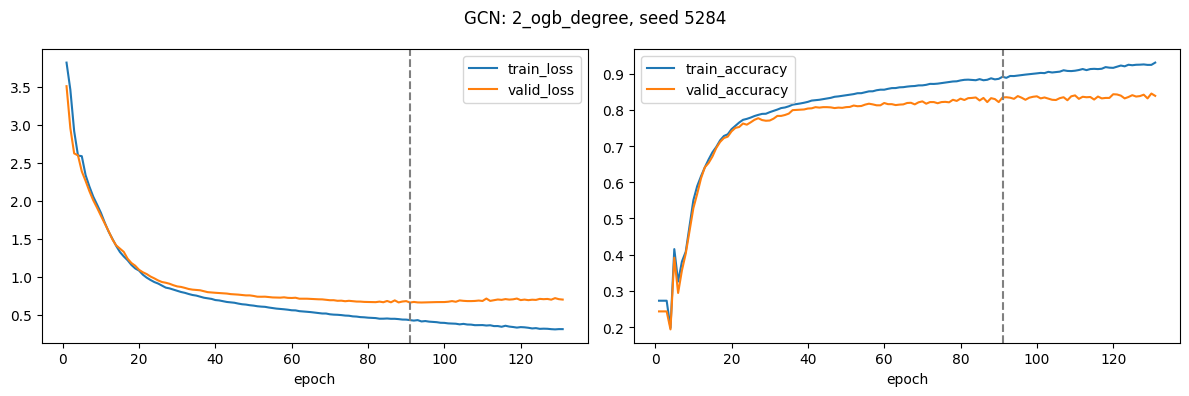

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,2_ogb_degree,5284,91,101,train,0.891012,0.525419,0.368911,0.496362,14708
1,GCN,2_ogb_degree,5284,91,101,valid,0.833969,0.543302,0.300550,0.547408,1572
2,GCN,2_ogb_degree,5284,91,101,test,0.676301,0.280014,0.238310,0.303647,37745


GCN/2_ogb_degree epoch 1: train 3.8253, valid 3.5278, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/2_ogb_degree epoch 10: train 2.0429, valid 2.0241, accuracy {'train': 0.4366331100463867, 'valid': 0.40839695930480957}
GCN/2_ogb_degree epoch 20: train 1.1408, valid 1.2037, accuracy {'train': 0.7292630076408386, 'valid': 0.7194656729698181}
GCN/2_ogb_degree epoch 30: train 0.8490, valid 0.9345, accuracy {'train': 0.788754403591156, 'valid': 0.7633587718009949}
GCN/2_ogb_degree epoch 40: train 0.7019, valid 0.8306, accuracy {'train': 0.8221375942230225, 'valid': 0.8002544641494751}
GCN/2_ogb_degree epoch 50: train 0.6145, valid 0.7606, accuracy {'train': 0.8410388827323914, 'valid': 0.8110687136650085}
GCN/2_ogb_degree epoch 60: train 0.5437, valid 0.7240, accuracy {'train': 0.8585803508758545, 'valid': 0.8187022805213928}
GCN/2_ogb_degree epoch 70: train 0.4913, valid 0.6986, accuracy {'train': 0.8734702467918396, 'valid': 0.8288804292678833}
GCN/2_ogb_degre

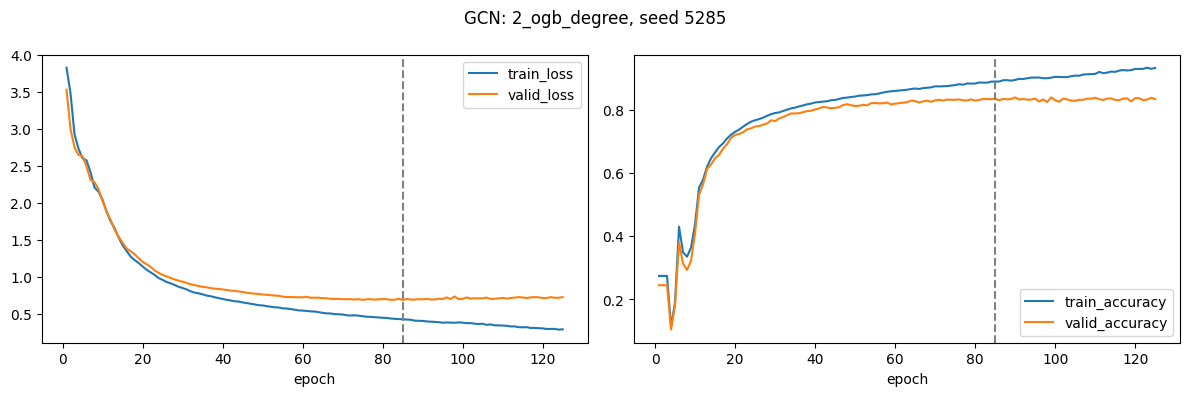

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,2_ogb_degree,5285,85,101,train,0.888768,0.496639,0.348704,0.473453,14708
1,GCN,2_ogb_degree,5285,85,101,valid,0.834606,0.541694,0.299660,0.536806,1572
2,GCN,2_ogb_degree,5285,85,101,test,0.681097,0.283360,0.241158,0.308674,37745


GCN/2_ogb_degree epoch 1: train 3.8186, valid 3.4615, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/2_ogb_degree epoch 10: train 1.7815, valid 1.8315, accuracy {'train': 0.5580636262893677, 'valid': 0.5311704874038696}
GCN/2_ogb_degree epoch 20: train 1.0670, valid 1.1052, accuracy {'train': 0.7491161227226257, 'valid': 0.7366412281990051}
GCN/2_ogb_degree epoch 30: train 0.8137, valid 0.8920, accuracy {'train': 0.7974571585655212, 'valid': 0.7748091816902161}
GCN/2_ogb_degree epoch 40: train 0.6881, valid 0.7849, accuracy {'train': 0.8258770704269409, 'valid': 0.8034350872039795}
GCN/2_ogb_degree epoch 50: train 0.6004, valid 0.7386, accuracy {'train': 0.8445063829421997, 'valid': 0.8148854970932007}
GCN/2_ogb_degree epoch 60: train 0.5381, valid 0.7092, accuracy {'train': 0.8587843179702759, 'valid': 0.8256997466087341}
GCN/2_ogb_degree epoch 70: train 0.4844, valid 0.6902, accuracy {'train': 0.8729262948036194, 'valid': 0.8346055746078491}
GCN/2_ogb_degre

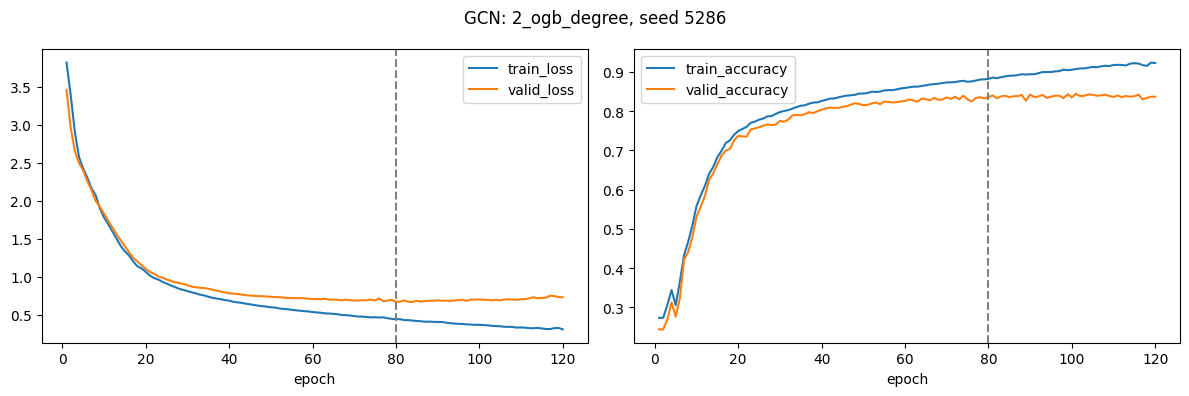

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,2_ogb_degree,5286,80,101,train,0.881901,0.482766,0.338963,0.465169,14708
1,GCN,2_ogb_degree,5286,80,101,valid,0.835242,0.571435,0.316113,0.559541,1572
2,GCN,2_ogb_degree,5286,80,101,test,0.686846,0.288705,0.245706,0.313328,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.681415  0.005279     3         0.284026  0.004384     3   
train  0.887227  0.004747     3         0.501608  0.021756     3   
valid  0.834606  0.000636     3         0.552143  0.016726     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.308549  0.004842     3  
train          0.478328  0.016158     3  
valid          0.547918  0.011376     3

In [15]:
gcn_2_ogb_degree = train_condition('GCN', '2_ogb_degree')


## Run 3: Raw degree only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GCN/3_degree epoch 1: train 3.9075, valid 3.5023, accuracy {'train': 0.21165351569652557, 'valid': 0.18511450290679932}
GCN/3_degree epoch 10: train 2.5894, valid 2.6122, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 20: train 2.5538, valid 2.5888, accuracy {'train': 0.27311667799949646, 'valid': 0.2442748099565506}
GCN/3_degree epoch 30: train 2.5404, valid 2.5786, accuracy {'train': 0.27474844455718994, 'valid': 0.2442748099565506}
GCN/3_degree epoch 40: train 2.5277, valid 2.5666, accuracy {'train': 0.276040256023407, 'valid': 0.24618320167064667}
GCN/3_degree epoch 50: train 2.5204, valid 2.5448, accuracy {'train': 0.2763122022151947, 'valid': 0.24809160828590393}
GCN/3_degree epoch 60: train 2.5101, valid 2.5425, accuracy {'train': 0.2770600914955139, 'valid': 0.24936386942863464}
GCN/3_degree epoch 70: train 2.5027, valid 2.5443, accuracy {'train': 0.27672016620635986, 'valid': 0.24745547771453857}
GCN/3_degree epoch 80: train 2.4951, va

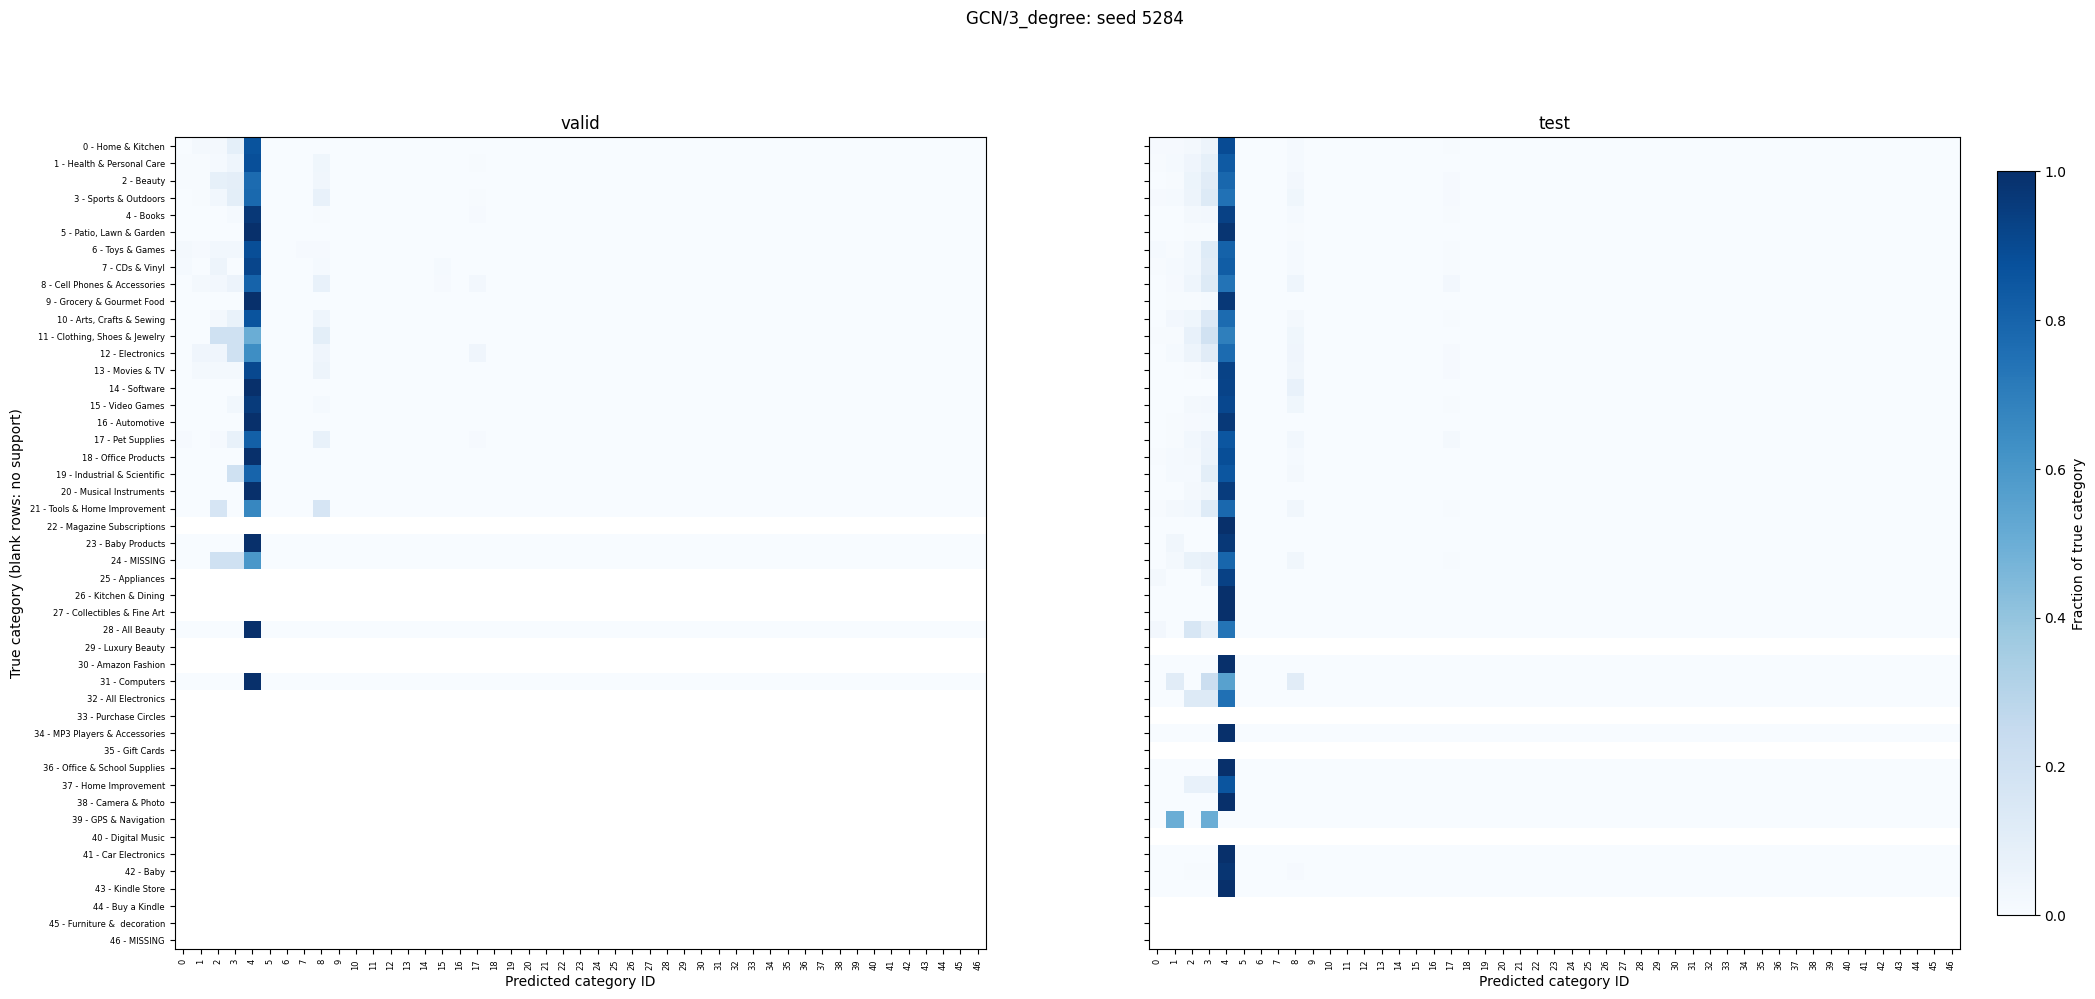

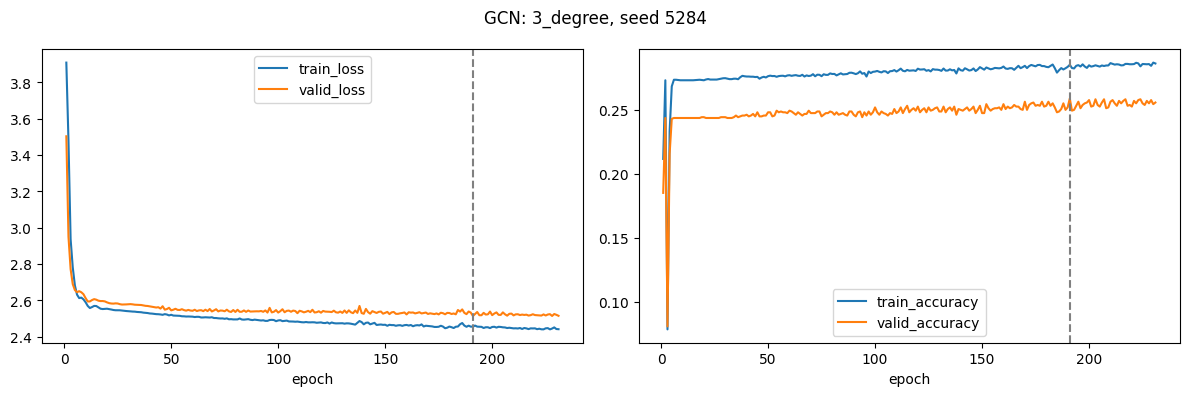

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,3_degree,5284,191,1,train,0.285219,0.031477,0.022101,0.041080,14708
1,GCN,3_degree,5284,191,1,valid,0.258906,0.031235,0.017279,0.047681,1572
2,GCN,3_degree,5284,191,1,test,0.181878,0.016722,0.014232,0.030028,37745


GCN/3_degree epoch 1: train 3.7754, valid 3.0999, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 10: train 2.8188, valid 2.6921, accuracy {'train': 0.0784607008099556, 'valid': 0.08078880608081818}
GCN/3_degree epoch 20: train 2.5680, valid 2.5966, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 30: train 2.5491, valid 2.5886, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 40: train 2.5429, valid 2.5784, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 50: train 2.5338, valid 2.5752, accuracy {'train': 0.27359259128570557, 'valid': 0.24363867938518524}
GCN/3_degree epoch 60: train 2.5235, valid 2.5620, accuracy {'train': 0.2746124565601349, 'valid': 0.24363867938518524}
GCN/3_degree epoch 70: train 2.5179, valid 2.5579, accuracy {'train': 0.2763122022151947, 'valid': 0.24491094052791595}
GCN/3_degree epoch 80: train 2.5109,

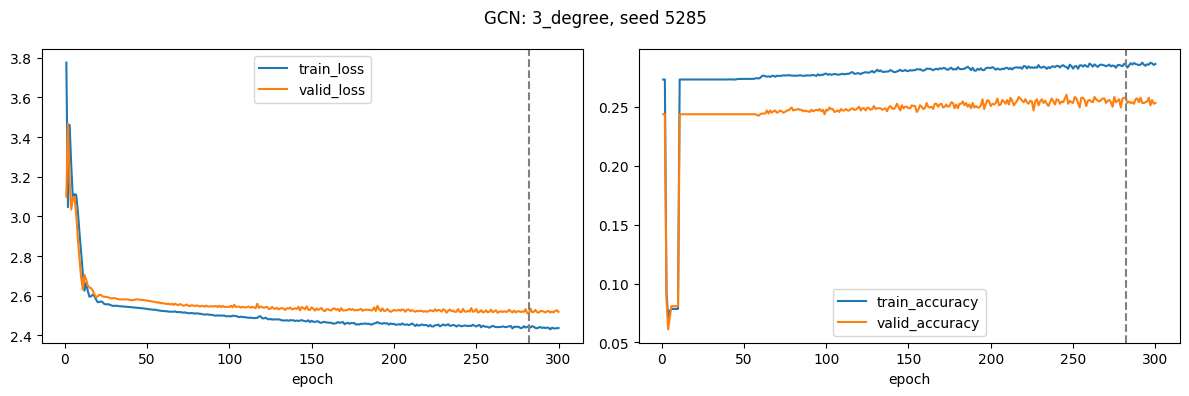

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,3_degree,5285,282,1,train,0.285763,0.032617,0.022901,0.042648,14708
1,GCN,3_degree,5285,282,1,valid,0.257634,0.033322,0.018434,0.049772,1572
2,GCN,3_degree,5285,282,1,test,0.181349,0.017565,0.014949,0.031449,37745


GCN/3_degree epoch 1: train 3.8614, valid 3.3561, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 10: train 2.7310, valid 2.6643, accuracy {'train': 0.22831112146377563, 'valid': 0.2111959308385849}
GCN/3_degree epoch 20: train 2.5732, valid 2.6107, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 30: train 2.5493, valid 2.5847, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 40: train 2.5420, valid 2.5820, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GCN/3_degree epoch 50: train 2.5330, valid 2.5712, accuracy {'train': 0.27379658818244934, 'valid': 0.24363867938518524}
GCN/3_degree epoch 60: train 2.5229, valid 2.5542, accuracy {'train': 0.2753603458404541, 'valid': 0.2455470710992813}
GCN/3_degree epoch 70: train 2.5169, valid 2.5542, accuracy {'train': 0.2755643129348755, 'valid': 0.24363867938518524}
GCN/3_degree epoch 80: train 2.5109, 

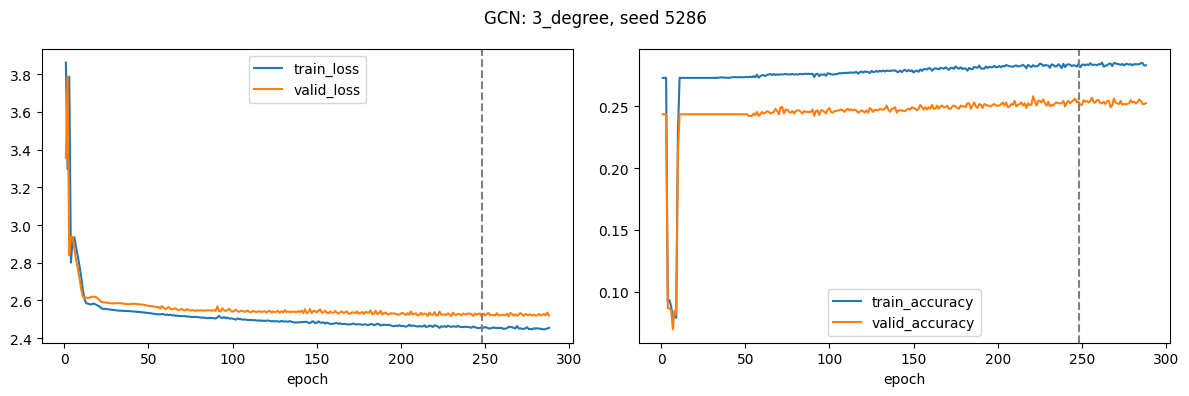

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GCN,3_degree,5286,248,1,train,0.284607,0.029900,0.020993,0.040148,14708
1,GCN,3_degree,5286,248,1,valid,0.253817,0.029903,0.016542,0.046427,1572
2,GCN,3_degree,5286,248,1,test,0.178752,0.015120,0.012868,0.029179,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.180660  0.001673     3         0.016469  0.001242     3   
train  0.285196  0.000578     3         0.031331  0.001364     3   
valid  0.256785  0.002648     3         0.031487  0.001724     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.030219  0.001147     3  
train          0.041292  0.001264     3  
valid          0.047960  0.001690     3

In [16]:
gcn_3_degree = train_condition('GCN', '3_degree')


## Run 4: OGB-only cold start

Reuse run 1 without retraining. Remove all test-incident co-purchase edges and evaluate with the same OGB features. The table compares all four conditions.


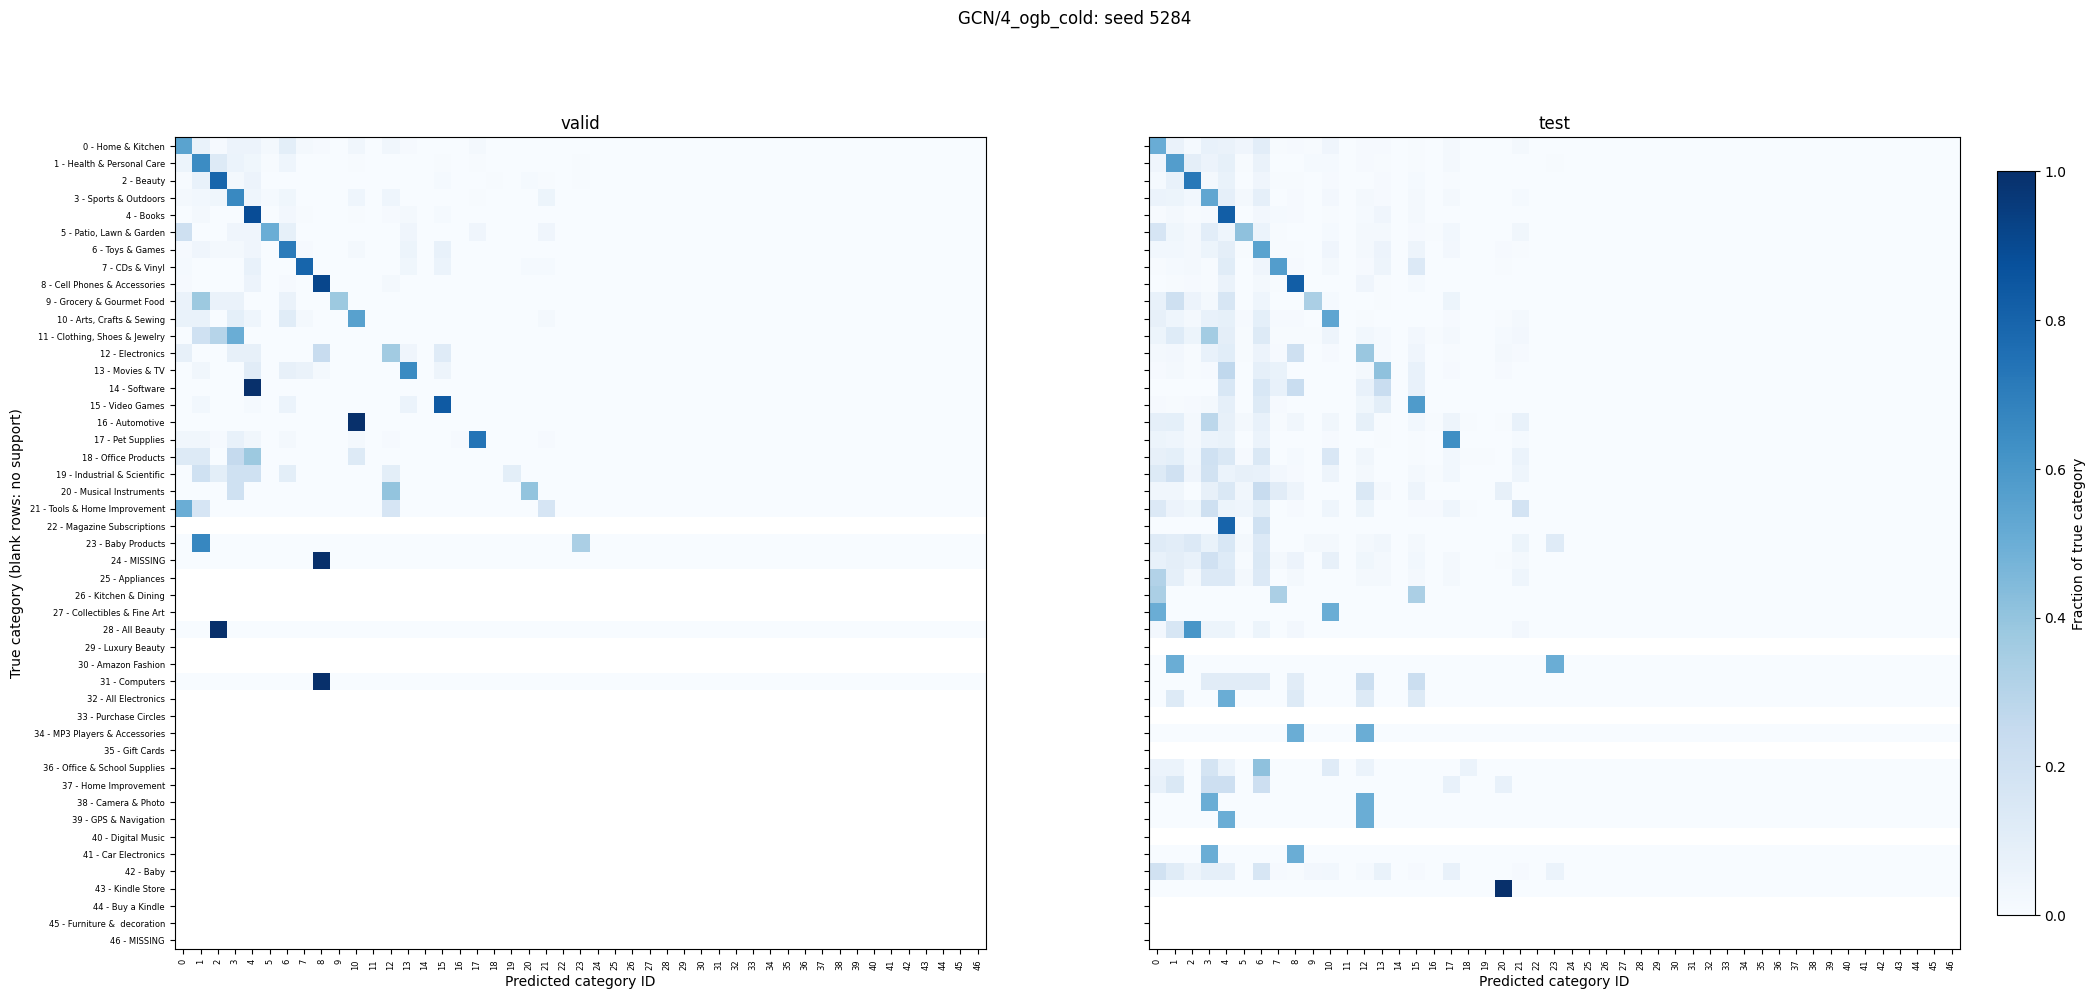

accuracy                 macro_f1_present                  \
                  mean       std count             mean       std count   
condition                                                                 
1_ogb         0.680646  0.002667     3         0.283469  0.004219     3   
2_ogb_degree  0.681415  0.005279     3         0.284026  0.004384     3   
3_degree      0.180660  0.001673     3         0.016469  0.001242     3   
4_ogb_cold    0.511927  0.005003     3         0.202786  0.001798     3   

             balanced_accuracy                  
                          mean       std count  
condition                                       
1_ogb                 0.307736  0.003449     3  
2_ogb_degree          0.308549  0.004842     3  
3_degree              0.030219  0.001147     3  
4_ogb_cold            0.219794  0.000776     3

In [17]:
cold_condition('GCN')


# 2. GraphSAGE

`ProductGraphSAGE` is defined locally below for V2; the shared `src.models.SAGE` class is unchanged. A linear input projection maps 100, 101 or 1 input features to width 128. Four mean-aggregation layers each preserve width 128, apply ReLU, and add the previous hidden representation as a residual. Dropout applies to message-branch inputs, not the identity path.

A separate MLP with two hidden layers predicts 47 category logits, matching the classifier structure of GCN and GAT. Explicit self-loops remain excluded. The added identity residual and SAGEConv's learned self transformation are distinct operations.


In [18]:
class ProductGraphSAGE(nn.Module):
    """V2-only residual GraphSAGE with the same head layout as GCN/GAT."""
    def __init__(self, in_dim, hidden_dim, classes, dropout=0.3,
                 num_layers=4, mlp_hidden_layers=2):
        super().__init__()
        self.dropout = dropout
        self.embedding_h = nn.Linear(in_dim, hidden_dim)
        self.SAGE_layers = nn.ModuleList([
            SAGEConv(hidden_dim, hidden_dim, aggr='mean') for _ in range(num_layers)
        ])
        classifier = []
        for _ in range(mlp_hidden_layers):
            classifier.extend([nn.Linear(hidden_dim, hidden_dim), nn.ReLU()])
        classifier.append(nn.Linear(hidden_dim, classes))
        self.MLP_layer = nn.Sequential(*classifier)

    def forward(self, x, edges):
        h = self.embedding_h(x)
        for layer in self.SAGE_layers:
            h_in = h
            messages = layer(F.dropout(h, p=self.dropout, training=self.training), edges).relu()
            h = h_in + messages
        return self.MLP_layer(h)


In [19]:
import importlib
import inspect
import src.models as models

importlib.reload(models)
SAGE = models.SAGE

print(models.__file__)
print(inspect.signature(SAGE.__init__))

<repo>\src\models.py
(self, in_dim, hidden_dim, num_classes, dropout=0.5, num_layers=2)


## Run 1: OGB 100-dimensional features only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GraphSAGE/1_ogb epoch 1: train 3.9025, valid 3.4298, accuracy {'train': 0.28025564551353455, 'valid': 0.25}
GraphSAGE/1_ogb epoch 10: train 2.2861, valid 2.1683, accuracy {'train': 0.38598042726516724, 'valid': 0.37277352809906006}
GraphSAGE/1_ogb epoch 20: train 1.4496, valid 1.4964, accuracy {'train': 0.6405357718467712, 'valid': 0.597328245639801}
GraphSAGE/1_ogb epoch 30: train 1.0190, valid 1.0339, accuracy {'train': 0.7550992369651794, 'valid': 0.7391857504844666}
GraphSAGE/1_ogb epoch 40: train 0.7989, valid 0.8554, accuracy {'train': 0.801128625869751, 'valid': 0.7919847369194031}
GraphSAGE/1_ogb epoch 50: train 0.6761, valid 0.7854, accuracy {'train': 0.829412579536438, 'valid': 0.8085241913795471}
GraphSAGE/1_ogb epoch 60: train 0.5814, valid 0.7518, accuracy {'train': 0.855452835559845, 'valid': 0.8155216574668884}
GraphSAGE/1_ogb epoch 70: train 0.5056, valid 0.7179, accuracy {'train': 0.8751699924468994, 'valid': 0.8206107020378113}
GraphSAGE/1_ogb epoch 80: train 0.4441, 

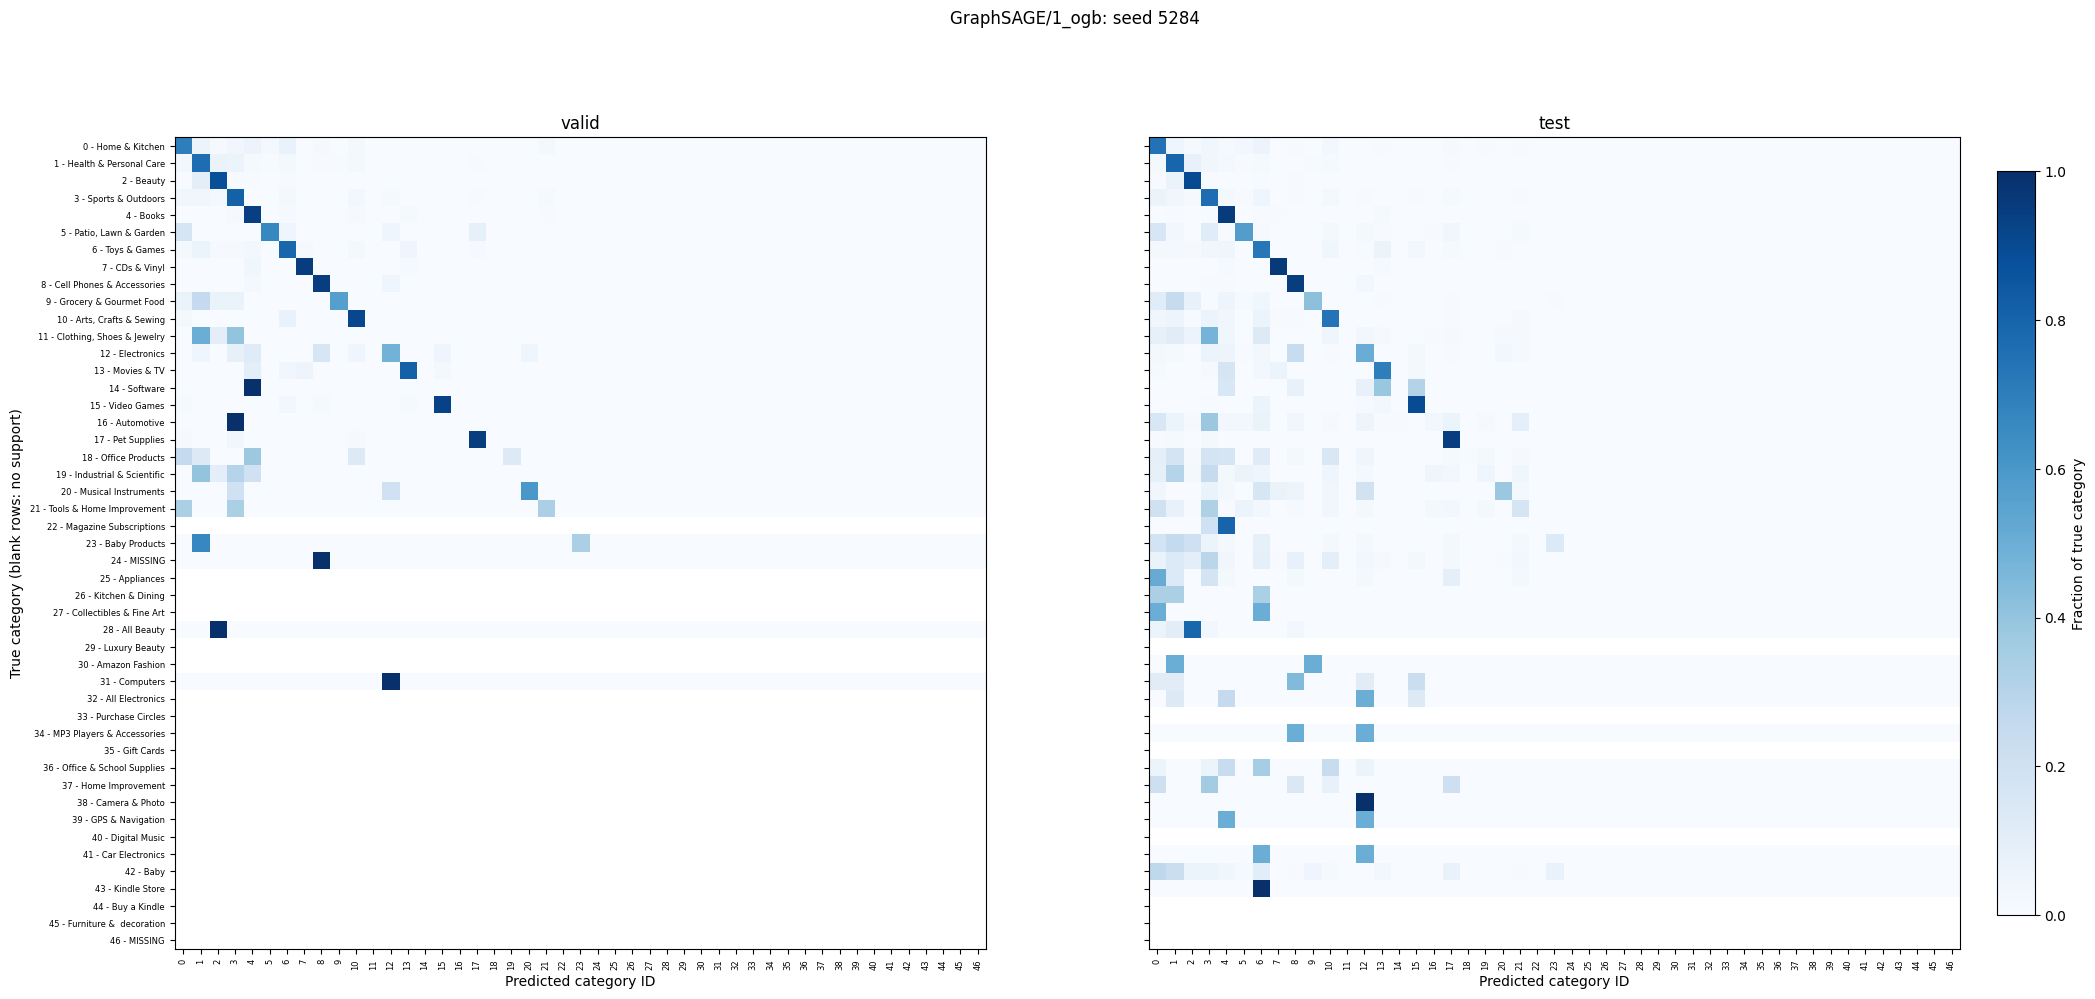

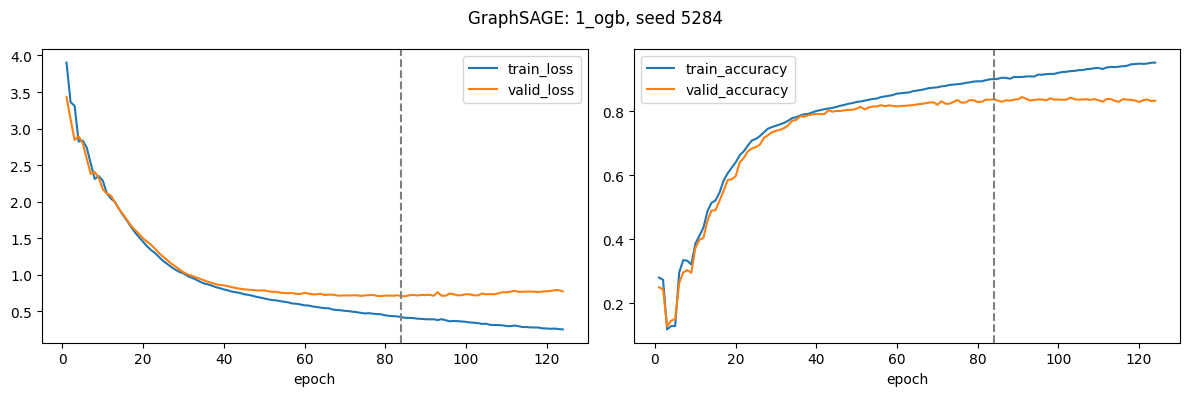

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,1_ogb,5284,84,100,train,0.900530,0.491644,0.345197,0.470590,14708
1,GraphSAGE,1_ogb,5284,84,100,valid,0.837786,0.520509,0.287941,0.513310,1572
2,GraphSAGE,1_ogb,5284,84,100,test,0.682183,0.282820,0.240698,0.308002,37745


GraphSAGE/1_ogb epoch 1: train 3.8688, valid 3.3935, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/1_ogb epoch 10: train 2.2996, valid 2.3593, accuracy {'train': 0.2958934009075165, 'valid': 0.2671755850315094}
GraphSAGE/1_ogb epoch 20: train 1.4810, valid 1.5223, accuracy {'train': 0.6108920574188232, 'valid': 0.5966920852661133}
GraphSAGE/1_ogb epoch 30: train 1.0852, valid 1.1350, accuracy {'train': 0.7290590405464172, 'valid': 0.703562319278717}
GraphSAGE/1_ogb epoch 40: train 0.8488, valid 0.9056, accuracy {'train': 0.7865107655525208, 'valid': 0.7735369205474854}
GraphSAGE/1_ogb epoch 50: train 0.7036, valid 0.7961, accuracy {'train': 0.8229535222053528, 'valid': 0.8021628260612488}
GraphSAGE/1_ogb epoch 60: train 0.6048, valid 0.7307, accuracy {'train': 0.8461381793022156, 'valid': 0.8244274854660034}
GraphSAGE/1_ogb epoch 70: train 0.5333, valid 0.7160, accuracy {'train': 0.8677590489387512, 'valid': 0.8352417349815369}
GraphSAGE/1_ogb epoch 80

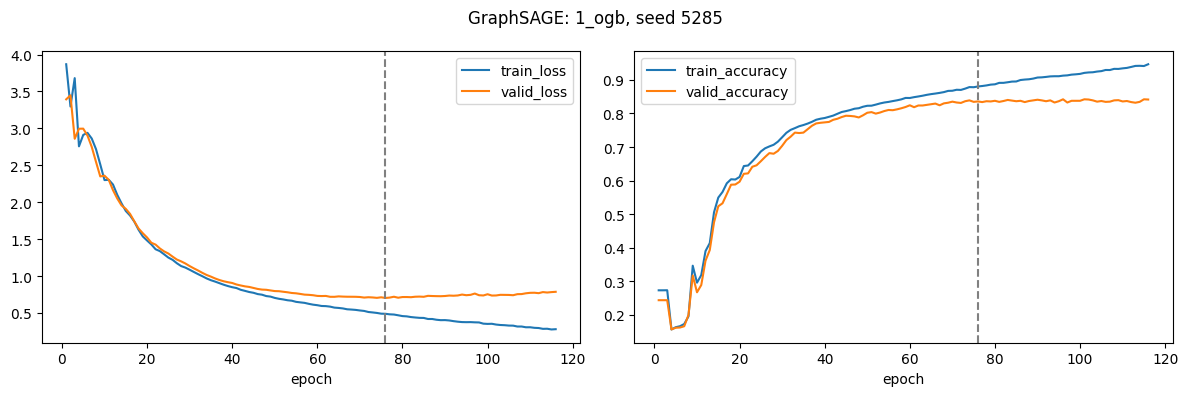

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,1_ogb,5285,76,100,train,0.880473,0.454685,0.319247,0.441252,14708
1,GraphSAGE,1_ogb,5285,76,100,valid,0.835878,0.522650,0.289126,0.516123,1572
2,GraphSAGE,1_ogb,5285,76,100,test,0.676566,0.278065,0.236651,0.301594,37745


GraphSAGE/1_ogb epoch 1: train 3.8918, valid 3.4184, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/1_ogb epoch 10: train 2.2103, valid 2.1226, accuracy {'train': 0.38890400528907776, 'valid': 0.35687023401260376}
GraphSAGE/1_ogb epoch 20: train 1.3896, valid 1.3648, accuracy {'train': 0.6586211323738098, 'valid': 0.6418575048446655}
GraphSAGE/1_ogb epoch 30: train 0.9888, valid 1.0205, accuracy {'train': 0.7624422311782837, 'valid': 0.7442747950553894}
GraphSAGE/1_ogb epoch 40: train 0.7947, valid 0.8564, accuracy {'train': 0.8006526827812195, 'valid': 0.7856234312057495}
GraphSAGE/1_ogb epoch 50: train 0.6726, valid 0.7762, accuracy {'train': 0.8319281935691833, 'valid': 0.8008905649185181}
GraphSAGE/1_ogb epoch 60: train 0.5827, valid 0.7258, accuracy {'train': 0.8547049164772034, 'valid': 0.8148854970932007}
GraphSAGE/1_ogb epoch 70: train 0.5133, valid 0.7092, accuracy {'train': 0.8728582859039307, 'valid': 0.830788791179657}
GraphSAGE/1_ogb epoch 

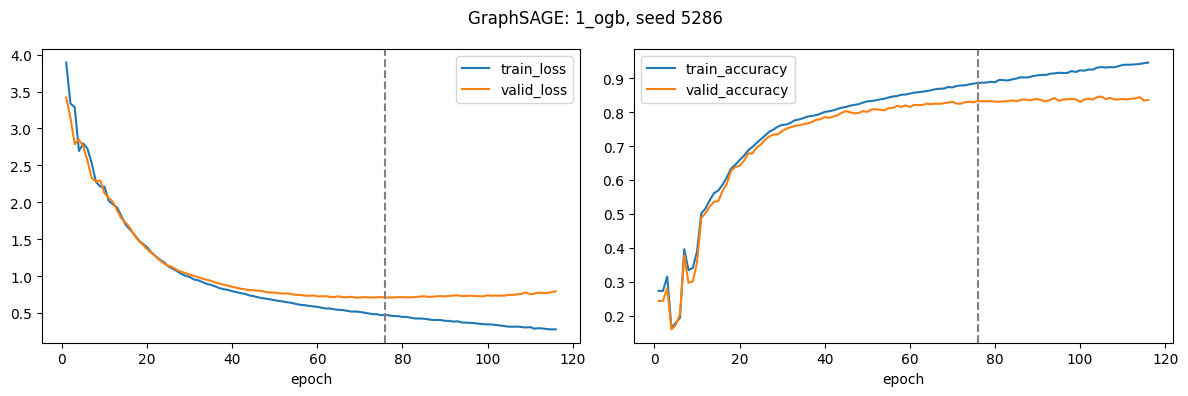

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,1_ogb,5286,76,100,train,0.885504,0.456174,0.320293,0.443698,14708
1,GraphSAGE,1_ogb,5286,76,100,valid,0.832697,0.502212,0.277820,0.490109,1572
2,GraphSAGE,1_ogb,5286,76,100,test,0.679004,0.277709,0.236348,0.303461,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.679251  0.002816     3         0.279531  0.002854     3   
train  0.888836  0.010435     3         0.467501  0.020921     3   
valid  0.835454  0.002571     3         0.515124  0.011233     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.304352  0.003296     3  
train          0.451847  0.016278     3  
valid          0.506514  0.014277     3

In [20]:
graphsage_1_ogb = train_condition('GraphSAGE', '1_ogb')


## Run 2: OGB features + raw degree

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


In [21]:
print('hi')

hi


GraphSAGE/2_ogb_degree epoch 1: train 3.8619, valid 3.2833, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/2_ogb_degree epoch 10: train 2.7288, valid 2.5569, accuracy {'train': 0.19010062515735626, 'valid': 0.20483461022377014}
GraphSAGE/2_ogb_degree epoch 20: train 1.7024, valid 1.7699, accuracy {'train': 0.581724226474762, 'valid': 0.5693384408950806}
GraphSAGE/2_ogb_degree epoch 30: train 1.2109, valid 1.3043, accuracy {'train': 0.6911205053329468, 'valid': 0.6787531971931458}
GraphSAGE/2_ogb_degree epoch 40: train 0.9392, valid 1.0030, accuracy {'train': 0.7656377553939819, 'valid': 0.7646310329437256}
GraphSAGE/2_ogb_degree epoch 50: train 0.7641, valid 0.8378, accuracy {'train': 0.8072477579116821, 'valid': 0.7894402146339417}
GraphSAGE/2_ogb_degree epoch 60: train 0.6545, valid 0.7748, accuracy {'train': 0.8351917266845703, 'valid': 0.8085241913795471}
GraphSAGE/2_ogb_degree epoch 70: train 0.5647, valid 0.7275, accuracy {'train': 0.8603481054306

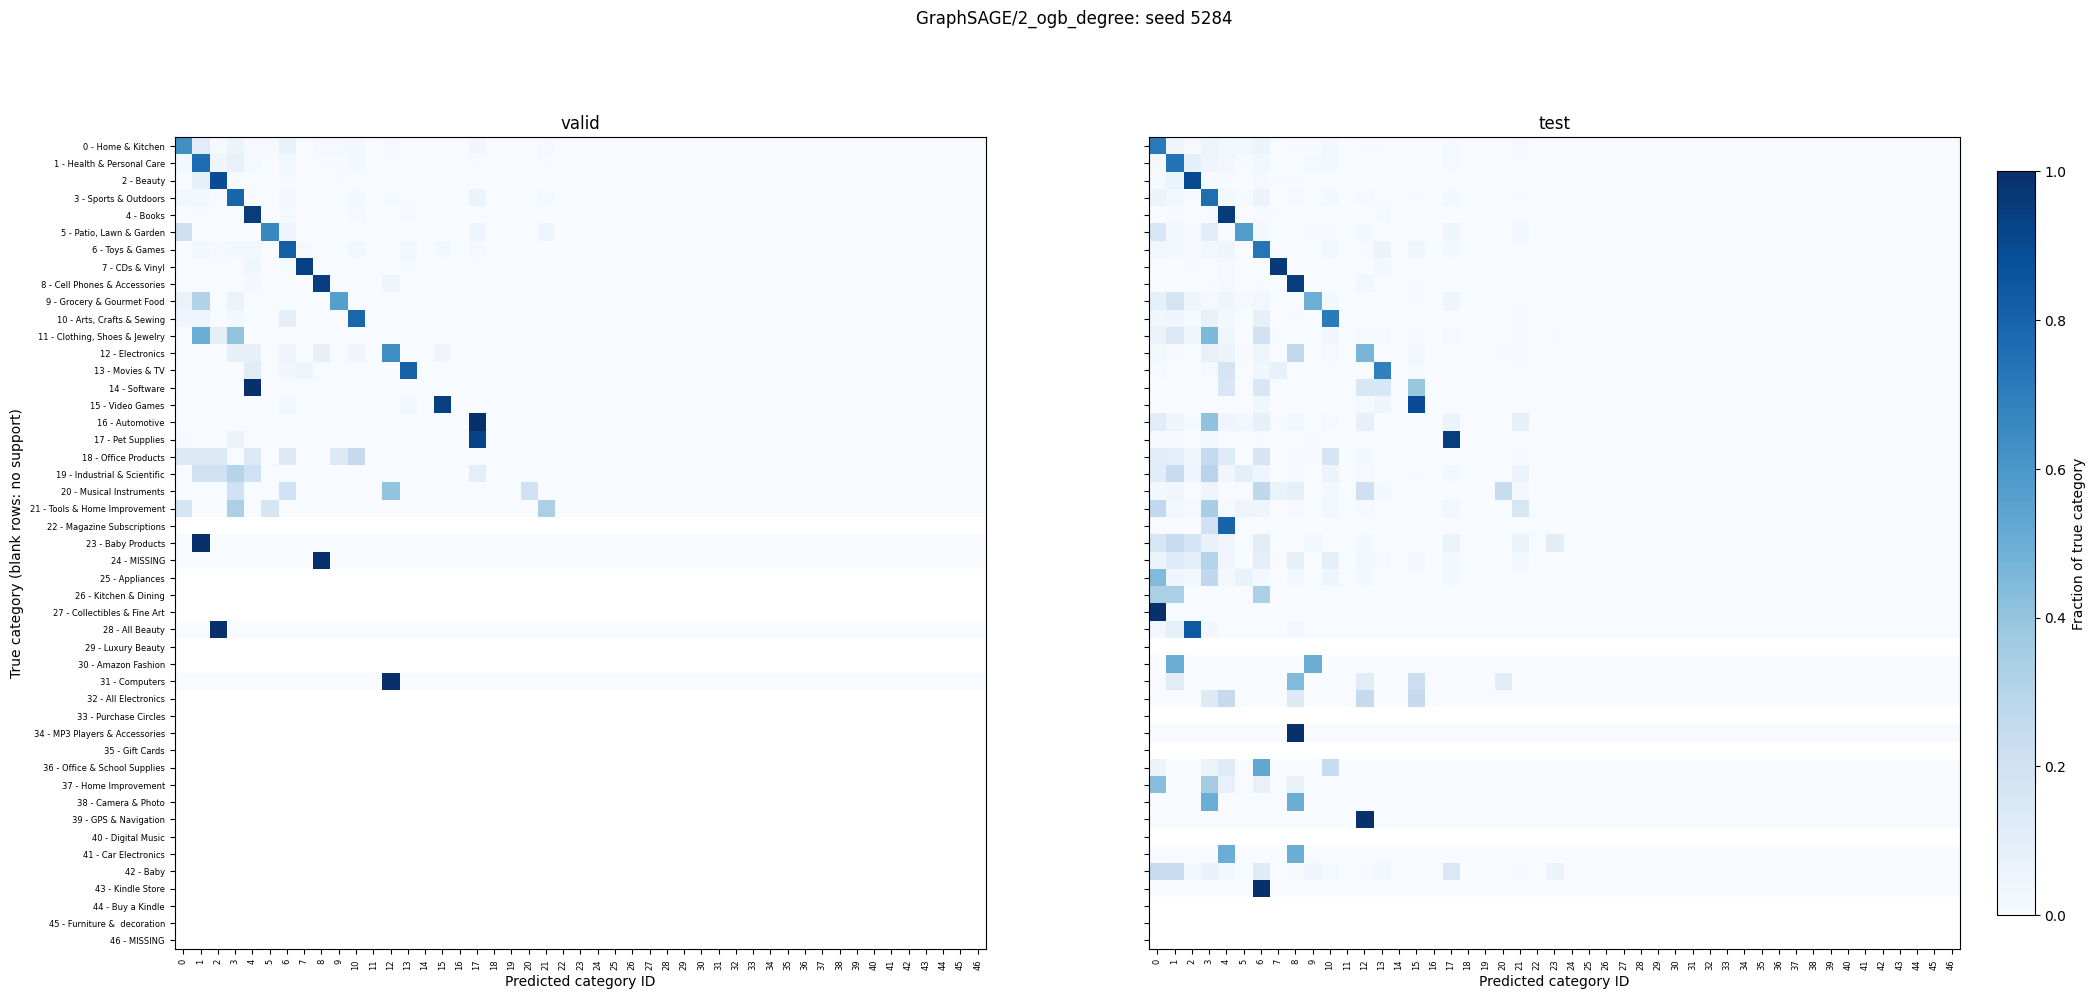

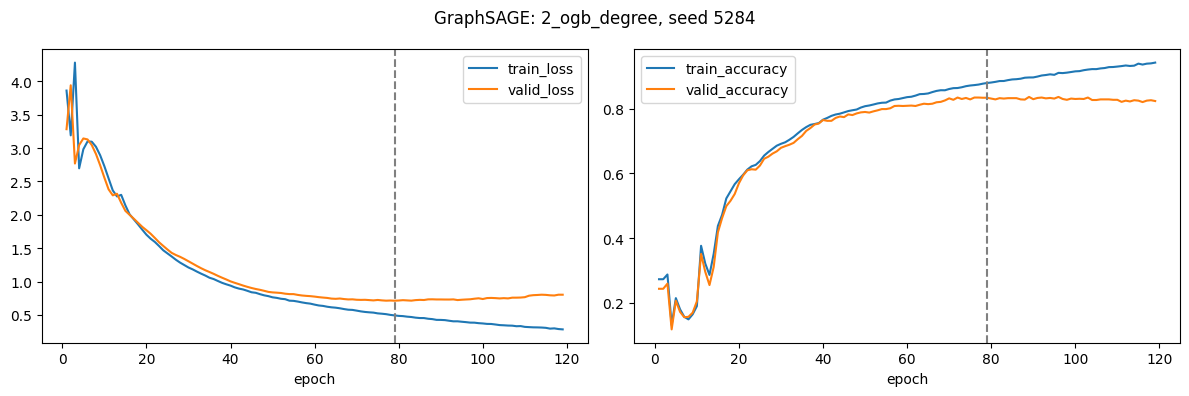

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,2_ogb_degree,5284,79,101,train,0.878841,0.438182,0.307660,0.427495,14708
1,GraphSAGE,2_ogb_degree,5284,79,101,valid,0.833333,0.485230,0.268425,0.484337,1572
2,GraphSAGE,2_ogb_degree,5284,79,101,test,0.671109,0.275014,0.234054,0.299366,37745


GraphSAGE/2_ogb_degree epoch 1: train 3.8601, valid 3.3066, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/2_ogb_degree epoch 10: train 2.3106, valid 2.2537, accuracy {'train': 0.3925754725933075, 'valid': 0.3823155164718628}
GraphSAGE/2_ogb_degree epoch 20: train 1.5052, valid 1.5264, accuracy {'train': 0.6276856064796448, 'valid': 0.6138677000999451}
GraphSAGE/2_ogb_degree epoch 30: train 1.0383, valid 1.1033, accuracy {'train': 0.7483002543449402, 'valid': 0.7290076613426208}
GraphSAGE/2_ogb_degree epoch 40: train 0.7988, valid 0.8224, accuracy {'train': 0.7998368144035339, 'valid': 0.7913485765457153}
GraphSAGE/2_ogb_degree epoch 50: train 0.6698, valid 0.7466, accuracy {'train': 0.8295485377311707, 'valid': 0.8129770755767822}
GraphSAGE/2_ogb_degree epoch 60: train 0.5783, valid 0.6948, accuracy {'train': 0.8540930151939392, 'valid': 0.821882963180542}
GraphSAGE/2_ogb_degree epoch 70: train 0.4980, valid 0.6696, accuracy {'train': 0.875033974647522

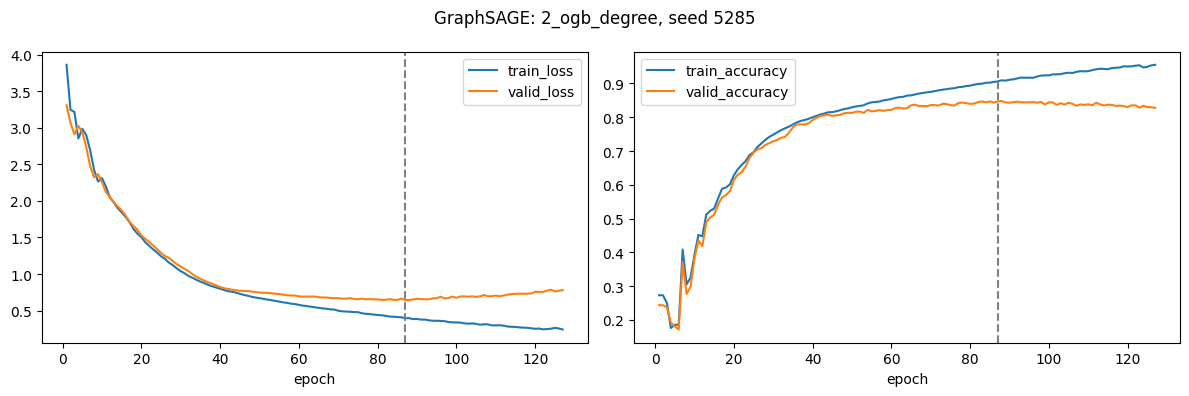

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,2_ogb_degree,5285,87,101,train,0.906106,0.508046,0.356713,0.487771,14708
1,GraphSAGE,2_ogb_degree,5285,87,101,valid,0.846692,0.527998,0.292084,0.530269,1572
2,GraphSAGE,2_ogb_degree,5285,87,101,test,0.683561,0.283817,0.241546,0.314026,37745


GraphSAGE/2_ogb_degree epoch 1: train 3.8086, valid 3.1167, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/2_ogb_degree epoch 10: train 2.7153, valid 2.5457, accuracy {'train': 0.20635028183460236, 'valid': 0.19783714413642883}
GraphSAGE/2_ogb_degree epoch 20: train 1.7750, valid 1.8181, accuracy {'train': 0.5093146562576294, 'valid': 0.47201016545295715}
GraphSAGE/2_ogb_degree epoch 30: train 1.2085, valid 1.2066, accuracy {'train': 0.6910524964332581, 'valid': 0.6825699806213379}
GraphSAGE/2_ogb_degree epoch 40: train 0.9210, valid 0.9603, accuracy {'train': 0.7665895819664001, 'valid': 0.7550890445709229}
GraphSAGE/2_ogb_degree epoch 50: train 0.7661, valid 0.8255, accuracy {'train': 0.8031683564186096, 'valid': 0.7894402146339417}
GraphSAGE/2_ogb_degree epoch 60: train 0.6554, valid 0.7477, accuracy {'train': 0.8319962024688721, 'valid': 0.8129770755767822}
GraphSAGE/2_ogb_degree epoch 70: train 0.5684, valid 0.6996, accuracy {'train': 0.85640466213

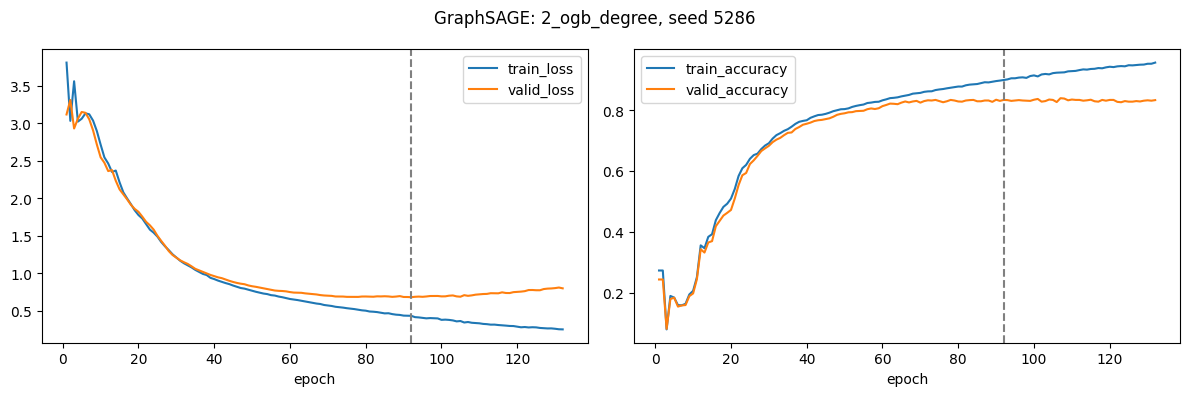

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,2_ogb_degree,5286,92,101,train,0.898763,0.471646,0.331156,0.454794,14708
1,GraphSAGE,2_ogb_degree,5286,92,101,valid,0.833333,0.486661,0.269217,0.483498,1572
2,GraphSAGE,2_ogb_degree,5286,92,101,test,0.678527,0.277742,0.236376,0.303624,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.677732  0.006264     3         0.278857  0.004506     3   
train  0.894570  0.014107     3         0.472625  0.034942     3   
valid  0.837786  0.007713     3         0.499963  0.024289     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.305672  0.007541     3  
train          0.456687  0.030182     3  
valid          0.499368  0.026764     3

In [22]:
graphsage_2_ogb_degree = train_condition('GraphSAGE', '2_ogb_degree')


## Run 3: Raw degree only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GraphSAGE/3_degree epoch 1: train 3.9162, valid 3.1574, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 10: train 2.9486, valid 2.7904, accuracy {'train': 0.0930785983800888, 'valid': 0.08587786555290222}
GraphSAGE/3_degree epoch 20: train 2.5770, valid 2.6110, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 30: train 2.5517, valid 2.5831, accuracy {'train': 0.27359259128570557, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 40: train 2.5443, valid 2.5827, accuracy {'train': 0.27359259128570557, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 50: train 2.5331, valid 2.5707, accuracy {'train': 0.2750883996486664, 'valid': 0.2442748099565506}
GraphSAGE/3_degree epoch 60: train 2.5217, valid 2.5547, accuracy {'train': 0.2770600914955139, 'valid': 0.24681933224201202}
GraphSAGE/3_degree epoch 70: train 2.5160, valid 2.5544, accuracy {'train': 0.277332067489624, 'valid': 0.2449109405

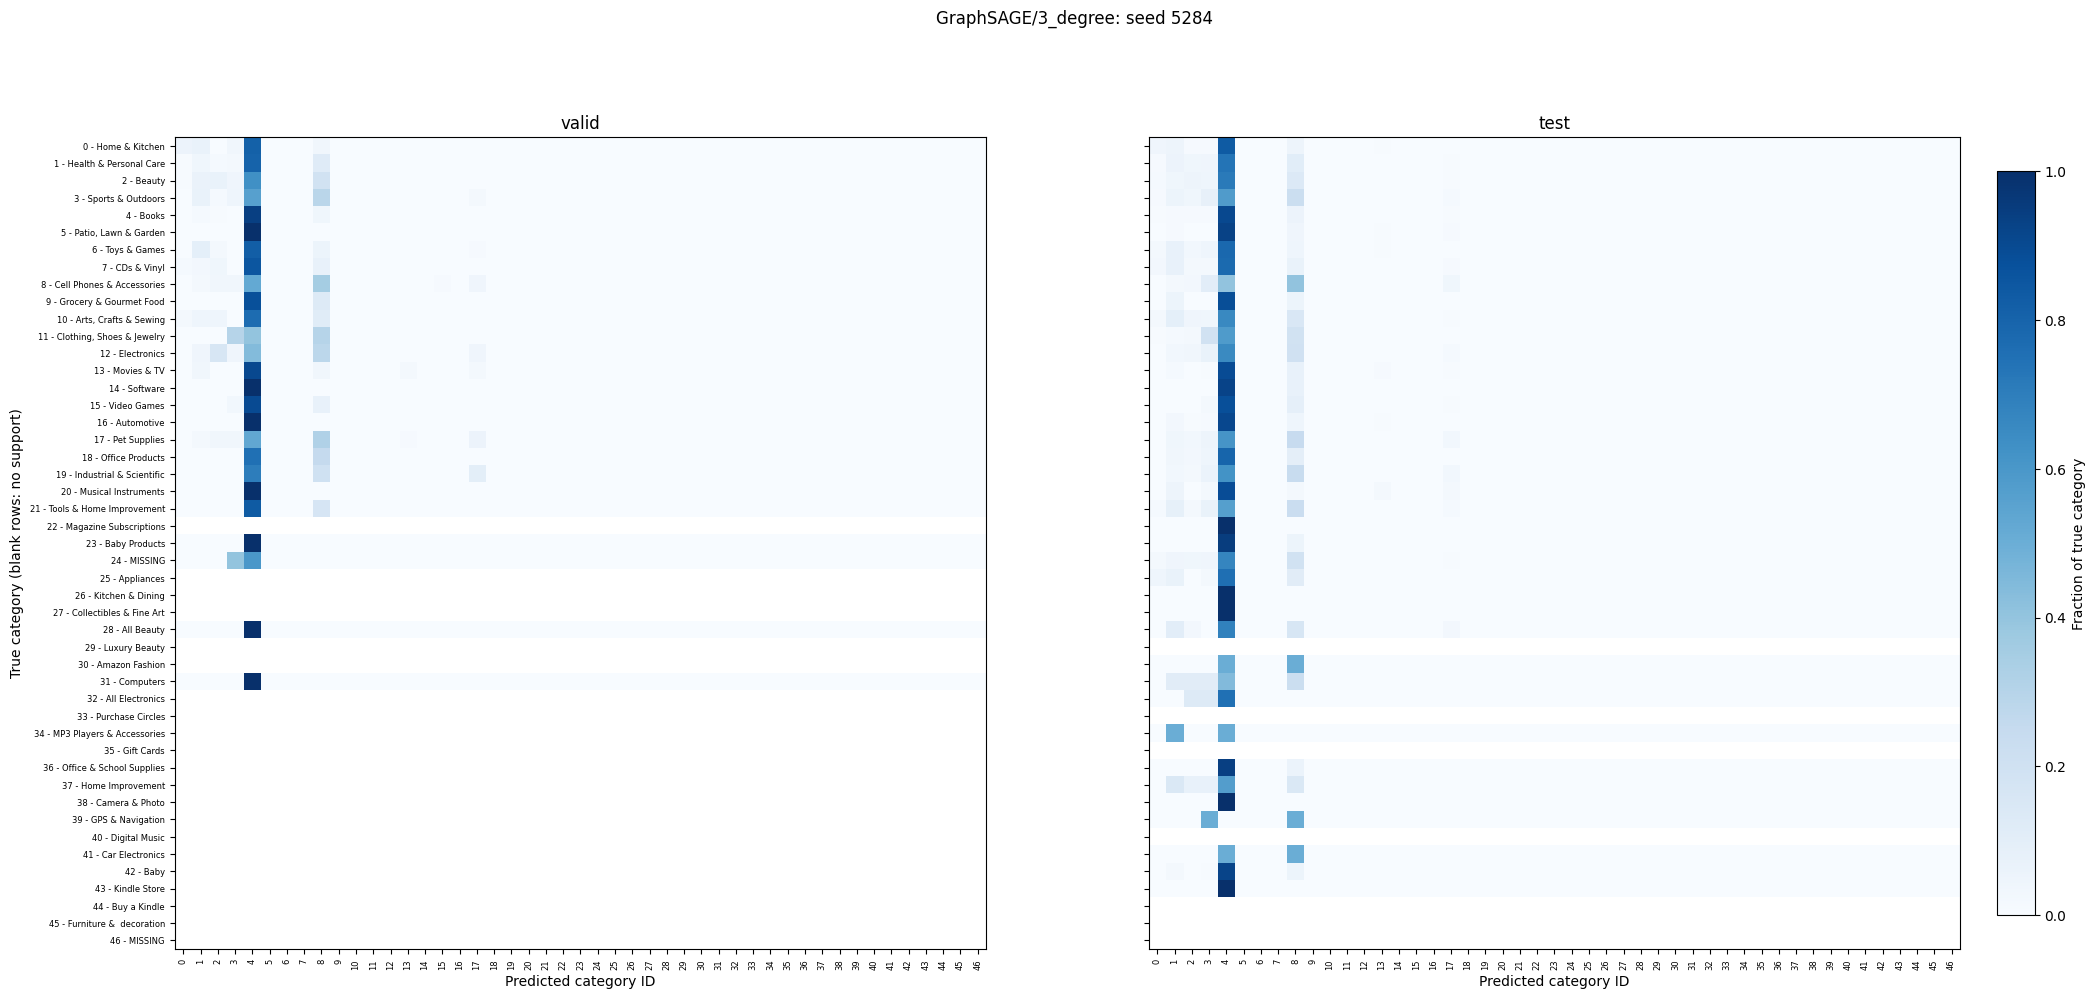

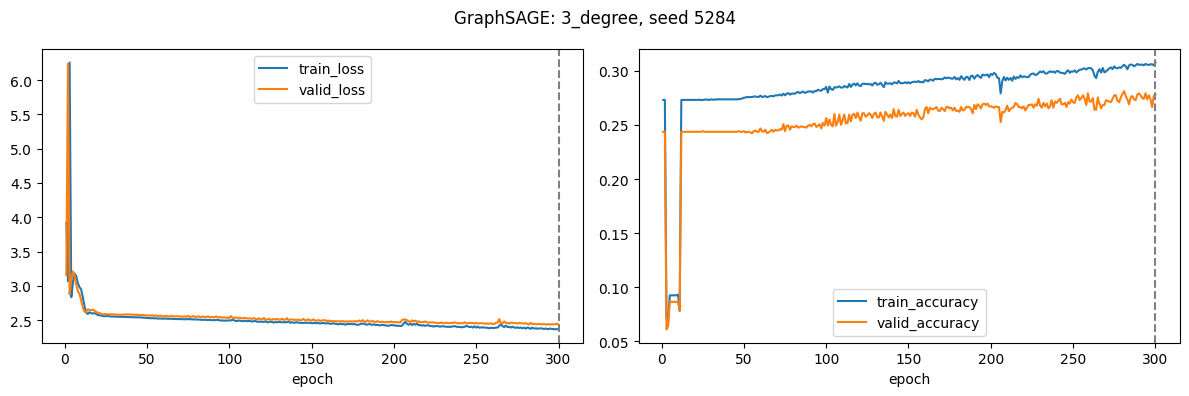

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,3_degree,5284,300,1,train,0.307588,0.042573,0.029892,0.051787,14708
1,GraphSAGE,3_degree,5284,300,1,valid,0.277990,0.045357,0.025091,0.060498,1572
2,GraphSAGE,3_degree,5284,300,1,test,0.193774,0.023516,0.020014,0.039344,37745


GraphSAGE/3_degree epoch 1: train 3.9965, valid 3.3188, accuracy {'train': 0.12285830825567245, 'valid': 0.11005088686943054}
GraphSAGE/3_degree epoch 10: train 2.8802, valid 2.7763, accuracy {'train': 0.09273864328861237, 'valid': 0.08651399612426758}
GraphSAGE/3_degree epoch 20: train 2.5792, valid 2.6140, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 30: train 2.5546, valid 2.5880, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 40: train 2.5453, valid 2.5818, accuracy {'train': 0.2736606001853943, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 50: train 2.5340, valid 2.5735, accuracy {'train': 0.2733886241912842, 'valid': 0.24300254881381989}
GraphSAGE/3_degree epoch 60: train 2.5236, valid 2.5557, accuracy {'train': 0.2746124565601349, 'valid': 0.24173027276992798}
GraphSAGE/3_degree epoch 70: train 2.5204, valid 2.5504, accuracy {'train': 0.27740004658699036, 'valid': 0.2519083

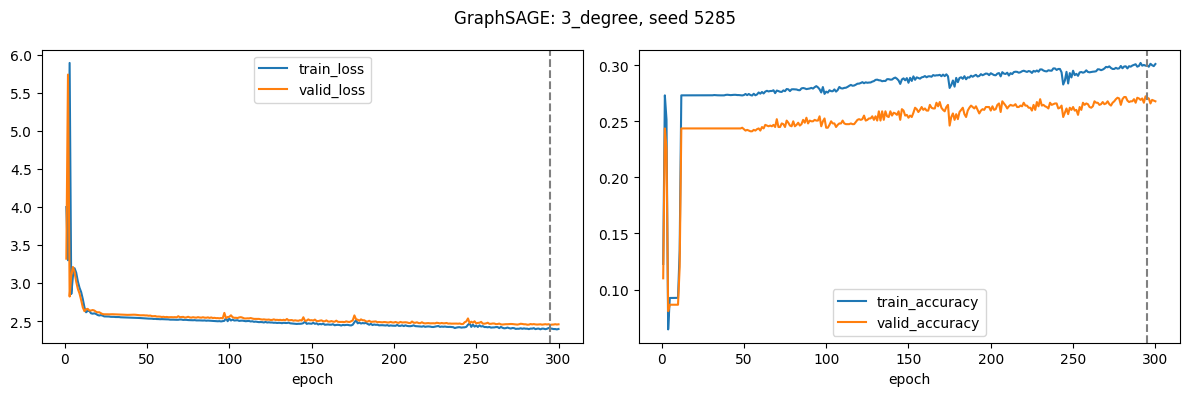

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,3_degree,5285,295,1,train,0.299837,0.035426,0.024874,0.047383,14708
1,GraphSAGE,3_degree,5285,295,1,valid,0.270992,0.037895,0.020963,0.055946,1572
2,GraphSAGE,3_degree,5285,295,1,test,0.187839,0.019427,0.016534,0.035257,37745


GraphSAGE/3_degree epoch 1: train 3.8758, valid 3.0333, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 10: train 2.5743, valid 2.6103, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 20: train 2.5563, valid 2.5790, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 30: train 2.5434, valid 2.5753, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GraphSAGE/3_degree epoch 40: train 2.5282, valid 2.5636, accuracy {'train': 0.27454447746276855, 'valid': 0.24173027276992798}
GraphSAGE/3_degree epoch 50: train 2.5225, valid 2.5552, accuracy {'train': 0.2746124565601349, 'valid': 0.2442748099565506}
GraphSAGE/3_degree epoch 60: train 2.5104, valid 2.5533, accuracy {'train': 0.27617624402046204, 'valid': 0.2442748099565506}
GraphSAGE/3_degree epoch 70: train 2.5024, valid 2.5524, accuracy {'train': 0.27672016620635986, 'valid': 0.2461832

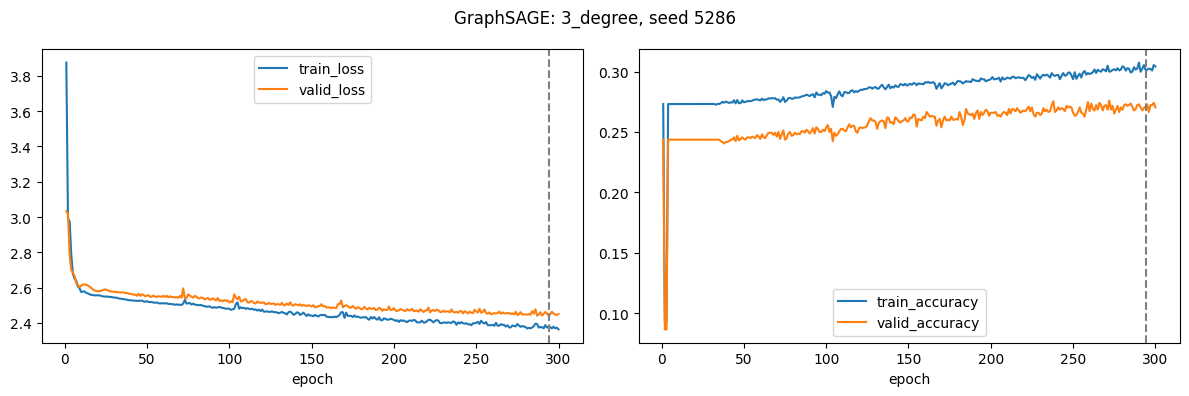

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GraphSAGE,3_degree,5286,294,1,train,0.301469,0.039560,0.027776,0.049783,14708
1,GraphSAGE,3_degree,5286,294,1,valid,0.270992,0.041725,0.023082,0.057068,1572
2,GraphSAGE,3_degree,5286,294,1,test,0.189270,0.020955,0.017834,0.035851,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.190295  0.003097     3         0.021300  0.002066     3   
train  0.302964  0.004086     3         0.039186  0.003588     3   
valid  0.273325  0.004040     3         0.041659  0.003732     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.036817  0.002208     3  
train          0.049651  0.002205     3  
valid          0.057837  0.002371     3

In [23]:
graphsage_3_degree = train_condition('GraphSAGE', '3_degree')


## Run 4: OGB-only cold start

Reuse run 1 without retraining. Remove all test-incident co-purchase edges and evaluate with the same OGB features. The table compares all four conditions.


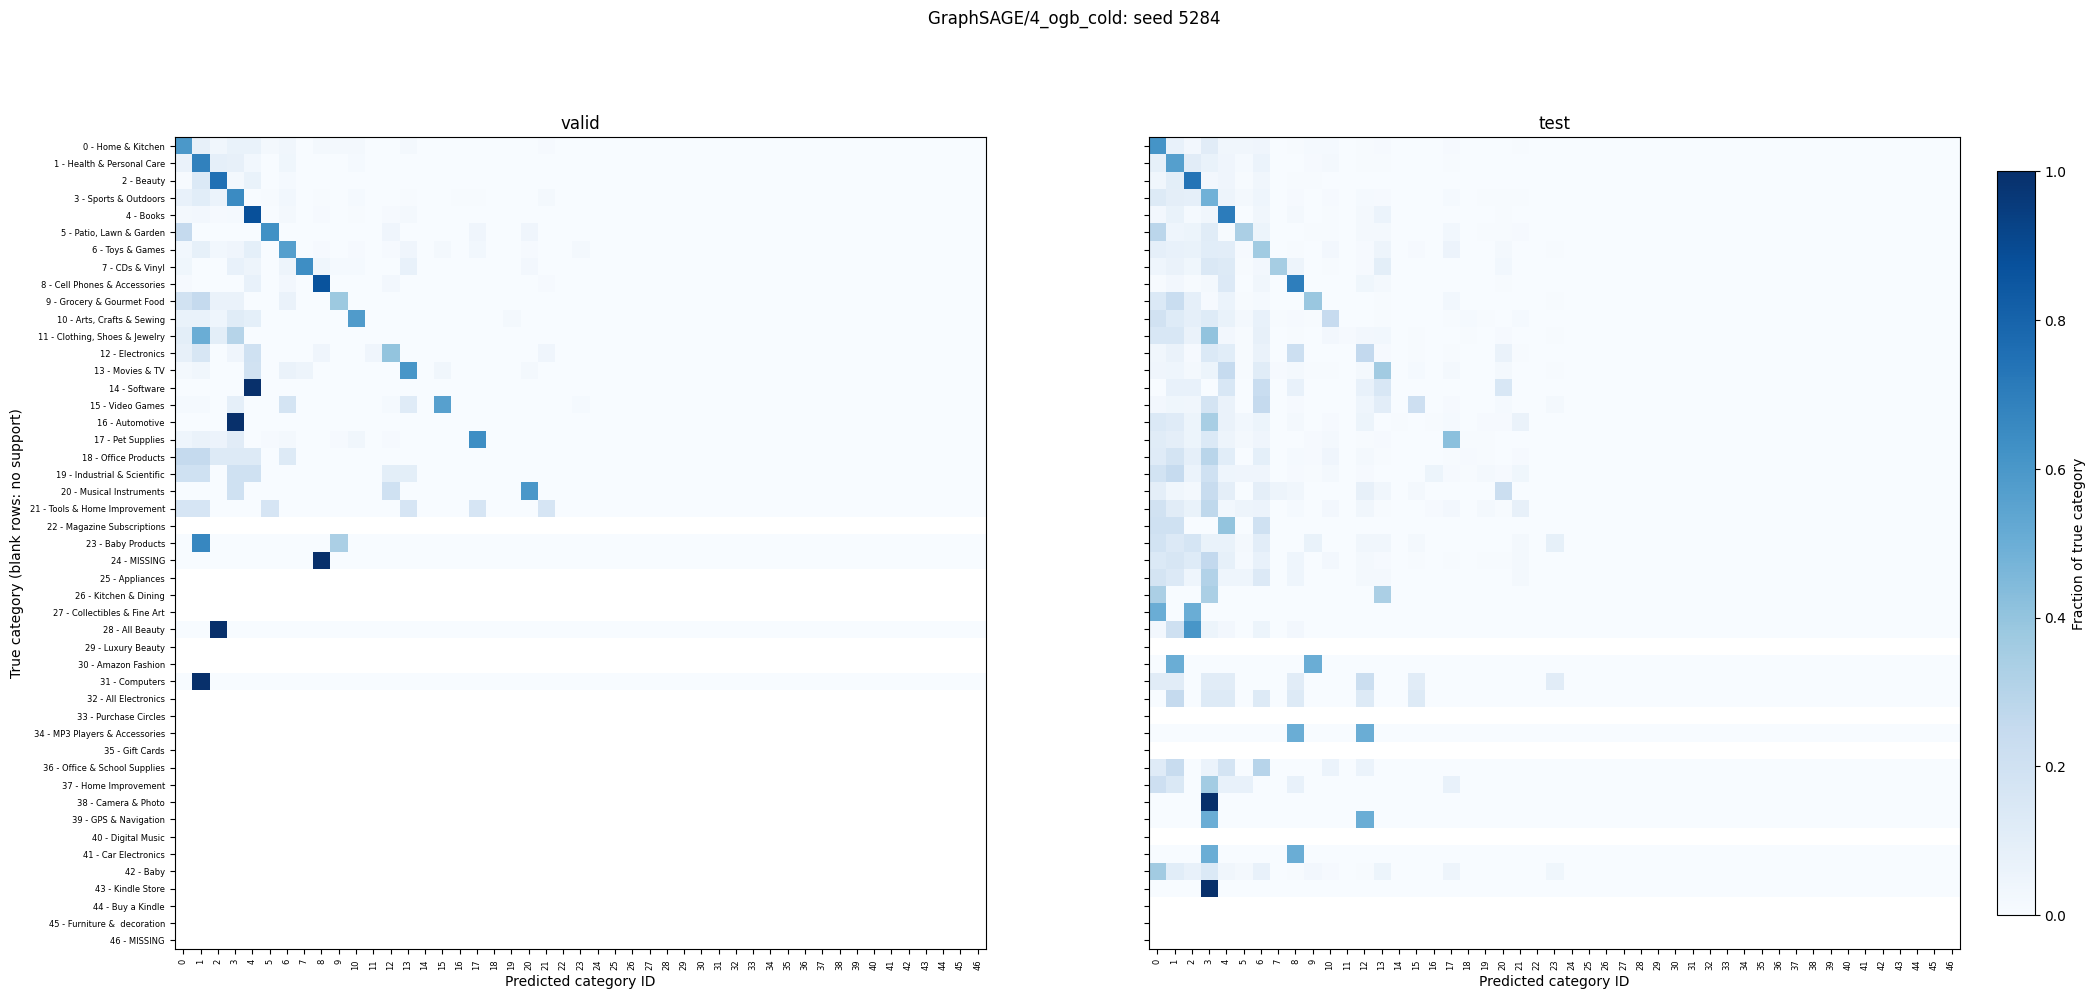

accuracy                 macro_f1_present                  \
                  mean       std count             mean       std count   
condition                                                                 
1_ogb         0.679251  0.002816     3         0.279531  0.002854     3   
2_ogb_degree  0.677732  0.006264     3         0.278857  0.004506     3   
3_degree      0.190295  0.003097     3         0.021300  0.002066     3   
4_ogb_cold    0.433347  0.004291     3         0.166105  0.002592     3   

             balanced_accuracy                  
                          mean       std count  
condition                                       
1_ogb                 0.304352  0.003296     3  
2_ogb_degree          0.305672  0.007541     3  
3_degree              0.036817  0.002208     3  
4_ogb_cold            0.176763  0.002967     3

In [24]:
cold_condition('GraphSAGE')


# 3. GAT

Retain the original notebook's custom multi-head attention, four layers, input embedding and per-node MLP. Attention uses co-purchase neighbours and one self-loop per node.

**V2 update:** each attention layer now adds its output to the preceding hidden representation. Feature dropout and attention-weight dropout are retained; the separate MLP head is unchanged.


In [25]:
class AttentionHead(MessagePassing):
    def __init__(self, in_dim, out_dim, dropout):
        super().__init__(aggr='add', flow='source_to_target')
        self.W = nn.Linear(in_dim, out_dim, bias=True)
        self.a = nn.Linear(2 * out_dim, 1, bias=False)
        self.dropout = dropout

    def forward(self, x, edges):
        # Wh matches the Wh_i / Wh_j argument names in message(); PyG gathers them per edge.
        return F.elu(self.propagate(edges, Wh=self.W(x), size=(x.size(0), x.size(0)))) # self.propagate calls message() method internally

    def message(self, Wh_i, Wh_j, index, ptr, size_i):
        scores = F.leaky_relu(self.a(torch.cat([Wh_i, Wh_j], dim=-1)), negative_slope=0.01) # Equation 3: Unnormalised attention scores
        alpha = softmax(scores, index=index, ptr=ptr, num_nodes=size_i) # Equation 2: Normalised attention scores
        alpha = F.dropout(alpha, p=self.dropout, training=self.training)
        return alpha * Wh_j

class GATLayer(nn.Module):
    def __init__(self, hidden_dim, width, heads, dropout):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(hidden_dim, width, dropout)
                                    for _ in range(heads)])

    def forward(self, h, edges):
        return torch.cat([head(h, edges) for head in self.heads], dim=-1)

class ProductGAT(nn.Module):
    def __init__(self, in_dim, width, heads, classes, dropout, num_layers=4, mlp_hidden_layers=2):
        super().__init__()
        self.dropout = dropout
        hidden_dim = width * heads
        self.embedding_h = nn.Linear(in_dim, hidden_dim)
        self.GAT_layers = nn.ModuleList([GATLayer(hidden_dim, width, heads, dropout)
                                         for _ in range(num_layers)])
        mlp = []
        for _ in range(mlp_hidden_layers):
            mlp.extend([nn.Linear(hidden_dim, hidden_dim), nn.ReLU()])
        mlp.append(nn.Linear(hidden_dim, classes)) # Produce a score for each class for each product
        self.MLP_layer = nn.Sequential(*mlp)

    def forward(self, x, edges):
        # Stage 1. Embed each product's features: [N, input_dim] -> [N, hidden_dim].
        h = self.embedding_h(x)

        # Stage 2. Update node representations through stacked multi-head GAT layers.
        for layer in self.GAT_layers:
            h_in = h  # Preserve the clean identity path.
            messages = layer(F.dropout(h, p=self.dropout, training=self.training), edges)
            h = h_in + messages  # Residual update; concatenated head width stays hidden_dim.

        # Stage 3. Classify each node directly; retain all N nodes without pooling.
        return self.MLP_layer(h)

## Run 1: OGB 100-dimensional features only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GAT/1_ogb epoch 1: train 3.8386, valid 3.5779, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GAT/1_ogb epoch 10: train 1.6488, valid 1.5292, accuracy {'train': 0.6331928372383118, 'valid': 0.6132315397262573}
GAT/1_ogb epoch 20: train 1.0569, valid 1.0438, accuracy {'train': 0.7453086972236633, 'valid': 0.7385495901107788}
GAT/1_ogb epoch 30: train 0.8446, valid 0.8351, accuracy {'train': 0.7916780114173889, 'valid': 0.7843511700630188}
GAT/1_ogb epoch 40: train 0.7401, valid 0.7682, accuracy {'train': 0.8128909468650818, 'valid': 0.7996183037757874}
GAT/1_ogb epoch 50: train 0.6747, valid 0.7342, accuracy {'train': 0.8273048400878906, 'valid': 0.8142493367195129}
GAT/1_ogb epoch 60: train 0.6201, valid 0.7142, accuracy {'train': 0.8391351699829102, 'valid': 0.8231552243232727}
GAT/1_ogb epoch 70: train 0.5740, valid 0.7084, accuracy {'train': 0.8510334491729736, 'valid': 0.821882963180542}
GAT/1_ogb epoch 80: train 0.5408, valid 0.7079, accuracy {'train': 0.861

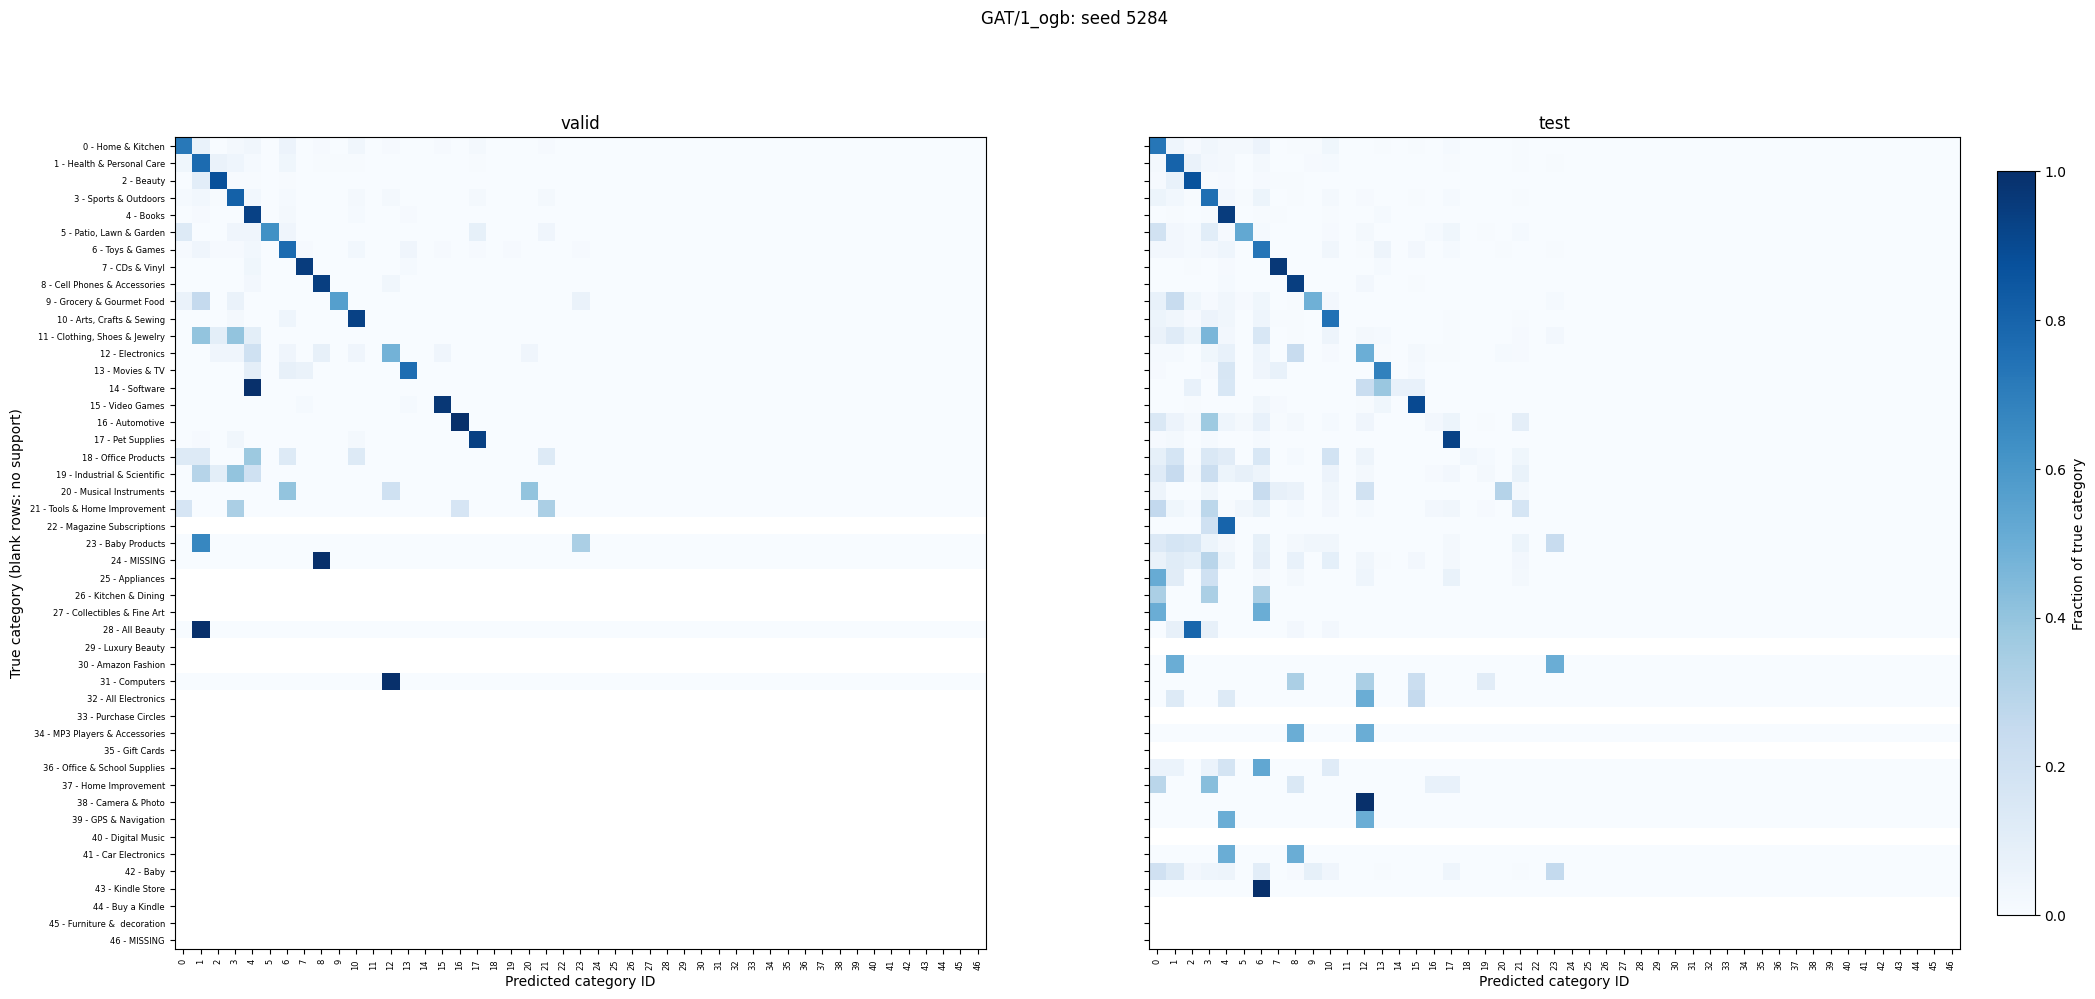

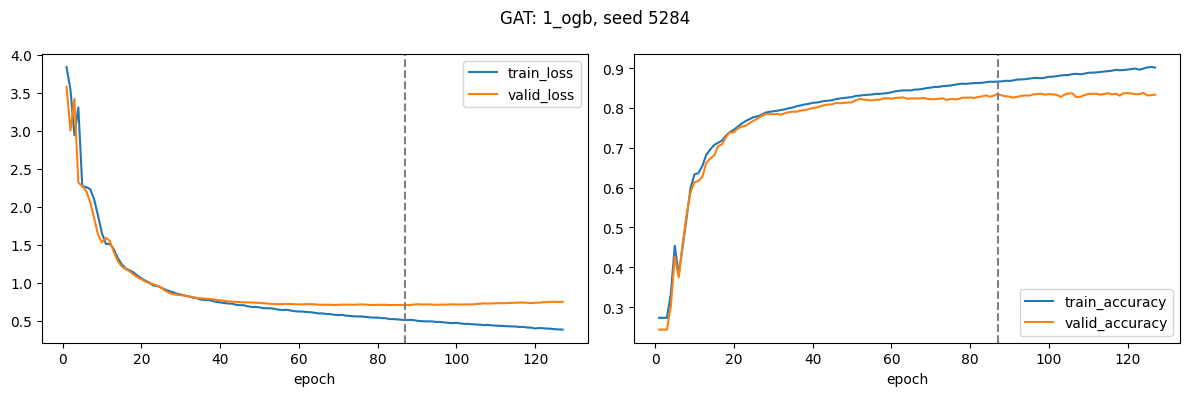

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,1_ogb,5284,87,100,train,0.866331,0.451656,0.317120,0.435668,14708
1,GAT,1_ogb,5284,87,100,valid,0.835242,0.533910,0.295354,0.542591,1572
2,GAT,1_ogb,5284,87,100,test,0.678527,0.284641,0.242248,0.309664,37745


GAT/1_ogb epoch 1: train 3.8270, valid 3.5242, accuracy {'train': 0.2854228913784027, 'valid': 0.25763359665870667}
GAT/1_ogb epoch 10: train 1.6738, valid 1.5770, accuracy {'train': 0.5977699160575867, 'valid': 0.5826972126960754}
GAT/1_ogb epoch 20: train 1.0469, valid 1.0117, accuracy {'train': 0.7516317367553711, 'valid': 0.7512722611427307}
GAT/1_ogb epoch 30: train 0.8436, valid 0.8362, accuracy {'train': 0.7916780114173889, 'valid': 0.7792620658874512}
GAT/1_ogb epoch 40: train 0.7323, valid 0.7513, accuracy {'train': 0.813774824142456, 'valid': 0.8027989864349365}
GAT/1_ogb epoch 50: train 0.6636, valid 0.7149, accuracy {'train': 0.8302284479141235, 'valid': 0.8193384408950806}
GAT/1_ogb epoch 60: train 0.6119, valid 0.6934, accuracy {'train': 0.8400870561599731, 'valid': 0.8187022805213928}
GAT/1_ogb epoch 70: train 0.5702, valid 0.6816, accuracy {'train': 0.8504895567893982, 'valid': 0.822519063949585}
GAT/1_ogb epoch 80: train 0.5384, valid 0.6683, accuracy {'train': 0.86041

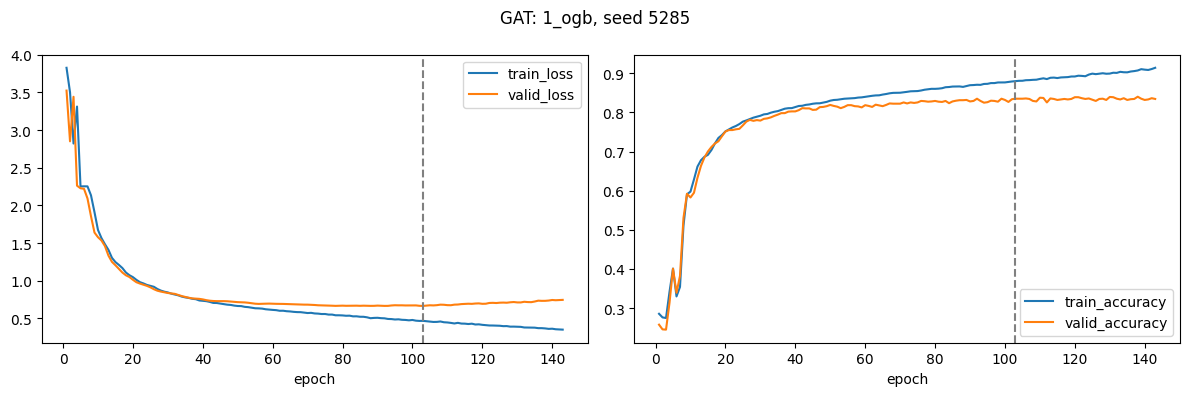

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,1_ogb,5285,103,100,train,0.879997,0.477017,0.334927,0.456804,14708
1,GAT,1_ogb,5285,103,100,valid,0.835242,0.538959,0.298148,0.526730,1572
2,GAT,1_ogb,5285,103,100,test,0.683508,0.292589,0.249012,0.313637,37745


GAT/1_ogb epoch 1: train 3.8478, valid 3.5675, accuracy {'train': 0.2839271128177643, 'valid': 0.25}
GAT/1_ogb epoch 10: train 1.5671, valid 1.5913, accuracy {'train': 0.6418275833129883, 'valid': 0.6125954389572144}
GAT/1_ogb epoch 20: train 0.9991, valid 0.9903, accuracy {'train': 0.7574109435081482, 'valid': 0.7480915784835815}
GAT/1_ogb epoch 30: train 0.8096, valid 0.8135, accuracy {'train': 0.7930378317832947, 'valid': 0.7932569980621338}
GAT/1_ogb epoch 40: train 0.7031, valid 0.7470, accuracy {'train': 0.8212537169456482, 'valid': 0.8091602921485901}
GAT/1_ogb epoch 50: train 0.6346, valid 0.7018, accuracy {'train': 0.8374354243278503, 'valid': 0.821882963180542}
GAT/1_ogb epoch 60: train 0.5811, valid 0.6944, accuracy {'train': 0.8492656946182251, 'valid': 0.830152690410614}
GAT/1_ogb epoch 70: train 0.5398, valid 0.6974, accuracy {'train': 0.8596002459526062, 'valid': 0.8346055746078491}
GAT/1_ogb epoch 80: train 0.5042, valid 0.6928, accuracy {'train': 0.8683029413223267, 'v

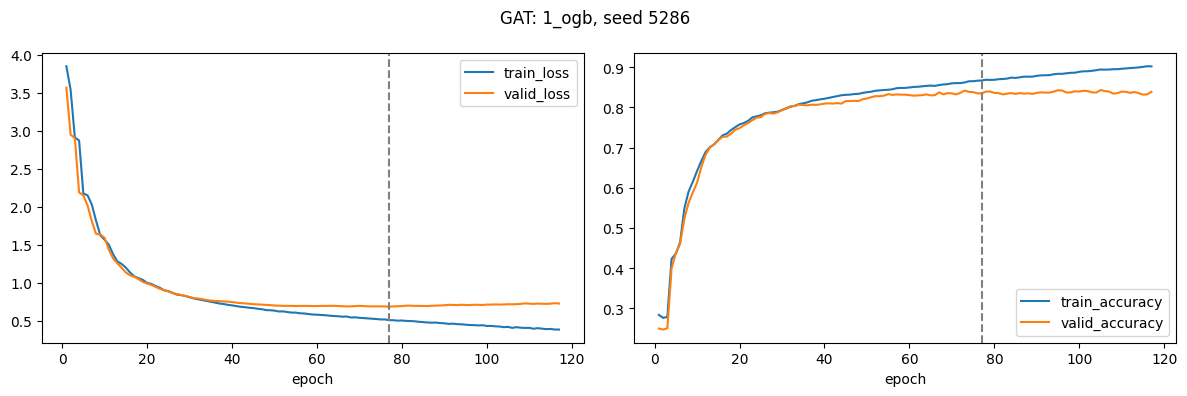

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,1_ogb,5286,77,100,train,0.866535,0.447275,0.314044,0.433708,14708
1,GAT,1_ogb,5286,77,100,valid,0.834606,0.525347,0.290618,0.517855,1572
2,GAT,1_ogb,5286,77,100,test,0.679852,0.286874,0.244148,0.310326,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.680629  0.002580     3         0.288035  0.004099     3   
train  0.870955  0.007832     3         0.458650  0.016057     3   
valid  0.835030  0.000367     3         0.532739  0.006881     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.311209  0.002129     3  
train          0.442060  0.012806     3  
valid          0.529059  0.012531     3

In [26]:
gat_1_ogb = train_condition('GAT', '1_ogb')


## Run 2: OGB features + raw degree

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GAT/2_ogb_degree epoch 1: train 3.8528, valid 3.6389, accuracy {'train': 0.27352461218833923, 'valid': 0.24491094052791595}
GAT/2_ogb_degree epoch 10: train 1.6534, valid 1.5732, accuracy {'train': 0.6042289733886719, 'valid': 0.5776081681251526}
GAT/2_ogb_degree epoch 20: train 0.9812, valid 0.9724, accuracy {'train': 0.7615583539009094, 'valid': 0.7608142495155334}
GAT/2_ogb_degree epoch 30: train 0.8048, valid 0.8098, accuracy {'train': 0.8004487156867981, 'valid': 0.7938931584358215}
GAT/2_ogb_degree epoch 40: train 0.7087, valid 0.7340, accuracy {'train': 0.8207098245620728, 'valid': 0.8148854970932007}
GAT/2_ogb_degree epoch 50: train 0.6358, valid 0.6950, accuracy {'train': 0.8373674154281616, 'valid': 0.8263359069824219}
GAT/2_ogb_degree epoch 60: train 0.5832, valid 0.6721, accuracy {'train': 0.850285530090332, 'valid': 0.8314249515533447}
GAT/2_ogb_degree epoch 70: train 0.5348, valid 0.6553, accuracy {'train': 0.8627277612686157, 'valid': 0.838422417640686}
GAT/2_ogb_degree 

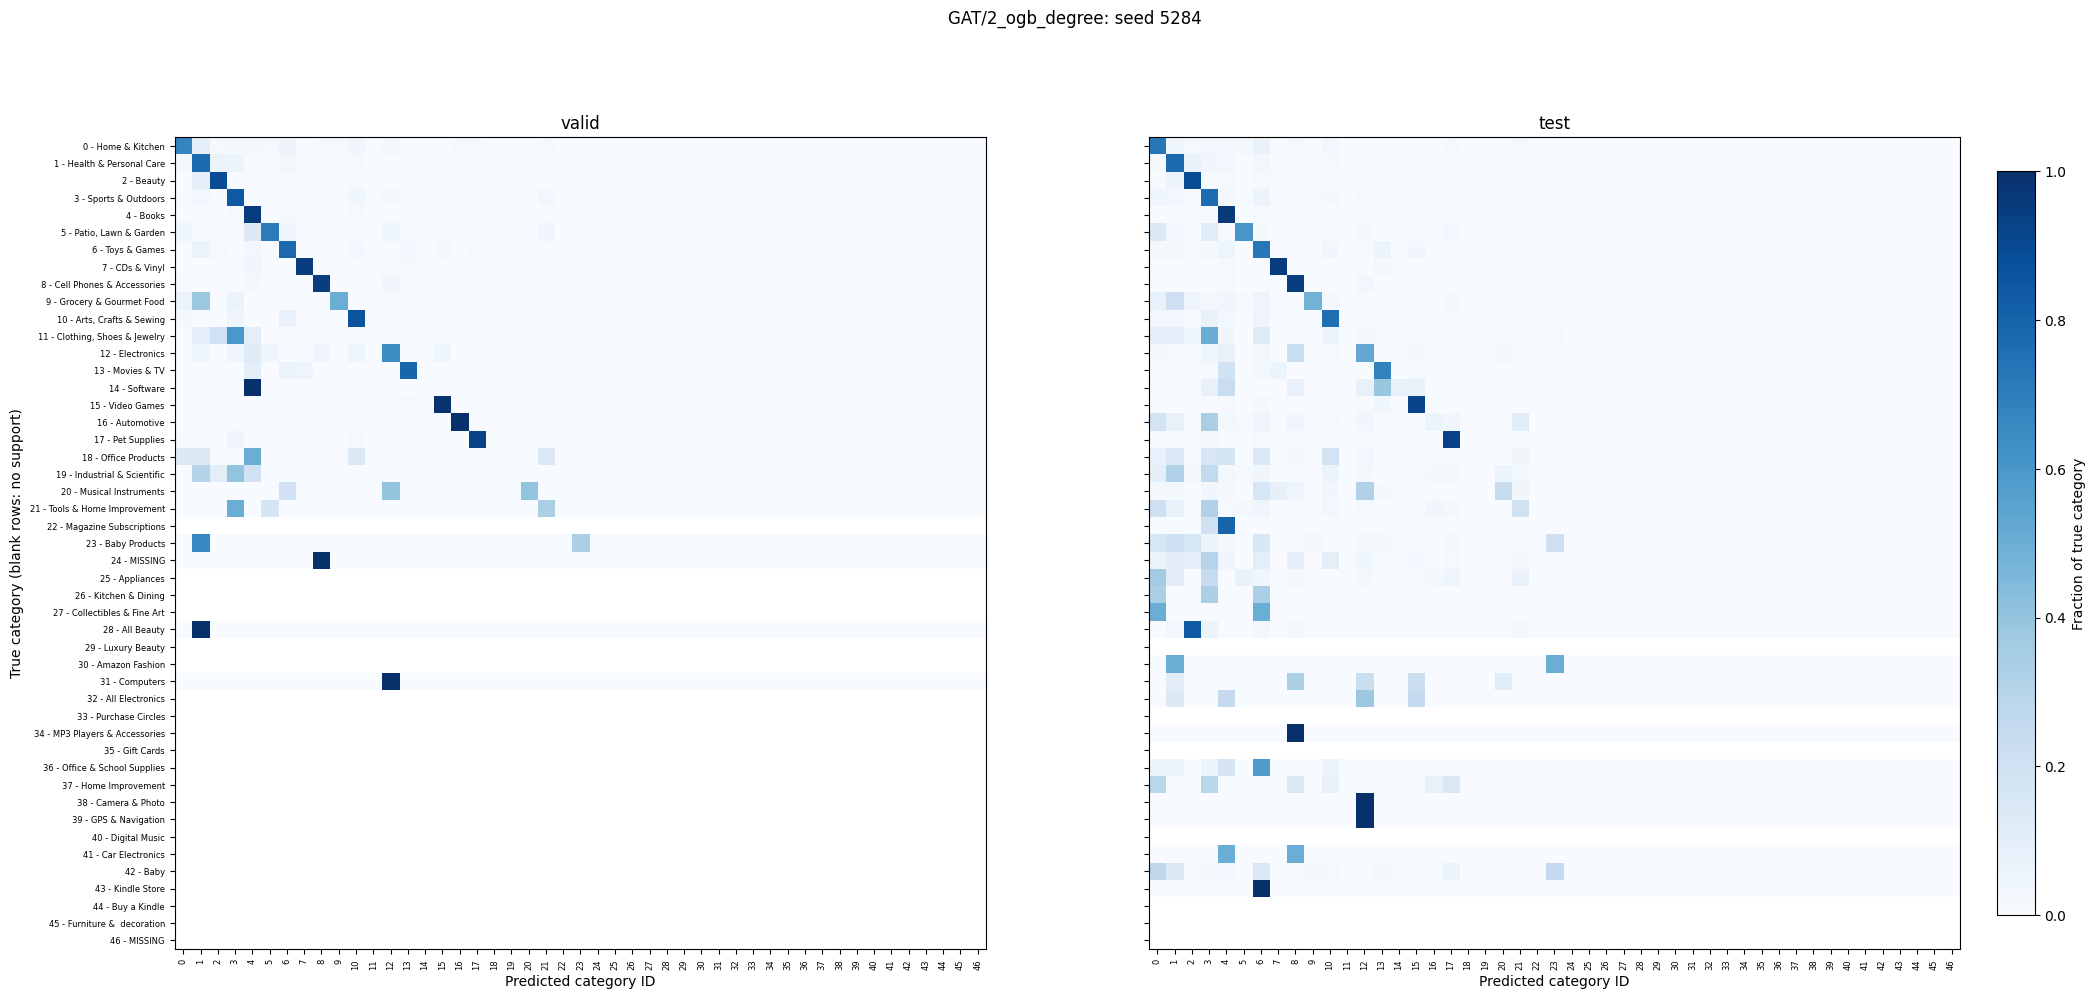

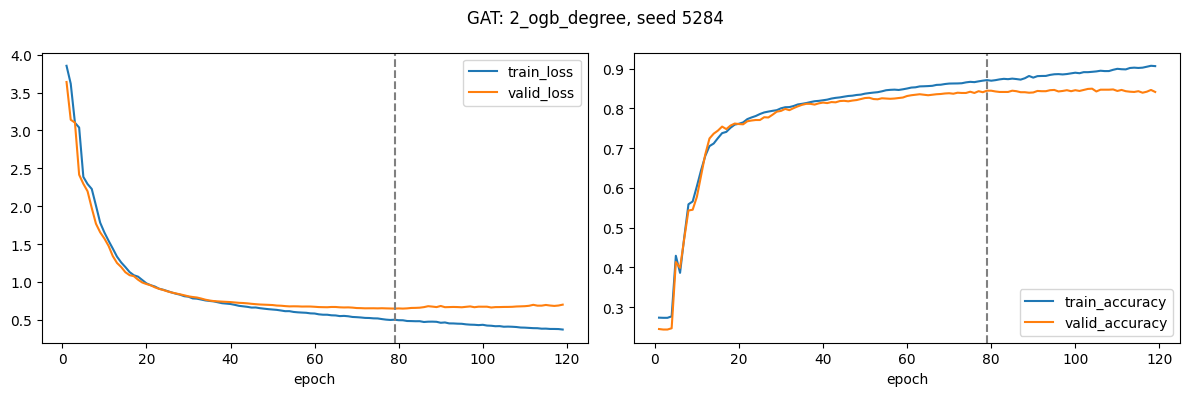

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,2_ogb_degree,5284,79,101,train,0.871431,0.451853,0.317258,0.437578,14708
1,GAT,2_ogb_degree,5284,79,101,valid,0.844784,0.545090,0.301539,0.549402,1572
2,GAT,2_ogb_degree,5284,79,101,test,0.684303,0.289262,0.246180,0.310538,37745


GAT/2_ogb_degree epoch 1: train 3.8059, valid 3.4978, accuracy {'train': 0.2742045223712921, 'valid': 0.2442748099565506}
GAT/2_ogb_degree epoch 10: train 1.8387, valid 1.6941, accuracy {'train': 0.5642507672309875, 'valid': 0.5343511700630188}
GAT/2_ogb_degree epoch 20: train 1.0987, valid 1.0891, accuracy {'train': 0.7387816309928894, 'valid': 0.7169210910797119}
GAT/2_ogb_degree epoch 30: train 0.8628, valid 0.8450, accuracy {'train': 0.7877345681190491, 'valid': 0.7830789089202881}
GAT/2_ogb_degree epoch 40: train 0.7523, valid 0.7512, accuracy {'train': 0.8113951683044434, 'valid': 0.805343508720398}
GAT/2_ogb_degree epoch 50: train 0.6755, valid 0.7183, accuracy {'train': 0.8270329236984253, 'valid': 0.81361323595047}
GAT/2_ogb_degree epoch 60: train 0.6274, valid 0.6993, accuracy {'train': 0.8389312028884888, 'valid': 0.8212468028068542}
GAT/2_ogb_degree epoch 70: train 0.5839, valid 0.6927, accuracy {'train': 0.8475659489631653, 'valid': 0.8187022805213928}
GAT/2_ogb_degree epo

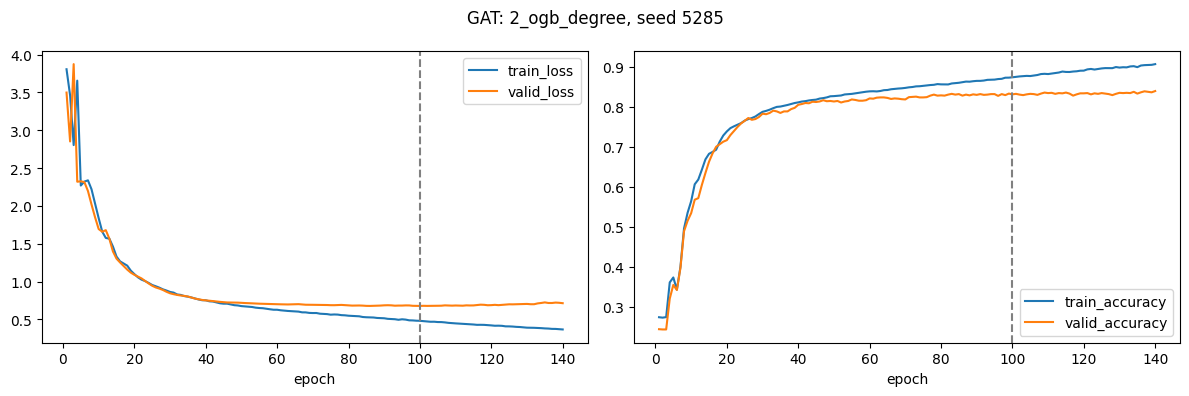

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,2_ogb_degree,5285,100,101,train,0.874082,0.472129,0.331495,0.456822,14708
1,GAT,2_ogb_degree,5285,100,101,valid,0.831425,0.525341,0.290614,0.517657,1572
2,GAT,2_ogb_degree,5285,100,101,test,0.676699,0.284648,0.242254,0.310102,37745


GAT/2_ogb_degree epoch 1: train 3.8520, valid 3.5723, accuracy {'train': 0.2856948673725128, 'valid': 0.25763359665870667}
GAT/2_ogb_degree epoch 10: train 1.5909, valid 1.5834, accuracy {'train': 0.6344166398048401, 'valid': 0.6329516768455505}
GAT/2_ogb_degree epoch 20: train 0.9679, valid 0.9551, accuracy {'train': 0.7703290581703186, 'valid': 0.7620865106582642}
GAT/2_ogb_degree epoch 30: train 0.7770, valid 0.7960, accuracy {'train': 0.8043921589851379, 'valid': 0.7970737814903259}
GAT/2_ogb_degree epoch 40: train 0.6830, valid 0.7279, accuracy {'train': 0.8263530135154724, 'valid': 0.8129770755767822}
GAT/2_ogb_degree epoch 50: train 0.6203, valid 0.7017, accuracy {'train': 0.8396111130714417, 'valid': 0.8263359069824219}
GAT/2_ogb_degree epoch 60: train 0.5762, valid 0.6890, accuracy {'train': 0.8511694073677063, 'valid': 0.8295165300369263}
GAT/2_ogb_degree epoch 70: train 0.5371, valid 0.6845, accuracy {'train': 0.8610280156135559, 'valid': 0.8377862572669983}
GAT/2_ogb_degree

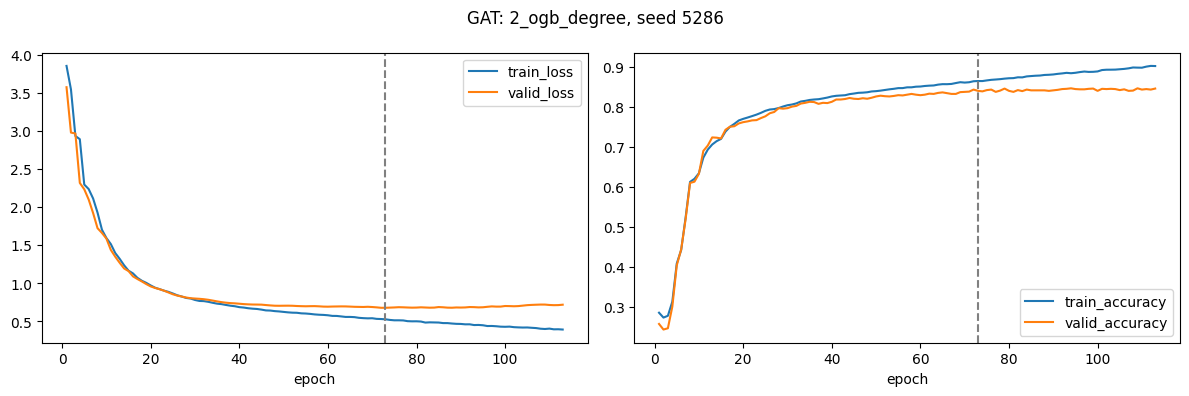

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,2_ogb_degree,5286,73,101,train,0.864903,0.447157,0.313961,0.436750,14708
1,GAT,2_ogb_degree,5286,73,101,valid,0.840331,0.528485,0.292353,0.522293,1572
2,GAT,2_ogb_degree,5286,73,101,test,0.681494,0.284835,0.242413,0.311214,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.680832  0.003845     3         0.286248  0.002611     3   
train  0.870139  0.004724     3         0.457046  0.013271     3   
valid  0.838846  0.006802     3         0.532972  0.010612     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.310618  0.000561     3  
train          0.443716  0.011357     3  
valid          0.529784  0.017147     3

In [27]:
gat_2_ogb_degree = train_condition('GAT', '2_ogb_degree')


## Run 3: Raw degree only

Train a fresh model using released splits; restore the checkpoint with the lowest validation loss before reporting metrics.


GAT/3_degree epoch 1: train 3.8435, valid 3.2372, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GAT/3_degree epoch 10: train 2.6425, valid 2.6599, accuracy {'train': 0.2734566330909729, 'valid': 0.24109414219856262}
GAT/3_degree epoch 20: train 2.5659, valid 2.5969, accuracy {'train': 0.2741365134716034, 'valid': 0.24363867938518524}
GAT/3_degree epoch 30: train 2.5401, valid 2.5939, accuracy {'train': 0.2741365134716034, 'valid': 0.24300254881381989}
GAT/3_degree epoch 40: train 2.5242, valid 2.5617, accuracy {'train': 0.27590426802635193, 'valid': 0.2455470710992813}
GAT/3_degree epoch 50: train 2.5147, valid 2.5618, accuracy {'train': 0.2784199118614197, 'valid': 0.24809160828590393}
GAT/3_degree epoch 60: train 2.5033, valid 2.5500, accuracy {'train': 0.28073158860206604, 'valid': 0.2487277388572693}
GAT/3_degree epoch 70: train 2.4890, valid 2.5443, accuracy {'train': 0.28195539116859436, 'valid': 0.25063613057136536}
GAT/3_degree epoch 80: train 2.4689, va

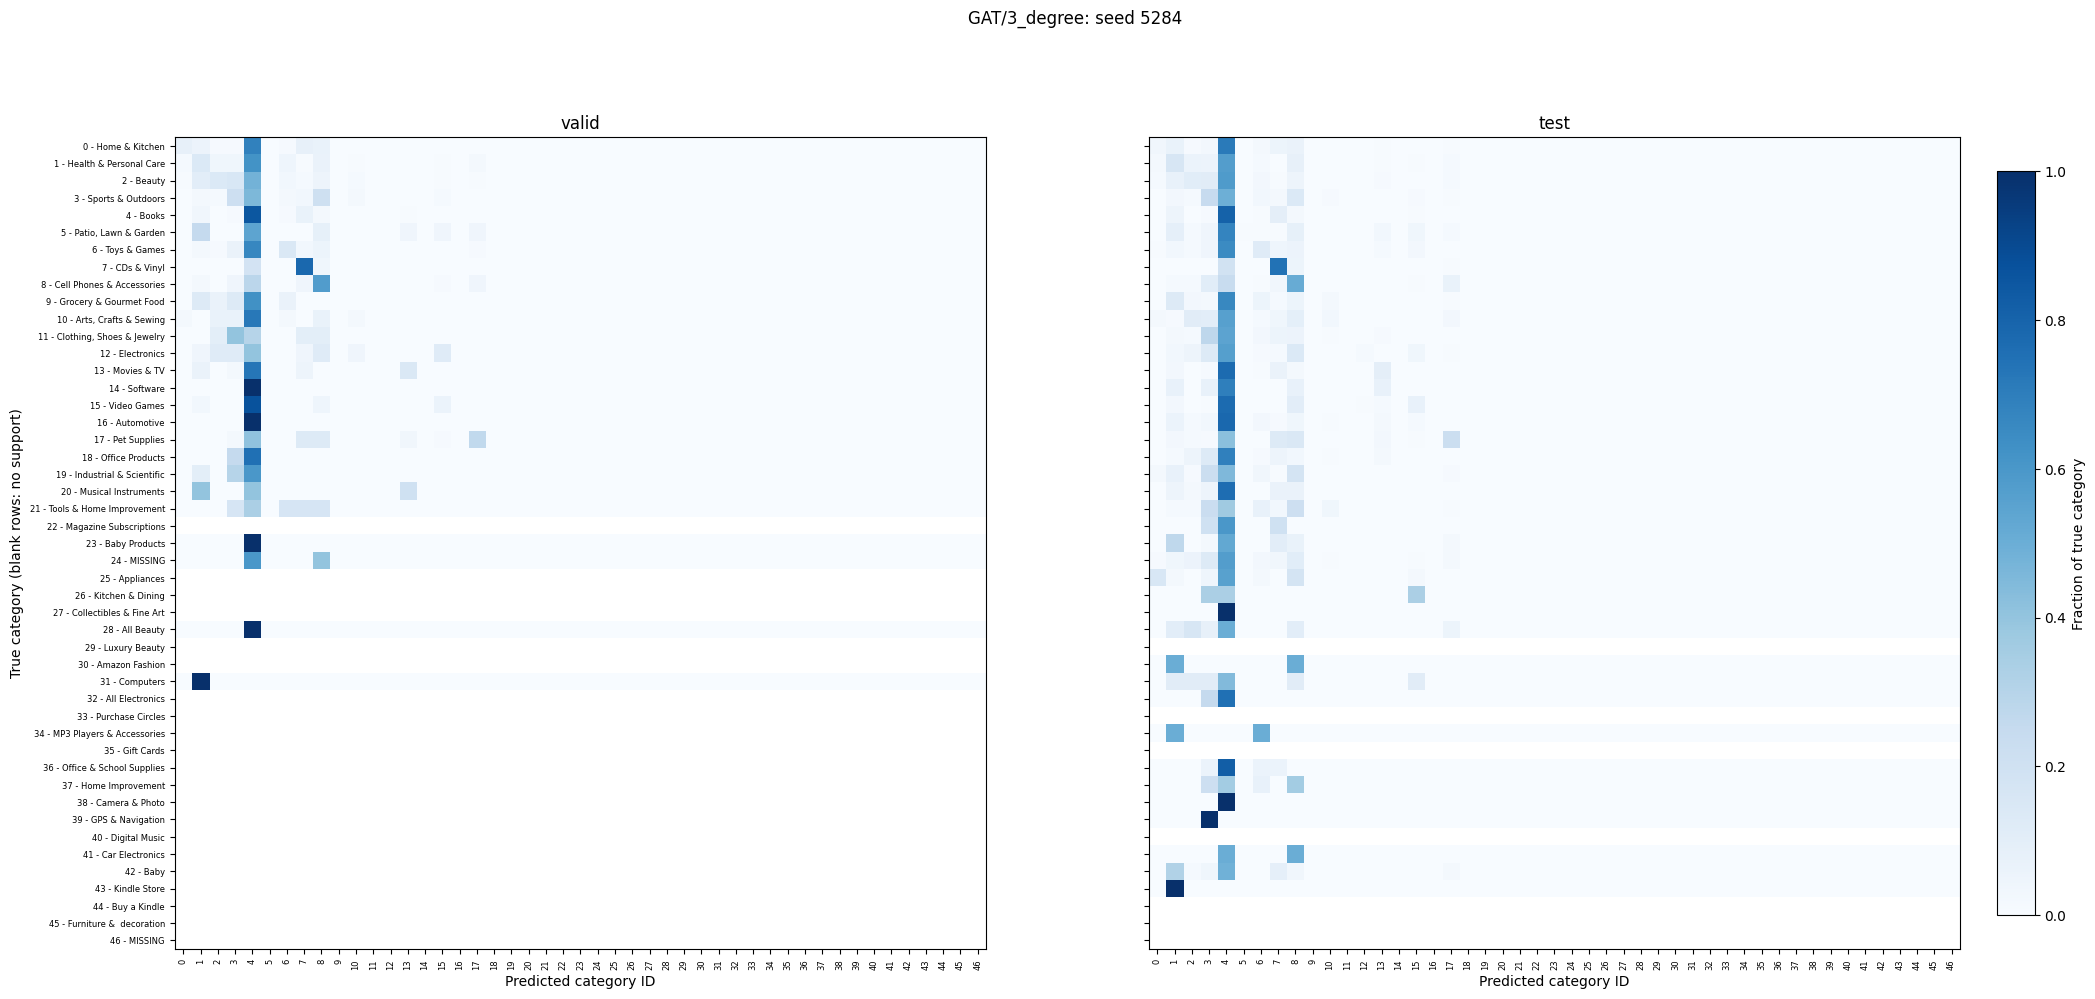

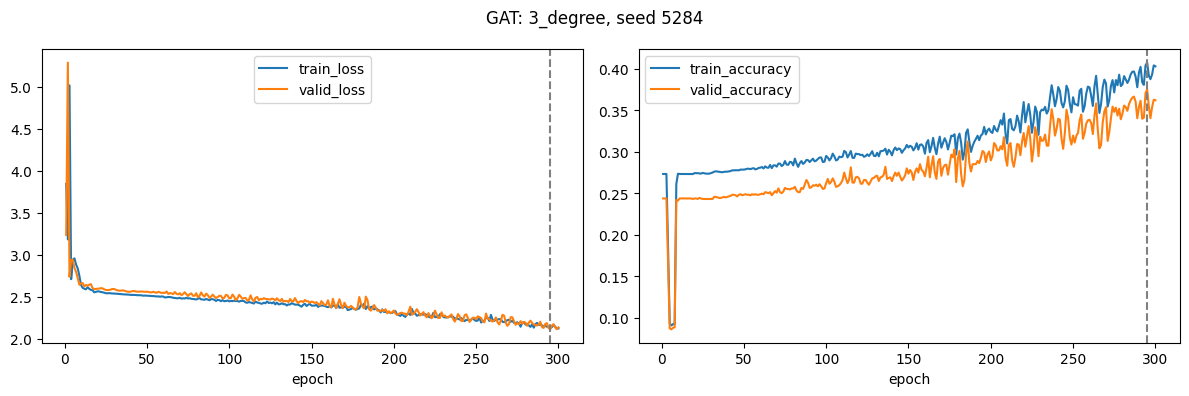

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,3_degree,5284,295,1,train,0.407329,0.148450,0.104231,0.144801,14708
1,GAT,3_degree,5284,295,1,valid,0.375318,0.128609,0.071145,0.131269,1572
2,GAT,3_degree,5284,295,1,test,0.265307,0.067965,0.057842,0.079258,37745


GAT/3_degree epoch 1: train 3.8555, valid 3.2583, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GAT/3_degree epoch 10: train 2.6284, valid 2.6851, accuracy {'train': 0.2731846570968628, 'valid': 0.24363867938518524}
GAT/3_degree epoch 20: train 2.5713, valid 2.5926, accuracy {'train': 0.2722328007221222, 'valid': 0.24045801162719727}
GAT/3_degree epoch 30: train 2.5400, valid 2.5857, accuracy {'train': 0.2748164236545563, 'valid': 0.2442748099565506}
GAT/3_degree epoch 40: train 2.5287, valid 2.5741, accuracy {'train': 0.2758362889289856, 'valid': 0.24363867938518524}
GAT/3_degree epoch 50: train 2.5183, valid 2.5550, accuracy {'train': 0.2782159447669983, 'valid': 0.24936386942863464}
GAT/3_degree epoch 60: train 2.5080, valid 2.5473, accuracy {'train': 0.2806635797023773, 'valid': 0.2525445222854614}
GAT/3_degree epoch 70: train 2.4911, valid 2.5273, accuracy {'train': 0.2856268584728241, 'valid': 0.25763359665870667}
GAT/3_degree epoch 80: train 2.4764, valid

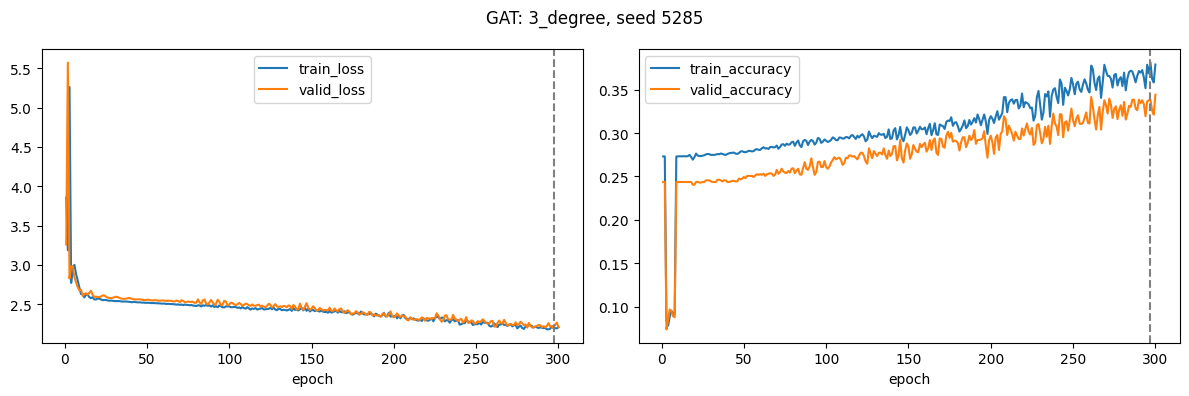

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,3_degree,5285,297,1,train,0.381221,0.135245,0.094960,0.131391,14708
1,GAT,3_degree,5285,297,1,valid,0.338422,0.111904,0.061904,0.111379,1572
2,GAT,3_degree,5285,297,1,test,0.239820,0.058296,0.049614,0.067550,37745


GAT/3_degree epoch 1: train 3.8729, valid 3.2605, accuracy {'train': 0.27311667799949646, 'valid': 0.24363867938518524}
GAT/3_degree epoch 10: train 2.6126, valid 2.6148, accuracy {'train': 0.2731846570968628, 'valid': 0.24363867938518524}
GAT/3_degree epoch 20: train 2.5535, valid 2.6171, accuracy {'train': 0.27304866909980774, 'valid': 0.24236641824245453}
GAT/3_degree epoch 30: train 2.5374, valid 2.5701, accuracy {'train': 0.2741365134716034, 'valid': 0.2442748099565506}
GAT/3_degree epoch 40: train 2.5279, valid 2.5693, accuracy {'train': 0.27447646856307983, 'valid': 0.24363867938518524}
GAT/3_degree epoch 50: train 2.5172, valid 2.5493, accuracy {'train': 0.2765161693096161, 'valid': 0.2455470710992813}
GAT/3_degree epoch 60: train 2.5094, valid 2.5672, accuracy {'train': 0.2765161693096161, 'valid': 0.2455470710992813}
GAT/3_degree epoch 70: train 2.4922, valid 2.5306, accuracy {'train': 0.2803916335105896, 'valid': 0.24936386942863464}
GAT/3_degree epoch 80: train 2.4839, vali

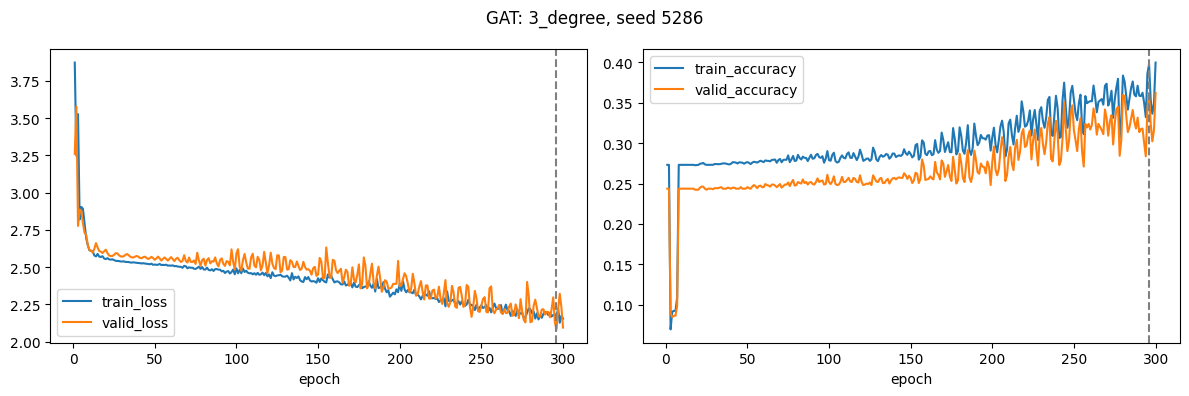

,architecture,condition,seed,best_epoch,input_dim,split,accuracy,macro_f1_present,macro_f1_47,balanced_accuracy,products
0,GAT,3_degree,5286,296,1,train,0.397335,0.104052,0.073058,0.111185,14708
1,GAT,3_degree,5286,296,1,valid,0.361323,0.117174,0.064820,0.128321,1572
2,GAT,3_degree,5286,296,1,test,0.267850,0.063201,0.053788,0.080159,37745


accuracy                 macro_f1_present                  \
           mean       std count             mean       std count   
split                                                              
test   0.257659  0.015501     3         0.063154  0.004834     3   
train  0.395295  0.013173     3         0.129249  0.022798     3   
valid  0.358355  0.018626     3         0.119229  0.008540     3   

      balanced_accuracy                  
                   mean       std count  
split                                    
test           0.075656  0.007034     3  
train          0.129126  0.016922     3  
valid          0.123656  0.010734     3

In [28]:
gat_3_degree = train_condition('GAT', '3_degree')


## Run 4: OGB-only cold start

Reuse run 1 without retraining. Remove all test-incident co-purchase edges and evaluate with the same OGB features. The table compares all four conditions.


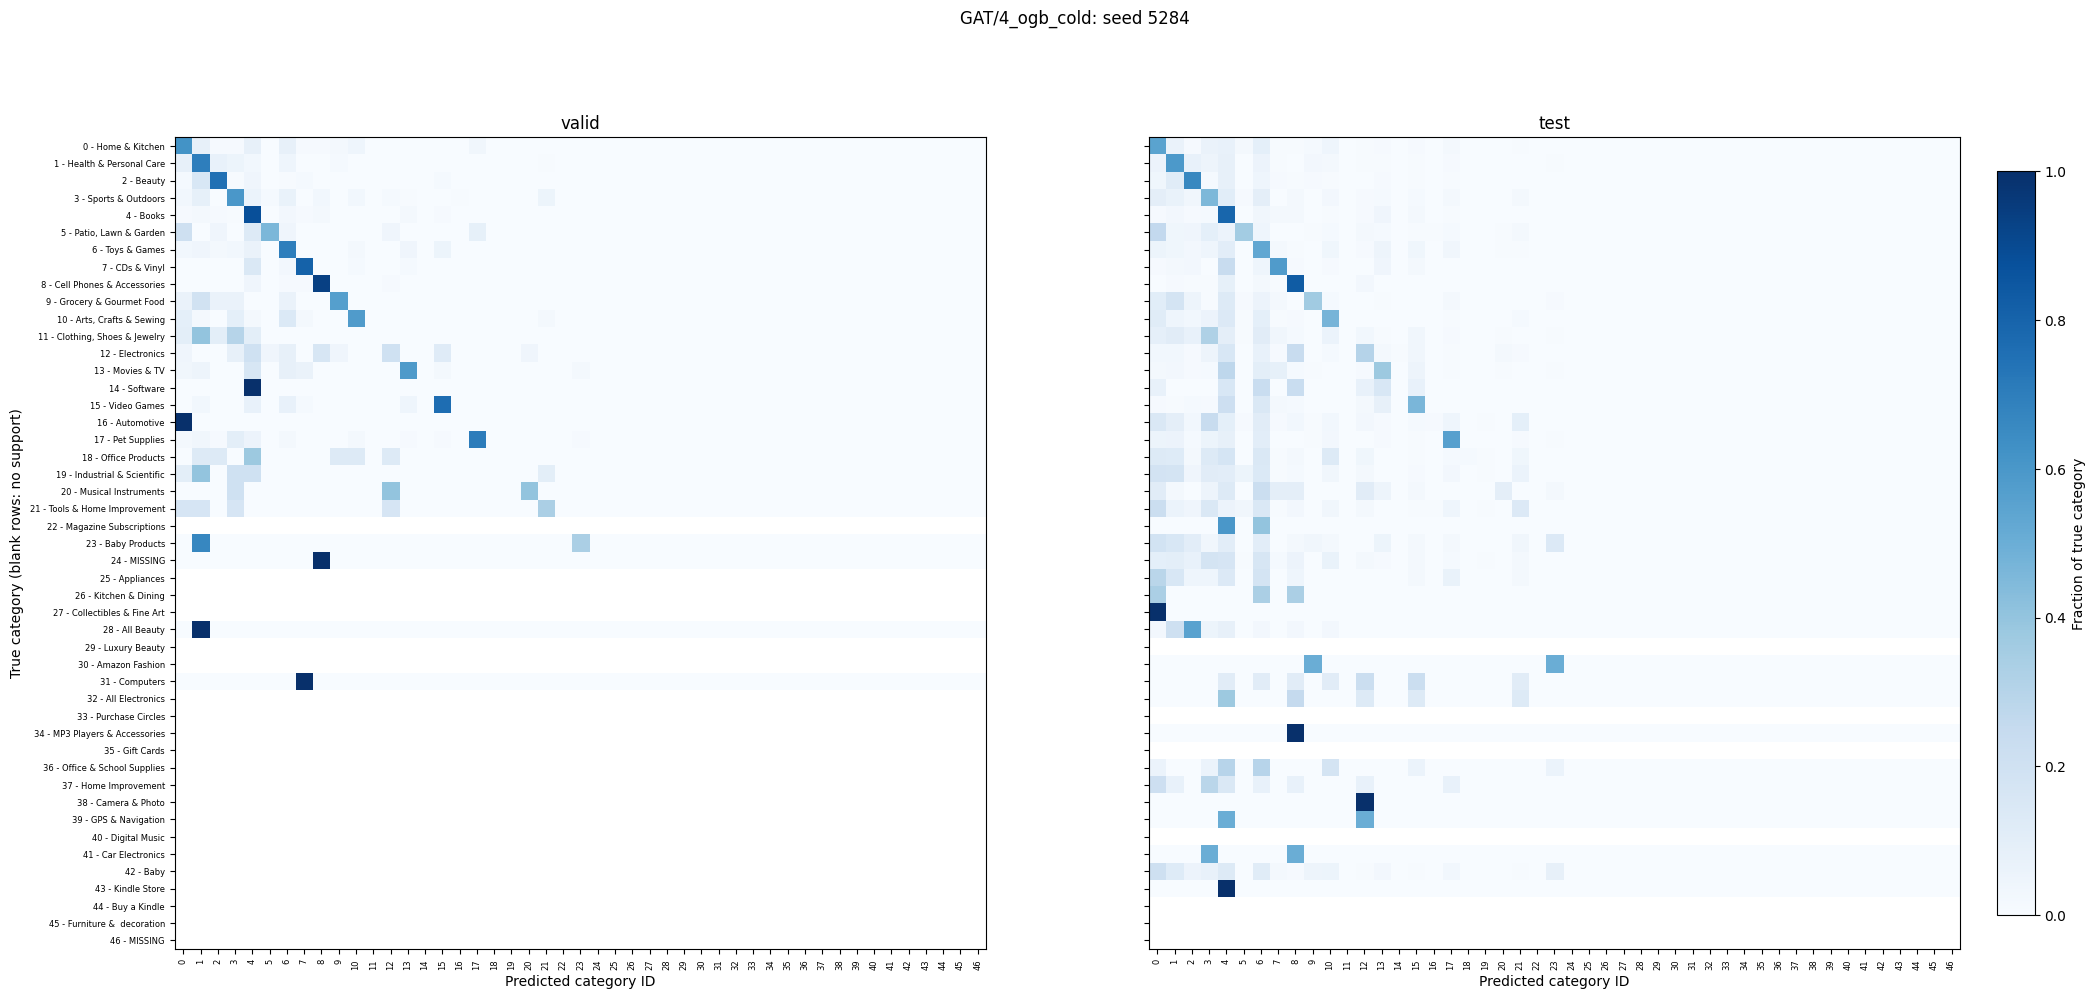

accuracy                 macro_f1_present                  \
                  mean       std count             mean       std count   
condition                                                                 
1_ogb         0.680629  0.002580     3         0.288035  0.004099     3   
2_ogb_degree  0.680832  0.003845     3         0.286248  0.002611     3   
3_degree      0.257659  0.015501     3         0.063154  0.004834     3   
4_ogb_cold    0.489248  0.003340     3         0.194146  0.001966     3   

             balanced_accuracy                  
                          mean       std count  
condition                                       
1_ogb                 0.311209  0.002129     3  
2_ogb_degree          0.310618  0.000561     3  
3_degree              0.075656  0.007034     3  
4_ogb_cold            0.209436  0.002094     3

In [29]:
cold_condition('GAT')


# Final comparison: repeated seeds

The table reports mean, sample standard deviation and seed count for each condition. Standard deviation describes training variability, not uncertainty caused by small validation/test samples. Primary-seed filenames remain compatible with earlier reports; `per_seed/seed_<seed>/` stores every run separately. Matching result files are overwritten when rerun. Models are checkpointed under `outputs/weights/GNN_experiments/02_multi_seed/`.


In [33]:
all_metrics = pd.concat([run['metrics'] for run in experiment_runs.values()], ignore_index=True)
all_test = all_metrics.query("split == 'test'").copy()
output_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed'
all_metrics.to_csv(output_dir / 'all_metrics.csv', index=False)

## Overall performance

Each panel represents one architecture; colours and markers identify the four conditions. Points show seed means and error bars show +/- one sample standard deviation. Train performance is in-sample. Cold-start scores reuse the OGB-only checkpoints and evaluate the modified graph across each split; they are not separately trained models. Macro-F1 averages supported categories separately within each split, so the evaluated category sets differ.

The following two cells read saved metrics independently and do not retrain models.


### Save into table for report summary

In [34]:
# Rebuild the report table from saved scores; no model training is required.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from xml.sax.saxutils import escape
import xml.etree.ElementTree as ET
import pandas as pd
from IPython.display import display

report_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                   if (p / 'requirements.txt').is_file())
report_result_dir = report_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
report_metrics = pd.read_csv(report_result_dir / 'all_metrics.csv')
report_architectures = ['GCN', 'GraphSAGE', 'GAT']
report_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
report_splits = ['train', 'valid', 'test']
report_metrics = report_metrics.loc[
    report_metrics.architecture.isin(report_architectures) &
    report_metrics.condition.isin(report_conditions) & report_metrics.split.isin(report_splits)].copy()
report_keys = ['architecture', 'condition', 'split']
if report_metrics.duplicated(report_keys + ['seed']).any():
    raise ValueError('Duplicate seed-level scores found in all_metrics.csv.')
report_statistics = report_metrics.groupby(report_keys).agg(
    macro_f1_mean=('macro_f1_present', 'mean'), macro_f1_std=('macro_f1_present', 'std'),
    accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'), seed_count=('seed', 'nunique'))
report_order = pd.MultiIndex.from_tuples(
    [(architecture, condition, split) for split in report_splits
     for architecture in report_architectures for condition in report_conditions], names=report_keys)
report_statistics = report_statistics.reindex(report_order).reset_index()
if report_statistics['seed_count'].isna().any():
    raise ValueError('Missing architecture/condition/split rows in the saved results.')
report_statistics['seed_count'] = report_statistics['seed_count'].astype(int)

def report_mean_sd(mean, sd):
    return f'{mean:.4f} {chr(177)} {sd:.4f}' if pd.notna(sd) else f'{mean:.4f} (SD unavailable)'

report_summary = pd.DataFrame({
    'GNN Architecture': report_statistics['architecture'],
    'Condition': report_statistics['condition'],
    'Split': report_statistics['split'].map({'train': 'Train', 'valid': 'Validation', 'test': 'Test'}),
    'Macro-F1': [report_mean_sd(m, s) for m, s in zip(report_statistics.macro_f1_mean, report_statistics.macro_f1_std)],
    'Accuracy': [report_mean_sd(m, s) for m, s in zip(report_statistics.accuracy_mean, report_statistics.accuracy_std)],
})
display(report_summary)
report_output_dir = report_result_dir / 'report_summary'
report_output_dir.mkdir(parents=True, exist_ok=True)
report_summary.to_csv(report_output_dir / 'GNN_report_summary.csv', index=False, encoding='utf-8-sig')
report_statistics.to_csv(report_output_dir / 'GNN_report_summary_numeric.csv', index=False)

# Create an editable Word table using standard-library OOXML (no python-docx needed).
word_ns = 'http://schemas.openxmlformats.org/wordprocessingml/2006/main'
rel_ns = 'http://schemas.openxmlformats.org/officeDocument/2006/relationships'
package_ns = 'http://schemas.openxmlformats.org/package/2006/relationships'

def report_paragraph(text, bold=False):
    emphasis = '<w:b/>' if bold else ''
    return ('<w:p><w:pPr><w:spacing w:after="0" w:line="220" w:lineRule="auto"/></w:pPr>'
            f'<w:r><w:rPr>{emphasis}<w:sz w:val="19"/></w:rPr><w:t xml:space="preserve">'
            + escape(str(text)) + '</w:t></w:r></w:p>')

column_widths = [1800, 2400, 1700, 2250, 2250]
word_rows = []
for row_number, values in enumerate([list(report_summary.columns)] + report_summary.values.tolist()):
    row_props = '<w:trPr><w:tblHeader/><w:cantSplit/></w:trPr>' if row_number == 0 else '<w:trPr><w:cantSplit/></w:trPr>'
    cells = []
    for value, width in zip(values, column_widths):
        shading = '<w:shd w:fill="D9E2F3"/>' if row_number == 0 else ''
        cells.append(f'<w:tc><w:tcPr><w:tcW w:w="{width}" w:type="dxa"/>{shading}</w:tcPr>'
                     + report_paragraph(value, bold=row_number == 0) + '</w:tc>')
    word_rows.append('<w:tr>' + row_props + ''.join(cells) + '</w:tr>')
borders = ''.join(f'<w:{edge} w:val="single" w:sz="4" w:color="999999"/>'
                  for edge in ['top', 'left', 'bottom', 'right', 'insideH', 'insideV'])
table = ('<w:tbl><w:tblPr><w:tblW w:w="10400" w:type="dxa"/>'
         '<w:tblLayout w:type="fixed"/><w:tblBorders>' + borders + '</w:tblBorders>'
         '<w:tblCellMar><w:top w:w="30" w:type="dxa"/><w:bottom w:w="30" w:type="dxa"/>'
         '<w:left w:w="70" w:type="dxa"/><w:right w:w="70" w:type="dxa"/></w:tblCellMar></w:tblPr>'
         '<w:tblGrid>' + ''.join(f'<w:gridCol w:w="{width}"/>' for width in column_widths)
         + '</w:tblGrid>' + ''.join(word_rows) + '</w:tbl>')
seed_counts_text = ', '.join(str(n) for n in sorted(report_statistics.seed_count.unique()))
body = report_paragraph('GNN V2 results summary', bold=True)
body += report_paragraph(f'Mean +/- sample SD across seeds (seed count per row: {seed_counts_text}). Scores are fractions, rounded to four decimals.')
body += report_paragraph('Macro-F1 averages categories present in each split. Cold start reuses the corresponding OGB-only checkpoint.')
body += table
body += '<w:sectPr><w:pgSz w:w="11906" w:h="16838"/><w:pgMar w:top="720" w:right="720" w:bottom="720" w:left="720"/></w:sectPr>'
word_parts = {
    '[Content_Types].xml': '<Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/word/document.xml" ContentType="application/vnd.openxmlformats-officedocument.wordprocessingml.document.main+xml"/></Types>',
    '_rels/.rels': f'<Relationships xmlns="{package_ns}"><Relationship Id="rId1" Type="{rel_ns}/officeDocument" Target="word/document.xml"/></Relationships>',
    'word/document.xml': f'<w:document xmlns:w="{word_ns}"><w:body>{body}</w:body></w:document>',
}
word_output = report_output_dir / 'GNN_report_summary.docx'
with ZipFile(word_output, 'w', ZIP_DEFLATED) as archive:
    for name, content in word_parts.items():
        ET.fromstring(content)
        archive.writestr(name, '<?xml version="1.0" encoding="UTF-8"?>' + content)
print('Saved editable Word table:', word_output)
print('Saved formatted CSV and full-precision numeric summary:', report_output_dir)


,GNN Architecture,Condition,Split,Macro-F1,Accuracy
0,GCN,1_ogb,Train,0.4832 ± 0.0229,0.8910 ± 0.0077
1,GCN,2_ogb_degree,Train,0.5016 ± 0.0218,0.8872 ± 0.0047
2,GCN,3_degree,Train,0.0313 ± 0.0014,0.2852 ± 0.0006
3,GCN,4_ogb_cold,Train,0.3851 ± 0.0120,0.7757 ± 0.0041
4,GraphSAGE,1_ogb,Train,0.4675 ± 0.0209,0.8888 ± 0.0104
5,GraphSAGE,2_ogb_degree,Train,0.4726 ± 0.0349,0.8946 ± 0.0141
6,GraphSAGE,3_degree,Train,0.0392 ± 0.0036,0.3030 ± 0.0041
7,GraphSAGE,4_ogb_cold,Train,0.3664 ± 0.0193,0.7367 ± 0.0077
8,GAT,1_ogb,Train,0.4586 ± 0.0161,0.8710 ± 0.0078
9,GAT,2_ogb_degree,Train,0.4570 ± 0.0133,0.8701 ± 0.0047


Saved editable Word table: <repo>\results\GNN_experiments\02_multi_seed\report_summary\GNN_report_summary.docx
Saved formatted CSV and full-precision numeric summary: <repo>\results\GNN_experiments\02_multi_seed\report_summary


### Plot results for comparison

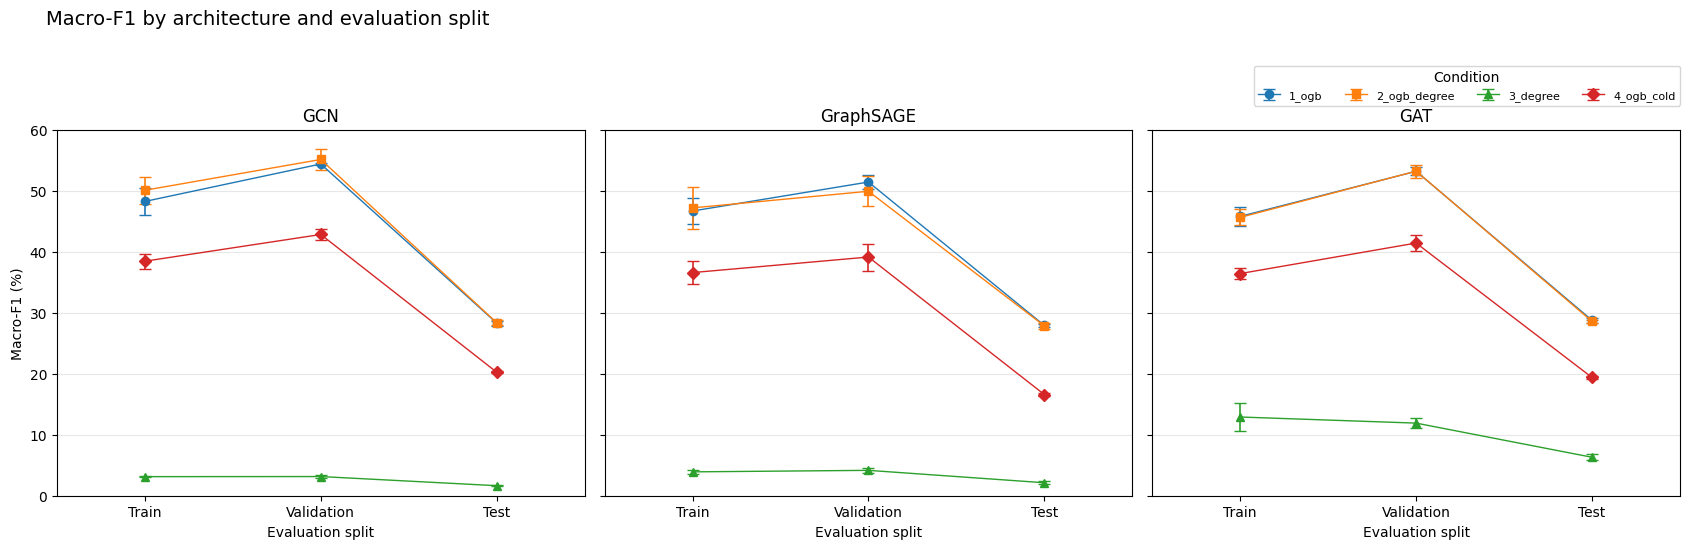

Points: seed means; error bars: +/- one sample standard deviation.
Saved figure to: <repo>\results\GNN_experiments\02_multi_seed\overall_performance\macro_f1_by_split.jpg


In [35]:
# Overall split line comparison: Macro-F1 (independent of the training cells).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

split_plot_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / 'requirements.txt').is_file())
split_plot_dir = split_plot_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
split_plot_metrics = pd.read_csv(split_plot_dir / 'all_metrics.csv')
scatter_metric = 'macro_f1_present'
scatter_architectures = ['GCN', 'GraphSAGE', 'GAT']
scatter_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
scatter_splits = ['train', 'valid', 'test']
scatter_summary = (split_plot_metrics.groupby(['architecture', 'condition', 'split'])[scatter_metric]
                   .agg(['mean', 'std', 'count']))
scatter_colours = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
scatter_markers = ['o', 's', '^', 'D']
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, architecture in zip(axes, scatter_architectures):
    for condition, colour, marker in zip(scatter_conditions, scatter_colours, scatter_markers):
        values = scatter_summary.loc[(architecture, condition)].reindex(scatter_splits)
        if values['mean'].isna().any():
            raise ValueError(f'Missing split scores for {architecture}/{condition}')
        ax.errorbar(np.arange(3), 100 * values['mean'],
                    yerr=100 * values['std'].fillna(0), fmt=marker,
                    color=colour, markersize=6, capsize=4, elinewidth=1.2,
                    linestyle='-', linewidth=1.0, label=condition)
    ax.set(title=architecture, xticks=np.arange(3),
           xticklabels=['Train', 'Validation', 'Test'], xlabel='Evaluation split',
           ylim=(0, 60), xlim=(-0.5, 2.5))
    ax.set_yticks(np.arange(0, 61, 10))
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].set_ylabel('Macro-F1 (%)')
fig.suptitle('Macro-F1 by architecture and evaluation split', fontsize=14, y=0.99, x=0.03, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.90])
# Anchor the legend just above the right subplot, rather than at the figure edge.
fig.legend(legend_handles, legend_labels, title='Condition',
           loc='lower right',
           bbox_to_anchor=(axes[-1].get_position().x1, axes[-1].get_position().y1 + 0.045),
           ncol=4, fontsize=8, frameon=True, borderaxespad=0)
scatter_output_dir = split_plot_dir / 'overall_performance'
scatter_output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(scatter_output_dir / 'macro_f1_by_split.jpg', dpi=250, bbox_inches='tight')
scatter_summary.to_csv(scatter_output_dir / 'macro_f1_by_split_summary.csv')
plt.show()
print('Points: seed means; error bars: +/- one sample standard deviation.')
print('Saved figure to:', scatter_output_dir / 'macro_f1_by_split.jpg')


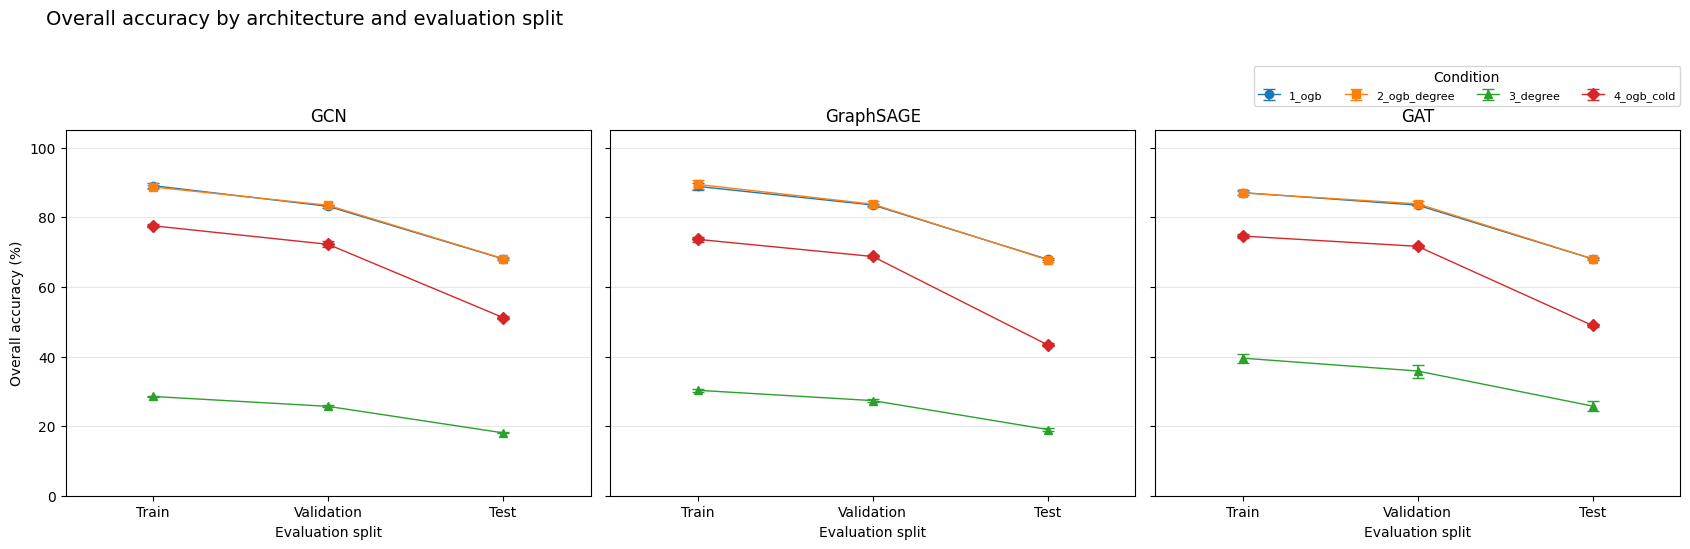

Points: seed means; error bars: +/- one sample standard deviation.
Saved figure to: <repo>\results\GNN_experiments\02_multi_seed\overall_performance\accuracy_by_split.jpg


In [36]:
# Overall split line comparison: Overall accuracy (independent of the training cells).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

split_plot_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / 'requirements.txt').is_file())
split_plot_dir = split_plot_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
split_plot_metrics = pd.read_csv(split_plot_dir / 'all_metrics.csv')
scatter_metric = 'accuracy'
scatter_architectures = ['GCN', 'GraphSAGE', 'GAT']
scatter_conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
scatter_splits = ['train', 'valid', 'test']
scatter_summary = (split_plot_metrics.groupby(['architecture', 'condition', 'split'])[scatter_metric]
                   .agg(['mean', 'std', 'count']))
scatter_colours = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
scatter_markers = ['o', 's', '^', 'D']
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, architecture in zip(axes, scatter_architectures):
    for condition, colour, marker in zip(scatter_conditions, scatter_colours, scatter_markers):
        values = scatter_summary.loc[(architecture, condition)].reindex(scatter_splits)
        if values['mean'].isna().any():
            raise ValueError(f'Missing split scores for {architecture}/{condition}')
        ax.errorbar(np.arange(3), 100 * values['mean'],
                    yerr=100 * values['std'].fillna(0), fmt=marker,
                    color=colour, markersize=6, capsize=4, elinewidth=1.2,
                    linestyle='-', linewidth=1.0, label=condition)
    ax.set(title=architecture, xticks=np.arange(3),
           xticklabels=['Train', 'Validation', 'Test'], xlabel='Evaluation split',
           ylim=(0, 105), xlim=(-0.5, 2.5))
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].set_ylabel('Overall accuracy (%)')
fig.suptitle('Overall accuracy by architecture and evaluation split', fontsize=14, y=0.99, x=0.03, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.90])
# Anchor the legend just above the right subplot, rather than at the figure edge.
fig.legend(legend_handles, legend_labels, title='Condition',
           loc='lower right',
           bbox_to_anchor=(axes[-1].get_position().x1, axes[-1].get_position().y1 + 0.045),
           ncol=4, fontsize=8, frameon=True, borderaxespad=0)
scatter_output_dir = split_plot_dir / 'overall_performance'
scatter_output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(scatter_output_dir / 'accuracy_by_split.jpg', dpi=250, bbox_inches='tight')
scatter_summary.to_csv(scatter_output_dir / 'accuracy_by_split_summary.csv')
plt.show()
print('Points: seed means; error bars: +/- one sample standard deviation.')
print('Saved figure to:', scatter_output_dir / 'accuracy_by_split.jpg')


## Validation results

In [37]:
validation_ranking = (
    all_metrics.query("split == 'valid' and condition != '4_ogb_cold'")
    .groupby(['architecture', 'condition'])[
        ['balanced_accuracy', 'macro_f1_present', 'accuracy']
    ]
    .agg(['mean', 'std', 'count'])
    .sort_values(('macro_f1_present', 'mean'), ascending=False)
)
display(validation_ranking.round(4))
print('Mean and sample standard deviation across seeds; count is the number of seed runs.')

balanced_accuracy               macro_f1_present  \
                                       mean     std count             mean   
architecture condition                                                       
GCN          2_ogb_degree            0.5479  0.0114     3           0.5521   
             1_ogb                   0.5465  0.0066     3           0.5447   
GAT          2_ogb_degree            0.5298  0.0171     3           0.5330   
             1_ogb                   0.5291  0.0125     3           0.5327   
GraphSAGE    1_ogb                   0.5065  0.0143     3           0.5151   
             2_ogb_degree            0.4994  0.0268     3           0.5000   
GAT          3_degree                0.1237  0.0107     3           0.1192   
GraphSAGE    3_degree                0.0578  0.0024     3           0.0417   
GCN          3_degree                0.0480  0.0017     3           0.0315   

                                        accuracy                
                              std count     mean     std count  
architecture condition                                          
GCN          2_ogb_degree  0.0167     3   0.8346  0.0006     3  
             1_ogb         0.0024     3   0.8316  0.0049     3  
GAT          2_ogb_degree  0.0106     3   0.8388  0.0068     3  
             1_ogb         0.0069     3   0.8350  0.0004     3  
GraphSAGE    1_ogb         0.0112     3   0.8355  0.0026     3  
             2_ogb_degree  0.0243     3   0.8378  0.0077     3  
GAT          3_degree      0.0085     3   0.3584  0.0186     3  
GraphSAGE    3_degree      0.0037     3   0.2733  0.0040     3  
GCN          3_degree      0.0017     3   0.2568  0.0026     3

Mean and sample standard deviation across seeds; count is the number of seed runs.


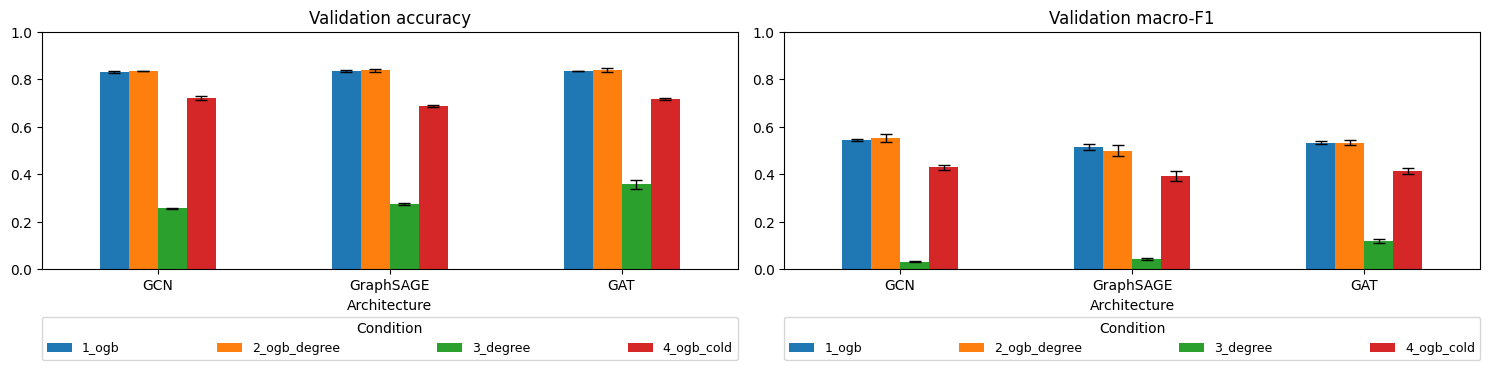

Bar heights show seed means; error bars show +/- one sample standard deviation.


In [38]:
# Plot the validation conditions used for model selection; cold start is evaluated separately.
architecture_order = ['GCN', 'GraphSAGE', 'GAT']
validation_condition_order = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
validation_plot_data = all_metrics.loc[
    (all_metrics['split'] == 'valid') &
    all_metrics['architecture'].isin(architecture_order) &
    all_metrics['condition'].isin(validation_condition_order)
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ['accuracy', 'macro_f1_present'],
                            ['Validation accuracy', 'Validation macro-F1']):
    values = validation_plot_data.pivot_table(
        index='architecture', columns='condition', values=metric, aggfunc='mean'
    ).reindex(index=architecture_order, columns=validation_condition_order)
    deviations = validation_plot_data.pivot_table(
        index='architecture', columns='condition', values=metric, aggfunc='std'
    ).reindex(index=architecture_order, columns=validation_condition_order)
    values.plot.bar(ax=ax, yerr=deviations.fillna(0), capsize=4,
                    error_kw={'elinewidth': 1, 'capthick': 1})
    ax.set(title=title, ylim=(0, 1), xlabel='Architecture')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Condition', loc='upper left',
              bbox_to_anchor=(0, -0.20, 1, 0), mode='expand',
              ncol=len(ax.get_legend_handles_labels()[1]), borderaxespad=0, fontsize=9, frameon=True)
plt.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()
print('Bar heights show seed means; error bars show +/- one sample standard deviation.')


## Test results

accuracy                 macro_f1_present  \
                               mean       std count             mean   
architecture condition                                                 
GAT          1_ogb         0.680629  0.002580     3         0.288035   
             2_ogb_degree  0.680832  0.003845     3         0.286248   
             3_degree      0.257659  0.015501     3         0.063154   
             4_ogb_cold    0.489248  0.003340     3         0.194146   
GCN          1_ogb         0.680646  0.002667     3         0.283469   
             2_ogb_degree  0.681415  0.005279     3         0.284026   
             3_degree      0.180660  0.001673     3         0.016469   
             4_ogb_cold    0.511927  0.005003     3         0.202786   
GraphSAGE    1_ogb         0.679251  0.002816     3         0.279531   
             2_ogb_degree  0.677732  0.006264     3         0.278857   
             3_degree      0.190295  0.003097     3         0.021300   
             4_ogb_cold    0.433347  0.004291     3         0.166105   

                                          macro_f1_47                  \
                                std count        mean       std count   
architecture condition                                                  
GAT          1_ogb         0.004099     3    0.245136  0.003489     3   
             2_ogb_degree  0.002611     3    0.243616  0.002222     3   
             3_degree      0.004834     3    0.053748  0.004114     3   
             4_ogb_cold    0.001966     3    0.165231  0.001673     3   
GCN          1_ogb         0.004219     3    0.241250  0.003591     3   
             2_ogb_degree  0.004384     3    0.241724  0.003731     3   
             3_degree      0.001242     3    0.014016  0.001057     3   
             4_ogb_cold    0.001798     3    0.172584  0.001530     3   
GraphSAGE    1_ogb         0.002854     3    0.237899  0.002429     3   
             2_ogb_degree  0.004506     3    0.237325  0.003835     3   
             3_degree      0.002066     3    0.018127  0.001758     3   
             4_ogb_cold    0.002592     3    0.141366  0.002206     3   

                          balanced_accuracy                  
                                       mean       std count  
architecture condition                                       
GAT          1_ogb                 0.311209  0.002129     3  
             2_ogb_degree          0.310618  0.000561     3  
             3_degree              0.075656  0.007034     3  
             4_ogb_cold            0.209436  0.002094     3  
GCN          1_ogb                 0.307736  0.003449     3  
             2_ogb_degree          0.308549  0.004842     3  
             3_degree              0.030219  0.001147     3  
             4_ogb_cold            0.219794  0.000776     3  
GraphSAGE    1_ogb                 0.304352  0.003296     3  
             2_ogb_degree          0.305672  0.007541     3  
             3_degree              0.036817  0.002208     3  
             4_ogb_cold            0.176763  0.002967     3

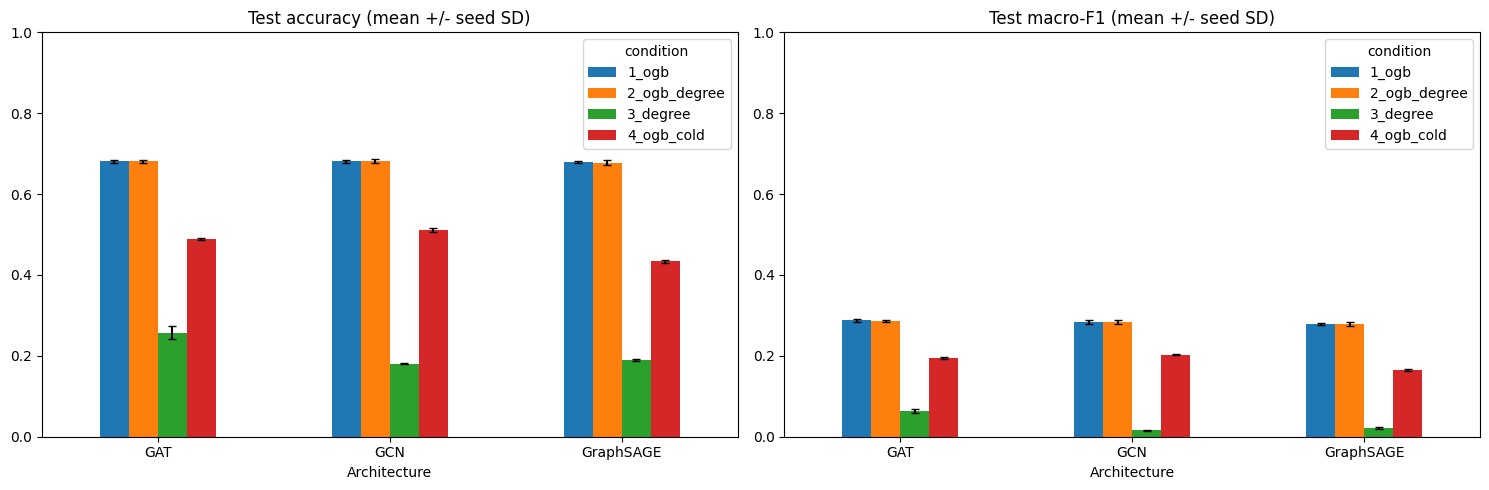

Saved repeated-seed metrics to: <repo>\results\GNN_experiments\02_multi_seed


In [39]:
all_test.to_csv(output_dir / 'test_comparison.csv', index=False)
summary = seed_summary(all_metrics, ['architecture', 'condition', 'split'],
                       ['accuracy', 'macro_f1_present', 'macro_f1_47', 'balanced_accuracy'])
summary.to_csv(output_dir / 'seed_summary.csv')
display(summary.xs('test', level='split'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ['accuracy', 'macro_f1_present'], ['Test accuracy', 'Test macro-F1']):
    means = all_test.pivot_table(index='architecture', columns='condition', values=metric, aggfunc='mean')
    deviations = all_test.pivot_table(index='architecture', columns='condition', values=metric, aggfunc='std')
    means.plot.bar(ax=ax, yerr=deviations.fillna(0), capsize=3)
    ax.set(title=title + ' (mean +/- seed SD)', ylim=(0, 1), xlabel='Architecture')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print('Saved repeated-seed metrics to:', output_dir)


## Paired seed comparisons: validation and test macro-F1

This section runs directly from `results/1_gnn_ogb/02_multi_seed/all_metrics.csv`, without training or rerunning earlier cells. Select the **observed leader using mean validation macro-F1** among the three trained feature conditions; retain that same reference for test comparisons.

For each matching seed, calculate **candidate minus reference**. The table reports the mean difference and a nominal 95% paired t-interval: `mean_difference +/- t(0.975, n-1) * SD(differences) / sqrt(n)`. Negative values favour the reference. An interval crossing zero does not establish equivalence; a wholly negative interval provides only nominal evidence favouring the reference.

**Interpret cautiously:** three seeds give two degrees of freedom and a t multiplier of about 4.303. Normality of seed differences cannot be assessed reliably. Matching seed IDs does not mean different architectures use identical initial weights or dropout masks. These intervals describe training variability on fixed evaluation products, not uncertainty from sampled products. Validation-leader selection and multiple comparisons make the intervals exploratory; they are not selection-adjusted or simultaneous confidence statements. Test results do not change the selected leader.

Cold-start rows are excluded from leader selection and the main ranking. A separate paired comparison below contrasts each architecture's cold-start predictions with its own OGB-only baseline.


In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display

paired_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                   if (p / 'requirements.txt').is_file())
paired_result_dir = paired_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
paired_output_dir = paired_result_dir / 'paired_comparisons'
paired_output_dir.mkdir(parents=True, exist_ok=True)
paired_data = pd.read_csv(paired_result_dir / 'all_metrics.csv')
paired_architectures = ['GCN', 'GraphSAGE', 'GAT']
paired_conditions = ['1_ogb', '2_ogb_degree', '3_degree']
paired_data = paired_data.loc[paired_data.architecture.isin(paired_architectures)].copy()
keys = ['architecture', 'condition', 'split', 'seed']
if paired_data.duplicated(keys).any():
    raise ValueError('Duplicate seed-level metrics found; resolve duplicates before comparing.')
selection = paired_data.loc[(paired_data.split == 'valid') & paired_data.condition.isin(paired_conditions)]
seed_sets = selection.groupby(['architecture', 'condition'])['seed'].apply(lambda x: frozenset(x))
if len(seed_sets) != 9 or len(set(seed_sets)) != 1:
    raise ValueError('Expected all nine trained candidates with exactly matching validation seeds.')
if len(seed_sets.iloc[0]) < 2:
    raise ValueError('At least two matched seeds are required for t-intervals; three are configured.')
leader_ranking = (selection.groupby(['architecture', 'condition'])['macro_f1_present'].mean()
                  .sort_values(ascending=False, kind='stable'))
leader_architecture, leader_condition = leader_ranking.index[0]
print(f'Observed validation leader: {leader_architecture} / {leader_condition}; '
      f'mean macro-F1 = {leader_ranking.iloc[0]:.4f}')
leader_ranking.rename('mean_validation_macro_f1').to_csv(paired_output_dir / 'validation_leader_ranking.csv')


def pair_scores(candidate, reference, metadata):
    candidate = candidate.set_index('seed')['macro_f1_present'].sort_index()
    reference = reference.set_index('seed')['macro_f1_present'].sort_index()
    if not candidate.index.equals(reference.index):
        raise ValueError(f'Unmatched seeds for {metadata}')
    differences = candidate - reference
    if not np.isfinite(differences.to_numpy()).all():
        raise ValueError('Non-finite macro-F1 scores cannot be compared.')
    n_pairs = len(differences)
    if n_pairs < 2:
        raise ValueError('At least two pairs are required.')
    mean_difference = float(differences.mean())
    sd_difference = float(differences.std(ddof=1))
    standard_error = sd_difference / np.sqrt(n_pairs)
    t_critical = float(student_t.ppf(0.975, df=n_pairs - 1))
    margin = t_critical * standard_error
    lower, upper = mean_difference - margin, mean_difference + margin
    status = ('CI below zero' if upper < 0 else 'CI above zero' if lower > 0
              else 'CI includes zero')
    summary_row = dict(**metadata, n_pairs=n_pairs, candidate_mean=float(candidate.mean()),
                       reference_mean=float(reference.mean()), mean_difference=mean_difference,
                       sd_difference=sd_difference, standard_error=standard_error,
                       ci95_lower=lower, ci95_upper=upper, t_critical=t_critical,
                       nominal_interval=status)
    seed_rows = [dict(**metadata, seed=int(seed), candidate_score=float(candidate.loc[seed]),
                      reference_score=float(reference.loc[seed]), difference=float(differences.loc[seed]))
                 for seed in differences.index]
    return summary_row, seed_rows


def plot_paired_intervals(table, title, filename):
    splits = [split for split in ['valid', 'test'] if split in set(table['split'])]
    fig, axes = plt.subplots(1, len(splits), figsize=(max(10, 8 * len(splits)), 6), squeeze=False)
    for ax, split in zip(axes.flat, splits):
        frame = (table.loc[table.split == split]
                 .sort_values('candidate_mean', ascending=False, kind='stable').reset_index(drop=True))
        positions = np.arange(len(frame))
        errors = np.vstack([frame.mean_difference - frame.ci95_lower,
                            frame.ci95_upper - frame.mean_difference])
        ax.errorbar(positions, frame.mean_difference, yerr=errors,
                    fmt='o', capsize=4, color='steelblue', ecolor='steelblue')
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set(xticks=positions, xticklabels=frame.label,
               ylabel='Macro-F1 difference (candidate - reference)',
               xlabel='Architecture-condition (descending mean macro-F1)',
               title='Validation' if split == 'valid' else 'Test')
        ax.tick_params(axis='x', rotation=35)
        for label in ax.get_xticklabels():
            label.set_horizontalalignment('right')
        ax.grid(axis='y', alpha=0.2)
    fig.suptitle(title + '\nNominal 95% paired t-intervals across matching seeds')
    plt.tight_layout()
    fig.savefig(paired_output_dir / filename, dpi=200, bbox_inches='tight')
    plt.show()


paired_split_tables = {}
paired_split_differences = {}


def run_paired_split(split):
    comparison_rows, seed_rows = [], []
    reference = paired_data.loc[(paired_data.split == split) &
        (paired_data.architecture == leader_architecture) & (paired_data.condition == leader_condition)]
    for architecture in paired_architectures:
        for condition in paired_conditions:
            if (architecture, condition) == (leader_architecture, leader_condition):
                continue  # Reference compared with itself has no uncertainty to estimate.
            candidate = paired_data.loc[(paired_data.split == split) &
                (paired_data.architecture == architecture) & (paired_data.condition == condition)]
            metadata = dict(split=split, architecture=architecture, condition=condition,
                            reference_architecture=leader_architecture, reference_condition=leader_condition,
                            label=f'{architecture} / {condition}')
            row, differences = pair_scores(candidate, reference, metadata)
            comparison_rows.append(row)
            seed_rows.extend(differences)
    result = (pd.DataFrame(comparison_rows)
              .sort_values('candidate_mean', ascending=False, kind='stable').reset_index(drop=True))
    differences = pd.DataFrame(seed_rows)
    paired_split_tables[split] = result
    paired_split_differences[split] = differences
    result.to_csv(paired_output_dir / f'{split}_leader_paired_comparison.csv', index=False)
    differences.to_csv(paired_output_dir / f'{split}_leader_seed_differences.csv', index=False)
    # Refresh combined files with the splits evaluated in this session.
    pd.concat(paired_split_tables.values(), ignore_index=True).to_csv(
        paired_output_dir / 'leader_paired_comparison.csv', index=False)
    pd.concat(paired_split_differences.values(), ignore_index=True).to_csv(
        paired_output_dir / 'leader_seed_differences.csv', index=False)
    print(f'{split}: sorted by candidate mean macro-F1, highest first.')
    print(f'Reference: {leader_architecture} / {leader_condition}; same validation-selected reference for both splits.')
    display(result[['label', 'n_pairs', 'candidate_mean', 'reference_mean', 'mean_difference',
                    'sd_difference', 'ci95_lower', 'ci95_upper', 'nominal_interval']].round(4))
    plot_paired_intervals(result, f'Reference: {leader_architecture} / {leader_condition}',
                         f'{split}_leader_intervals.jpg')
    return result


Observed validation leader: GCN / 2_ogb_degree; mean macro-F1 = 0.5521


### Validation paired comparisons

Candidates are sorted by mean validation macro-F1, highest first. The observed reference is omitted from its own comparison. Run the shared paired setup above first.


valid: sorted by candidate mean macro-F1, highest first.
Reference: GCN / 2_ogb_degree; same validation-selected reference for both splits.


,label,n_pairs,candidate_mean,reference_mean,mean_difference,sd_difference,ci95_lower,ci95_upper,nominal_interval
0,GCN / 1_ogb,3,0.5447,0.5521,-0.0074,0.0179,-0.0519,0.0371,CI includes zero
1,GAT / 2_ogb_degree,3,0.5330,0.5521,-0.0192,0.0225,-0.0751,0.0367,CI includes zero
2,GAT / 1_ogb,3,0.5327,0.5521,-0.0194,0.0233,-0.0774,0.0386,CI includes zero
3,GraphSAGE / 1_ogb,3,0.5151,0.5521,-0.0370,0.0280,-0.1065,0.0324,CI includes zero
4,GraphSAGE / 2_ogb_degree,3,0.5000,0.5521,-0.0522,0.0359,-0.1414,0.0370,CI includes zero
5,GAT / 3_degree,3,0.1192,0.5521,-0.4329,0.0200,-0.4825,-0.3833,CI below zero
6,GraphSAGE / 3_degree,3,0.0417,0.5521,-0.5105,0.0169,-0.5525,-0.4685,CI below zero
7,GCN / 3_degree,3,0.0315,0.5521,-0.5207,0.0182,-0.5658,-0.4755,CI below zero


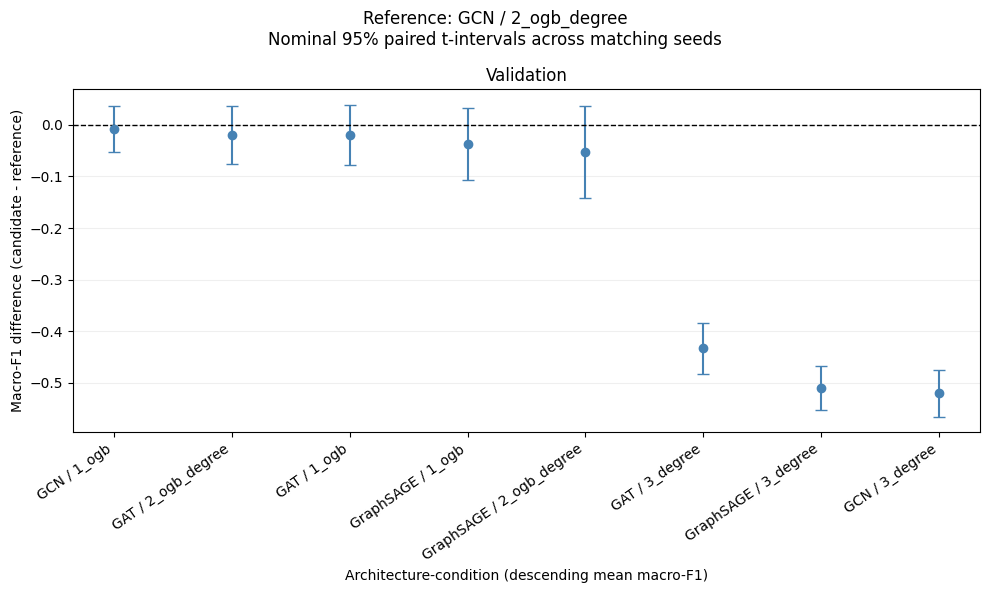

In [41]:
validation_paired_comparison = run_paired_split('valid')


### Test paired comparisons

Candidates are sorted by mean test macro-F1, highest first. The reference remains the validation-selected leader; this display order does not select a new model. Run the shared paired setup above first; running the validation comparison cell is optional.


test: sorted by candidate mean macro-F1, highest first.
Reference: GCN / 2_ogb_degree; same validation-selected reference for both splits.


,label,n_pairs,candidate_mean,reference_mean,mean_difference,sd_difference,ci95_lower,ci95_upper,nominal_interval
0,GAT / 1_ogb,3,0.2880,0.284,0.0040,0.0056,-0.0098,0.0178,CI includes zero
1,GAT / 2_ogb_degree,3,0.2862,0.284,0.0022,0.0066,-0.0142,0.0186,CI includes zero
2,GCN / 1_ogb,3,0.2835,0.284,-0.0006,0.0031,-0.0082,0.0071,CI includes zero
3,GraphSAGE / 1_ogb,3,0.2795,0.284,-0.0045,0.0069,-0.0217,0.0127,CI includes zero
4,GraphSAGE / 2_ogb_degree,3,0.2789,0.284,-0.0052,0.0057,-0.0194,0.0090,CI includes zero
5,GAT / 3_degree,3,0.0632,0.284,-0.2209,0.0076,-0.2399,-0.2019,CI below zero
6,GraphSAGE / 3_degree,3,0.0213,0.284,-0.2627,0.0057,-0.2769,-0.2485,CI below zero
7,GCN / 3_degree,3,0.0165,0.284,-0.2676,0.0054,-0.2809,-0.2542,CI below zero


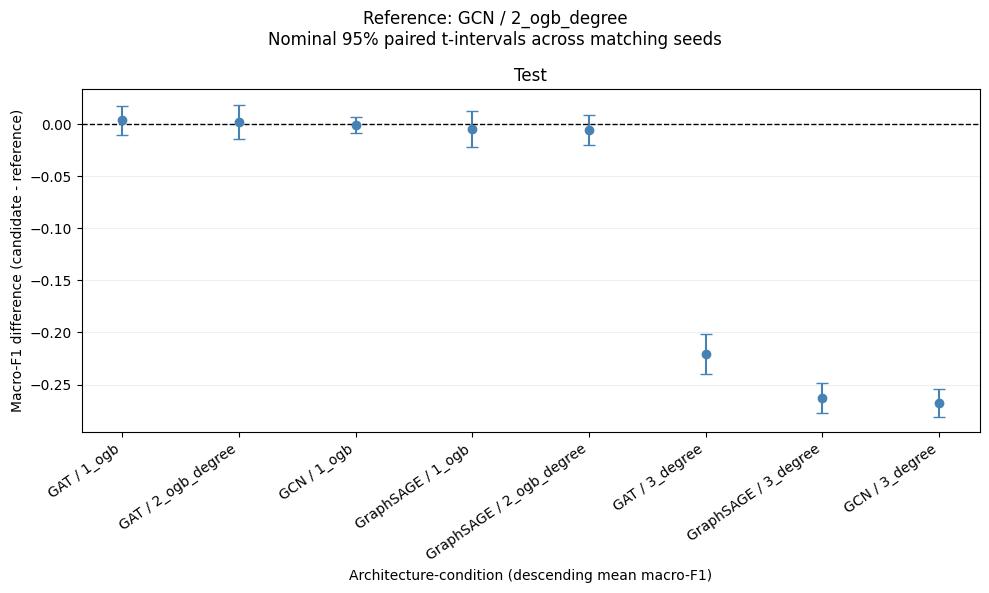

In [42]:
test_paired_comparison = run_paired_split('test')


### Paired cold-start robustness checks

Each cold-start score is paired with the same architecture and seed's OGB-only score. Negative differences indicate a drop after removing test-incident connections. Validation cold-start results are descriptive only and do not select a new checkpoint or leader.


,split,architecture,n_pairs,mean_difference,ci95_lower,ci95_upper,nominal_interval
0,test,GCN,3,-0.0807,-0.0868,-0.0746,CI below zero
1,test,GAT,3,-0.0939,-0.1023,-0.0855,CI below zero
2,test,GraphSAGE,3,-0.1134,-0.1251,-0.1018,CI below zero
3,valid,GCN,3,-0.1158,-0.1391,-0.0925,CI below zero
4,valid,GAT,3,-0.1178,-0.1401,-0.0955,CI below zero
5,valid,GraphSAGE,3,-0.1232,-0.1528,-0.0936,CI below zero


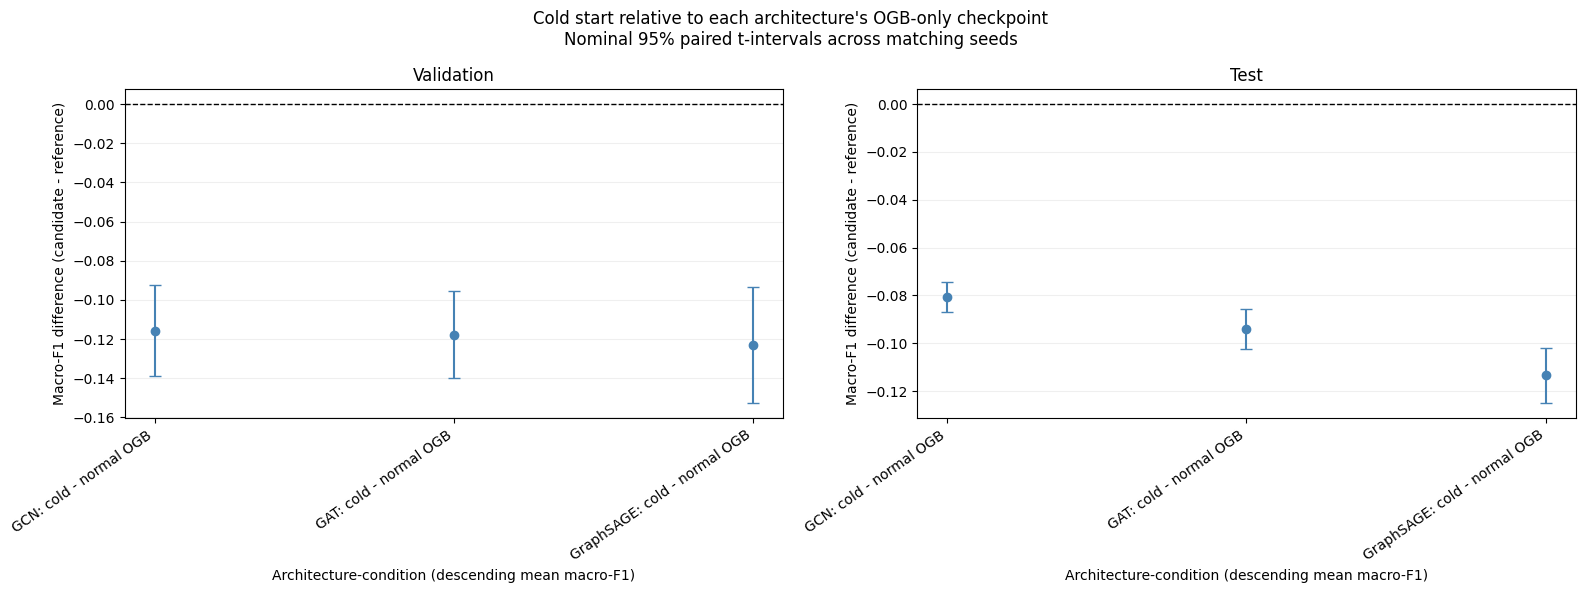

In [43]:
cold_rows, cold_seed_rows = [], []
for split in ['valid', 'test']:
    for architecture in paired_architectures:
        candidate = paired_data.loc[(paired_data.split == split) &
            (paired_data.architecture == architecture) & (paired_data.condition == '4_ogb_cold')]
        reference = paired_data.loc[(paired_data.split == split) &
            (paired_data.architecture == architecture) & (paired_data.condition == '1_ogb')]
        metadata = dict(split=split, architecture=architecture, condition='4_ogb_cold',
                        reference_architecture=architecture, reference_condition='1_ogb',
                        label=f'{architecture}: cold - normal OGB')
        row, differences = pair_scores(candidate, reference, metadata)
        cold_rows.append(row); cold_seed_rows.extend(differences)
cold_paired_comparison = pd.DataFrame(cold_rows).sort_values(
    ['split', 'candidate_mean'], ascending=[True, False], kind='stable').reset_index(drop=True)
cold_paired_comparison.to_csv(paired_output_dir / 'cold_start_paired_comparison.csv', index=False)
pd.DataFrame(cold_seed_rows).to_csv(paired_output_dir / 'cold_start_seed_differences.csv', index=False)
display(cold_paired_comparison[['split', 'architecture', 'n_pairs', 'mean_difference',
                               'ci95_lower', 'ci95_upper', 'nominal_interval']].round(4))
plot_paired_intervals(cold_paired_comparison, "Cold start relative to each architecture's OGB-only checkpoint",
                     'validation_test_cold_intervals.jpg')


# Supplementary diagnostics for category split differences

These cells use the predictions and diagnostic CSVs produced by the new runs; no retraining is needed after these artifacts exist. They compare:

- **Validation versus test:** per-category precision, recall, F1, support, training support and recall intervals. No-support recall intervals are undefined, rather than zero-confidence observations.
- **Seen versus unseen categories:** recompute scores after filtering products by true category. Predictions into excluded categories remain errors; predictions are never forced into the retained label set.
- **Training support groups:** 0, 1-9, 10-99, 100-999 and 1000+ training products. These descriptive thresholds use training counts only. Group macro-F1 and balanced accuracy weight supported categories equally; group accuracy weights products.
- **Common category mixture:** validation/test confusion matrices are reweighted to a uniform distribution over categories present in BOTH splits. This is a supplementary comparison, not a replacement benchmark. It changes the question, and does not eliminate differences between products within categories.

**Uncertainty:** 95% Wilson recall intervals are approximate marginal binomial intervals conditional on a fitted model. They assume independent evaluation outcomes; connected products can violate that assumption, so interpret them descriptively. Multiple seeds measure training variability separately; never pool repeated predictions of the same product as independent samples. Intervals do not establish causality or correct sparse categories. Checkpoints and hyperparameters still use validation data only.


Full versus seen/unseen test evaluation (recomputed precision and F1):


accuracy                 macro_f1_present  \
                                      mean       std count             mean   
architecture condition    group                                               
GAT          1_ogb        full    0.680629  0.002580     3         0.288035   
                          seen    0.696347  0.002639     3         0.381432   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.680832  0.003845     3         0.286248   
                          seen    0.696555  0.003934     3         0.378399   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.257659  0.015501     3         0.063154   
                          seen    0.263609  0.015859     3         0.082310   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.489248  0.003340     3         0.194146   
                          seen    0.500547  0.003418     3         0.255003   
                          unseen  0.000000  0.000000     3         0.000000   
GCN          1_ogb        full    0.680646  0.002667     3         0.283469   
                          seen    0.696365  0.002729     3         0.374675   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.681415  0.005279     3         0.284026   
                          seen    0.697151  0.005401     3         0.375327   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.180660  0.001673     3         0.016469   
                          seen    0.184832  0.001712     3         0.021493   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.511927  0.005003     3         0.202786   
                          seen    0.523749  0.005119     3         0.266015   
                          unseen  0.000000  0.000000     3         0.000000   
GraphSAGE    1_ogb        full    0.679251  0.002816     3         0.279531   
                          seen    0.694938  0.002882     3         0.368688   
                          unseen  0.000000  0.000000     3         0.000000   
             2_ogb_degree full    0.677732  0.006264     3         0.278857   
                          seen    0.693384  0.006409     3         0.366978   
                          unseen  0.000000  0.000000     3         0.000000   
             3_degree     full    0.190295  0.003097     3         0.021300   
                          seen    0.194689  0.003169     3         0.027789   
                          unseen  0.000000  0.000000     3         0.000000   
             4_ogb_cold   full    0.433347  0.004291     3         0.166105   
                          seen    0.443354  0.004390     3         0.217310   
                          unseen  0.000000  0.000000     3         0.000000   

                                                 balanced_accuracy            \
                                       std count              mean       std   
architecture condition    group                                                
GAT          1_ogb        full    0.004099     3          0.311209  0.002129   
                          seen    0.004967     3          0.401560  0.002747   
                          unseen  0.000000     3          0.000000  0.000000   
             2_ogb_degree full    0.002611     3          0.310618  0.000561   
                          seen    0.002908     3          0.400797  0.000723   
                          unseen  0.000000     3          0.000000  0.000000   
             3_degree     full    0.004834     3          0.075656  0.007034   
                          seen    0.006414     3          0.097620  0.009076   
                          unseen  0.000000     3          0.000000  0.00

Training-support groups:


accuracy                  \
                                                        mean       std count   
architecture condition    group                                                
GAT          1_ogb        train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.028357  0.012270     3   
                          train_support_100-999     0.672785  0.003479     3   
                          train_support_1000+       0.881112  0.002428     3   
             2_ogb_degree train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.025670  0.004913     3   
                          train_support_100-999     0.674495  0.008952     3   
                          train_support_1000+       0.880303  0.002453     3   
             3_degree     train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.000000  0.000000     3   
                          train_support_100-999     0.159390  0.013664     3   
                          train_support_1000+       0.442889  0.022309     3   
             4_ogb_cold   train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.013344  0.004474     3   
                          train_support_100-999     0.417294  0.008181     3   
                          train_support_1000+       0.709343  0.006263     3   
GCN          1_ogb        train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.020387  0.006996     3   
                          train_support_100-999     0.675958  0.004593     3   
                          train_support_1000+       0.879429  0.000653     3   
             2_ogb_degree train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.034010  0.012708     3   
                          train_support_100-999     0.677288  0.012621     3   
                          train_support_1000+       0.876659  0.004937     3   
             3_degree     train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.000000  0.000000     3   
                          train_support_100-999     0.028348  0.002544     3   
                          train_support_1000+       0.404069  0.001452     3   
             4_ogb_cold   train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.010008  0.004343     3   
                          train_support_100-999     0.455654  0.007709     3   
                          train_support_1000+       0.721807  0.003525     3   
GraphSAGE    1_ogb        train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       0.011954  0.005704     3   
                          train_support_100-999     0.670999  0.004493     3   
                          train_support_1000+       0.883562  0.002120     3   
             2_ogb_degree train_support_0 (unseen)  0.000000  0.000000     3   
                          train_support_1-9         0.000000  0.000000     3   
                          train_support_10-99       

Validation/test after fixing the category mixture (common categories only):


accuracy                 macro_f1_present  \
                                     mean       std count             mean   
architecture condition    split                                              
GAT          1_ogb        test   0.478783  0.003275     3         0.403116   
                          valid  0.529059  0.012531     3         0.472575   
             2_ogb_degree test   0.477873  0.000862     3         0.401199   
                          valid  0.529784  0.017147     3         0.470973   
             3_degree     test   0.116393  0.010821     3         0.078507   
                          valid  0.123656  0.010734     3         0.091137   
             4_ogb_cold   test   0.322209  0.003221     3         0.269316   
                          valid  0.409023  0.013748     3         0.353056   
GCN          1_ogb        test   0.473441  0.005306     3         0.394747   
                          valid  0.546504  0.006604     3         0.490520   
             2_ogb_degree test   0.474691  0.007449     3         0.396374   
                          valid  0.547918  0.011376     3         0.492118   
             3_degree     test   0.046490  0.001764     3         0.013344   
                          valid  0.047960  0.001690     3         0.014813   
             4_ogb_cold   test   0.338145  0.001194     3         0.279619   
                          valid  0.421134  0.007770     3         0.372328   
GraphSAGE    1_ogb        test   0.468234  0.005070     3         0.385310   
                          valid  0.506514  0.014277     3         0.444661   
             2_ogb_degree test   0.470265  0.011602     3         0.385115   
                          valid  0.499368  0.026764     3         0.421750   
             3_degree     test   0.056642  0.003397     3         0.019731   
                          valid  0.057837  0.002371     3         0.022476   
             4_ogb_cold   test   0.271943  0.004564     3         0.228090   
                          valid  0.382727  0.019384     3         0.331734   

                                                balanced_accuracy            \
                                      std count              mean       std   
architecture condition    split                                               
GAT          1_ogb        test   0.004240     3          0.478783  0.003275   
                          valid  0.016010     3          0.529059  0.012531   
             2_ogb_degree test   0.001550     3          0.477873  0.000862   
                          valid  0.019031     3          0.529784  0.017147   
             3_degree     test   0.005437     3          0.116393  0.010821   
                          valid  0.005658     3          0.123656  0.010734   
             4_ogb_cold   test   0.003721     3          0.322209  0.003221   
                          valid  0.023795     3          0.409023  0.013748   
GCN          1_ogb        test   0.009223     3          0.473441  0.005306   
                          valid  0.010743     3          0.546504  0.006604   
             2_ogb_degree test   0.010794     3          0.474691  0.007449   
                          valid  0.019169     3          0.547918  0.011376   
             3_degree     test   0.001536     3          0.046490  0.001764   
                          valid  0.001097     3          0.047960  0.001690   
             4_ogb_cold   test   0.004202     3          0.338145  0.001194   
                          valid  0.005187     3          0.421134  0.007770   
GraphSAGE    1_ogb        test   0.005754     3          0.468234  0.005070   
                          valid  0.021593     3          0.506514  0.014277   
             2_ogb_degree test   0.015173     3          0.470265  0.011602   
                          valid  0.034640     3          0.499368  0.026764   
             3_degree     test   0.002958     3          0.056642  0.003397   
                          vali

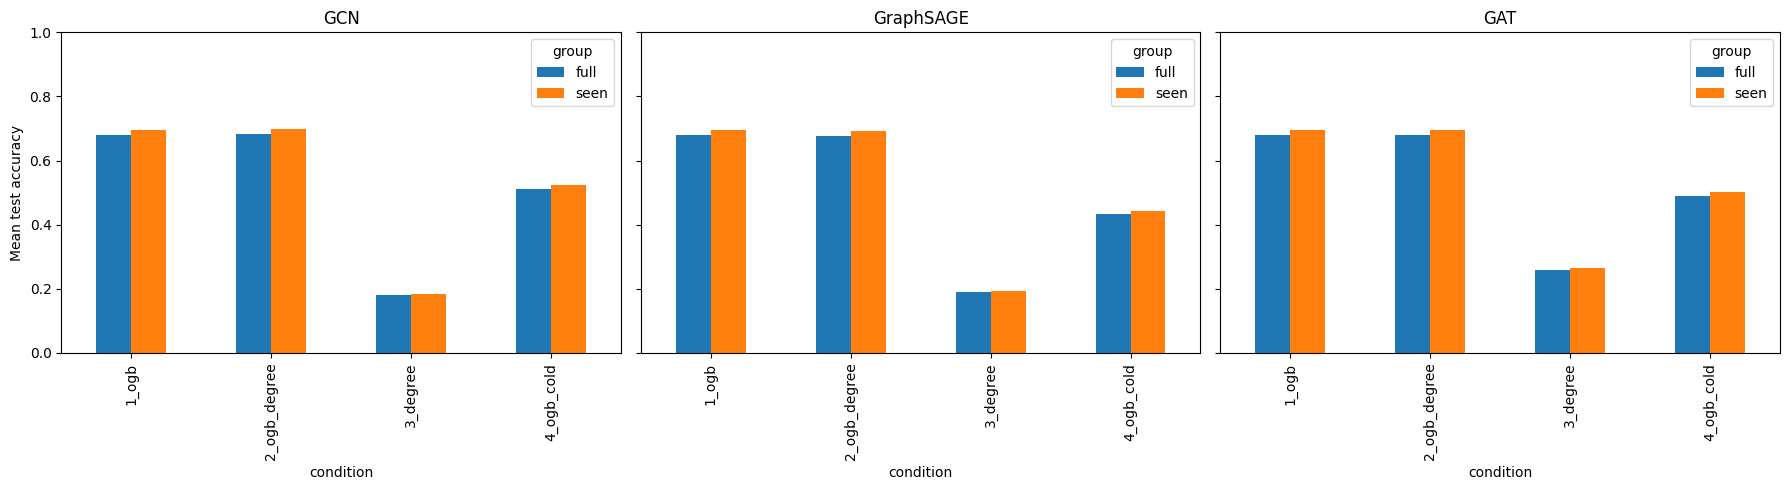

Example category comparison: GCN, OGB-only, primary seed


,category_id,category,support_valid,predicted_support_valid,correct_valid,precision_valid,recall_valid,f1_valid,recall_ci95_lower_valid,recall_ci95_upper_valid,...,recall_test,f1_test,recall_ci95_lower_test,recall_ci95_upper_test,precision_test_minus_valid,recall_test_minus_valid,f1_test_minus_valid,architecture,condition,seed
0,0,Home & Kitchen,89,83,60,0.722892,0.674157,0.697674,5.713423e-01,0.762560,...,0.726457,0.577154,7.053017e-01,0.746640,-0.244133,0.052300,-0.120520,GCN,1_ogb,5284
1,1,Health & Personal Care,136,132,93,0.704545,0.683824,0.694030,6.015419e-01,0.756006,...,0.734481,0.685351,7.168096e-01,0.751433,-0.062164,0.050658,-0.008679,GCN,1_ogb,5284
2,2,Beauty,144,162,134,0.827160,0.930556,0.875817,8.768915e-01,0.961845,...,0.909483,0.838663,8.977267e-01,0.920008,-0.049085,-0.021073,-0.037154,GCN,1_ogb,5284
3,3,Sports & Outdoors,132,149,110,0.738255,0.833333,0.782918,7.605312e-01,0.887283,...,0.773862,0.616149,7.599174e-01,0.787224,-0.226418,-0.059471,-0.166769,GCN,1_ogb,5284
4,4,Books,383,380,358,0.942105,0.934726,0.938401,9.054185e-01,0.955399,...,0.951190,0.915578,9.457046e-01,0.956146,-0.059569,0.016464,-0.022823,GCN,1_ogb,5284
5,5,"Patio, Lawn & Garden",24,18,14,0.777778,0.583333,0.666667,3.883467e-01,0.755324,...,0.514286,0.512953,4.644675e-01,0.563822,-0.266150,-0.069048,-0.153713,GCN,1_ogb,5284
6,6,Toys & Games,96,107,77,0.719626,0.802083,0.758621,7.114483e-01,0.869473,...,0.741095,0.634555,7.228096e-01,0.758576,-0.164829,-0.060989,-0.124066,GCN,1_ogb,5284
7,7,CDs & Vinyl,83,85,79,0.929412,0.951807,0.940476,8.825414e-01,0.981101,...,0.946948,0.942646,9.354445e-01,0.956497,0.008972,-0.004859,0.002170,GCN,1_ogb,5284
8,8,Cell Phones & Accessories,127,133,120,0.902256,0.944882,0.923077,8.905934e-01,0.973047,...,0.949367,0.759669,9.380323e-01,0.958720,-0.269101,0.004485,-0.163408,GCN,1_ogb,5284
9,9,Grocery & Gourmet Food,16,13,10,0.769231,0.625000,0.689655,3.864104e-01,0.815188,...,0.476744,0.508264,4.165881e-01,0.537583,-0.224983,-0.148256,-0.181391,GCN,1_ogb,5284


,category_id,category,train_support,excluded_test_products
22,22,Magazine Subscriptions,0,5
27,27,Collectibles & Fine Art,0,2
30,30,Amazon Fashion,0,2
36,36,Office & School Supplies,0,17
37,37,Home Improvement,0,14
38,38,Camera & Photo,0,2
39,39,GPS & Navigation,0,2
42,42,Baby,0,807
43,43,Kindle Store,0,1


No products were removed from training or the original full-test evaluation.


In [44]:
# Read only the configured seeds and conditions, avoiding stale results from other runs.
conditions = ['1_ogb', '2_ogb_degree', '3_degree', '4_ogb_cold']
architectures = ['GCN', 'GraphSAGE', 'GAT']
supplement_dir = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / 'seen_category_evaluation'
supplement_dir.mkdir(parents=True, exist_ok=True)
group_frames, category_frames, standard_frames = [], [], []
for architecture in architectures:
    for seed in SEEDS:
        directory = ROOT / 'results' / '1_gnn_ogb' / '02_multi_seed' / architecture / 'per_seed' / f'seed_{seed}'
        for condition in conditions:
            metadata = dict(architecture=architecture, condition=condition, seed=seed)
            group_frames.append(pd.read_csv(directory / f'{condition}_group_metrics.csv'))
            category_frames.append(pd.read_csv(directory / f'{condition}_validation_test_per_category.csv').assign(**metadata))
            standard_frames.append(pd.read_csv(directory / f'{condition}_standardised_metrics.csv'))
group_results = pd.concat(group_frames, ignore_index=True)
category_comparison = pd.concat(category_frames, ignore_index=True)
standard_results = pd.concat(standard_frames, ignore_index=True)
group_results.to_csv(supplement_dir / 'group_metrics_all_seeds.csv', index=False)
category_comparison.to_csv(supplement_dir / 'validation_test_per_category_all_seeds.csv', index=False)
standard_results.to_csv(supplement_dir / 'standardised_metrics_all_seeds.csv', index=False)
score_columns = ['accuracy', 'macro_f1_present', 'balanced_accuracy']
group_summary = seed_summary(group_results, ['architecture', 'condition', 'split', 'group'], score_columns)
group_summary.to_csv(supplement_dir / 'group_seed_summary.csv')
print('Full versus seen/unseen test evaluation (recomputed precision and F1):')
display(group_summary.xs('test', level='split').loc[
    lambda frame: frame.index.get_level_values('group').isin(['full', 'seen', 'unseen'])])
print('Training-support groups:')
display(group_summary.xs('test', level='split').loc[
    lambda frame: frame.index.get_level_values('group').str.startswith('train_support_')])
standard_summary = seed_summary(standard_results, ['architecture', 'condition', 'split'], score_columns)
standard_summary.to_csv(supplement_dir / 'standardised_seed_summary.csv')
print('Validation/test after fixing the category mixture (common categories only):')
display(standard_summary)
# Maintain the earlier accuracy-comparison filename with a row for each seed.
test_groups = group_results.query("split == 'test' and group in ['full', 'seen', 'unseen']")
accuracy_comparison = test_groups.pivot(index=['architecture', 'condition', 'seed'], columns='group', values='accuracy')
accuracy_comparison = accuracy_comparison.rename(columns={'full': 'full_test_accuracy', 'seen': 'seen_test_accuracy',
                                                        'unseen': 'unseen_test_accuracy'})
accuracy_comparison['accuracy_change_pp'] = 100 * (accuracy_comparison.seen_test_accuracy - accuracy_comparison.full_test_accuracy)
accuracy_comparison.to_csv(supplement_dir / 'accuracy_comparison.csv')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, architecture in zip(axes.flat, architectures):
    frame = test_groups.query('architecture == @architecture')
    frame.pivot_table(index='condition', columns='group', values='accuracy', aggfunc='mean')[['full', 'seen']].plot.bar(ax=ax)
    ax.set(title=architecture, ylabel='Mean test accuracy', ylim=(0, 1))
plt.tight_layout()
fig.savefig(supplement_dir / 'accuracy_comparison.jpg', dpi=200, bbox_inches='tight')
plt.show()
print('Example category comparison: GCN, OGB-only, primary seed')
primary_seed = SEEDS[0]
display(category_comparison.query("architecture == 'GCN' and condition == '1_ogb' and seed == @primary_seed"))
train_counts = np.bincount(NUMPY_Y[NUMPY_MASKS['train']], minlength=CLASSES)
test_counts = np.bincount(NUMPY_Y[NUMPY_MASKS['test']], minlength=CLASSES)
excluded_categories = pd.DataFrame({'category_id': np.arange(CLASSES), 'category': LABEL_NAMES,
                                    'train_support': train_counts, 'excluded_test_products': test_counts})
excluded_categories = excluded_categories.query('train_support == 0 and excluded_test_products > 0')
excluded_categories.to_csv(supplement_dir / 'excluded_categories.csv', index=False)
excluded_ids = np.flatnonzero(NUMPY_MASKS['test'] & (train_counts[NUMPY_Y] == 0))
excluded_products = text.iloc[excluded_ids].copy()
excluded_products.insert(0, 'subset_node_id', excluded_ids)
excluded_products['category_id'] = NUMPY_Y[excluded_ids]
excluded_products['category'] = [LABEL_NAMES[i] for i in NUMPY_Y[excluded_ids]]
excluded_products.to_csv(supplement_dir / 'excluded_test_products.csv', index=False)
display(excluded_categories)
print('No products were removed from training or the original full-test evaluation.')


# Supporting Figures

These figures use saved **GCN + OGB + degree** results for seeds 5284?5286. Run the three cells below in order; training is not required. JPEGs and supporting CSVs are saved under `results/1_gnn_ogb/02_multi_seed/supporting_figures/`.

1. **Per-category test performance:** mean precision, recall and F1, with training/test support. Zero scores for supported categories are retained.
2. **Misclassifications:** mean row-normalised test confusion matrix; red outlines identify the category pairs discussed in the report.
3. **Validation versus test:** selected examples with support counts. F1 error bars show SD across three seeds, measuring training variability rather than uncertainty from evaluation sample size. Examples are illustrative, not an exhaustive ranking.


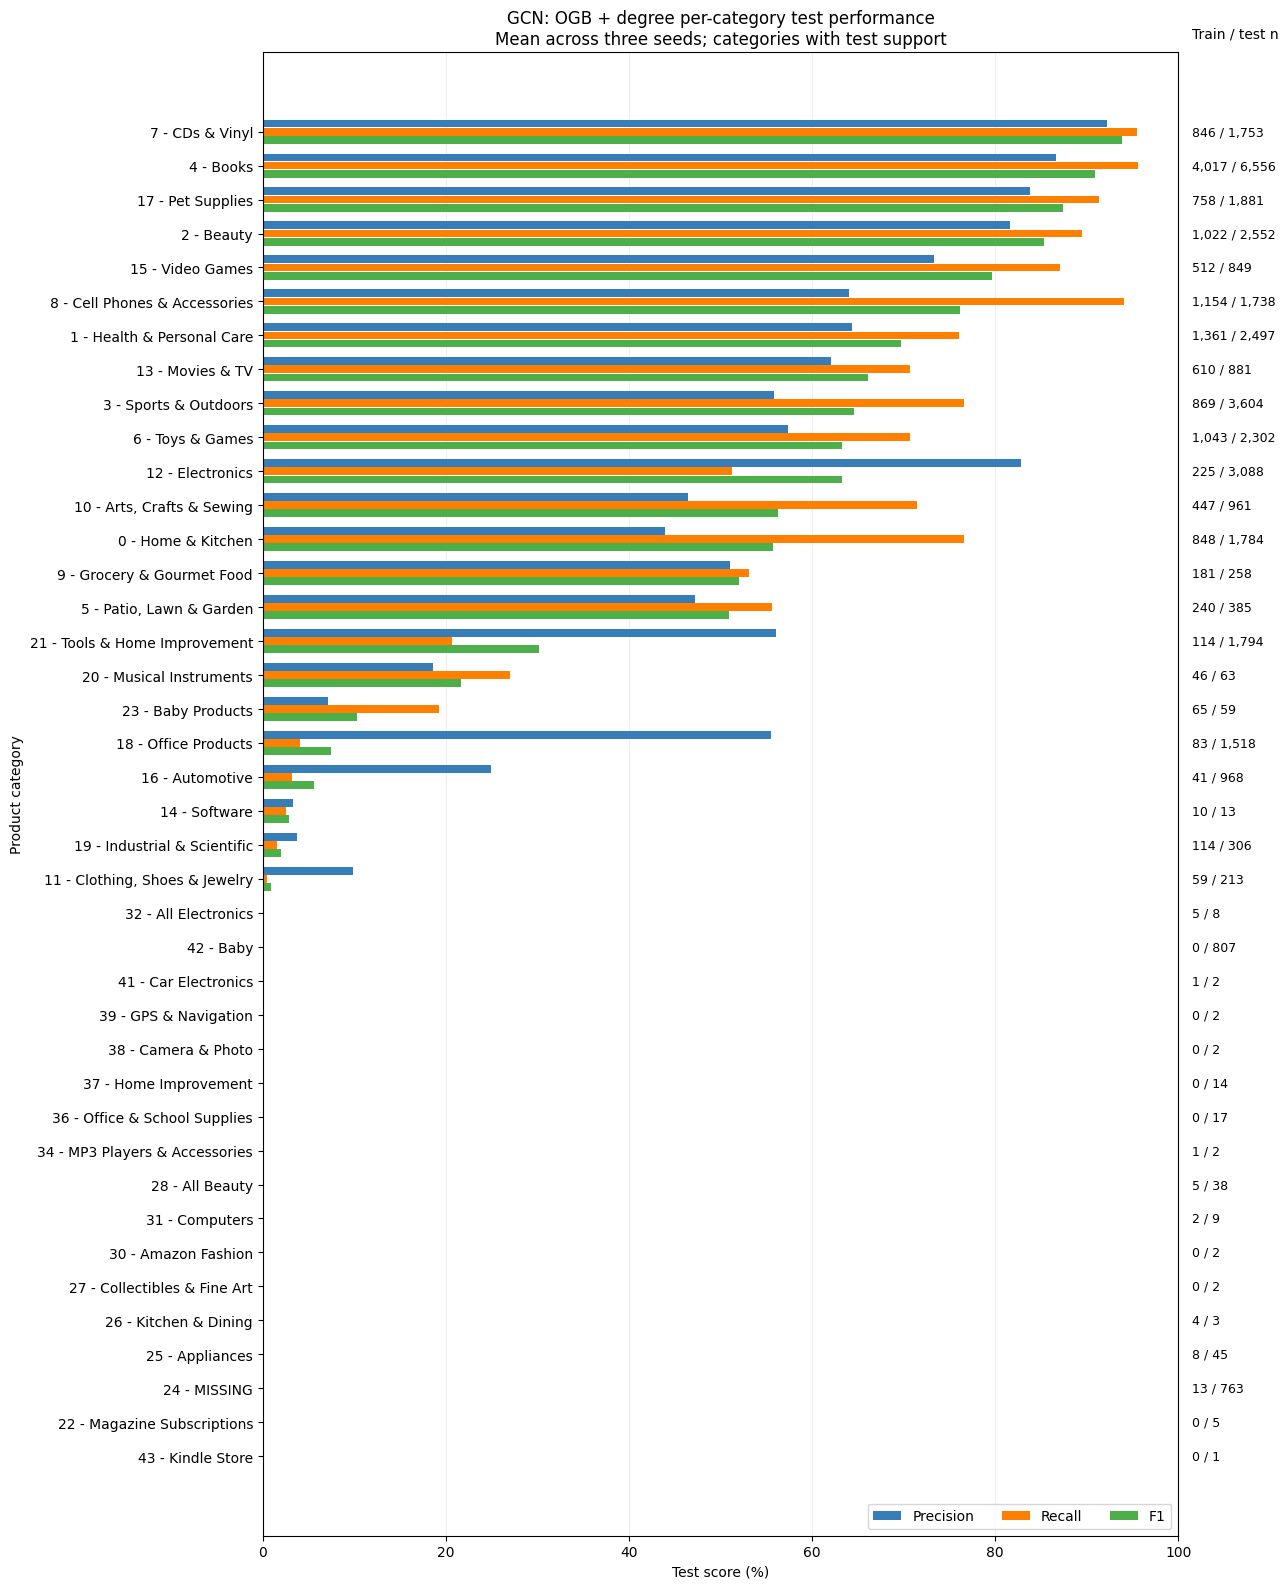

In [47]:
# Figure 1: independently load saved results; no training cells are needed.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

sf_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
               if (p / 'requirements.txt').is_file())
sf_results = sf_root / 'results' / '1_gnn_ogb' / '02_multi_seed'
sf_output = sf_results / 'supporting_figures'
sf_output.mkdir(parents=True, exist_ok=True)
sf_seeds = [5284, 5285, 5286]
sf_architecture, sf_condition = 'GCN', '2_ogb_degree'
sf_frames = []
for seed in sf_seeds:
    folder = sf_results / sf_architecture / 'per_seed' / f'seed_{seed}'
    sf_frames.append(pd.read_csv(folder / f'{sf_condition}_validation_test_per_category.csv').assign(seed=seed))
sf_data = pd.concat(sf_frames, ignore_index=True)
if sf_data.duplicated(['category_id', 'seed']).any():
    raise ValueError('Duplicate category/seed records.')
sf_means = sf_data.groupby('category_id').mean(numeric_only=True)
sf_names = sf_data.drop_duplicates('category_id').set_index('category_id')['category']
sf_test = sf_means.loc[sf_means.support_test > 0].sort_values('f1_test', ascending=False)
sf_y = np.arange(len(sf_test))
fig, ax = plt.subplots(figsize=(13, 16))
for offset, metric, label, color in [(-0.24, 'precision_test', 'Precision', '#377eb8'),
                                    (0, 'recall_test', 'Recall', '#ff7f00'),
                                    (0.24, 'f1_test', 'F1', '#4daf4a')]:
    ax.barh(sf_y + offset, 100 * sf_test[metric], height=0.23, label=label, color=color)
ax.set_yticks(sf_y, [f'{i} - {sf_names[i]}' for i in sf_test.index])
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel='Test score (%)', ylabel='Product category',
       title='GCN: OGB + degree per-category test performance\nMean across three seeds; categories with test support')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
for y, (_, row) in zip(sf_y, sf_test.iterrows()):
    ax.text(1.015, y, f"{int(row.train_support):,} / {int(row.support_test):,}",
            transform=ax.get_yaxis_transform(), va='center', fontsize=9)
ax.text(1.015, 1.01, 'Train / test n', transform=ax.transAxes, fontsize=10)
ax.legend(loc='lower right', ncol=3)
fig.tight_layout()
fig.savefig(sf_output / '01_per_category_test_performance.jpg', dpi=200, bbox_inches='tight')
plt.show()
sf_test.assign(category=sf_names).to_csv(sf_output / 'per_category_three_seed_means.csv')


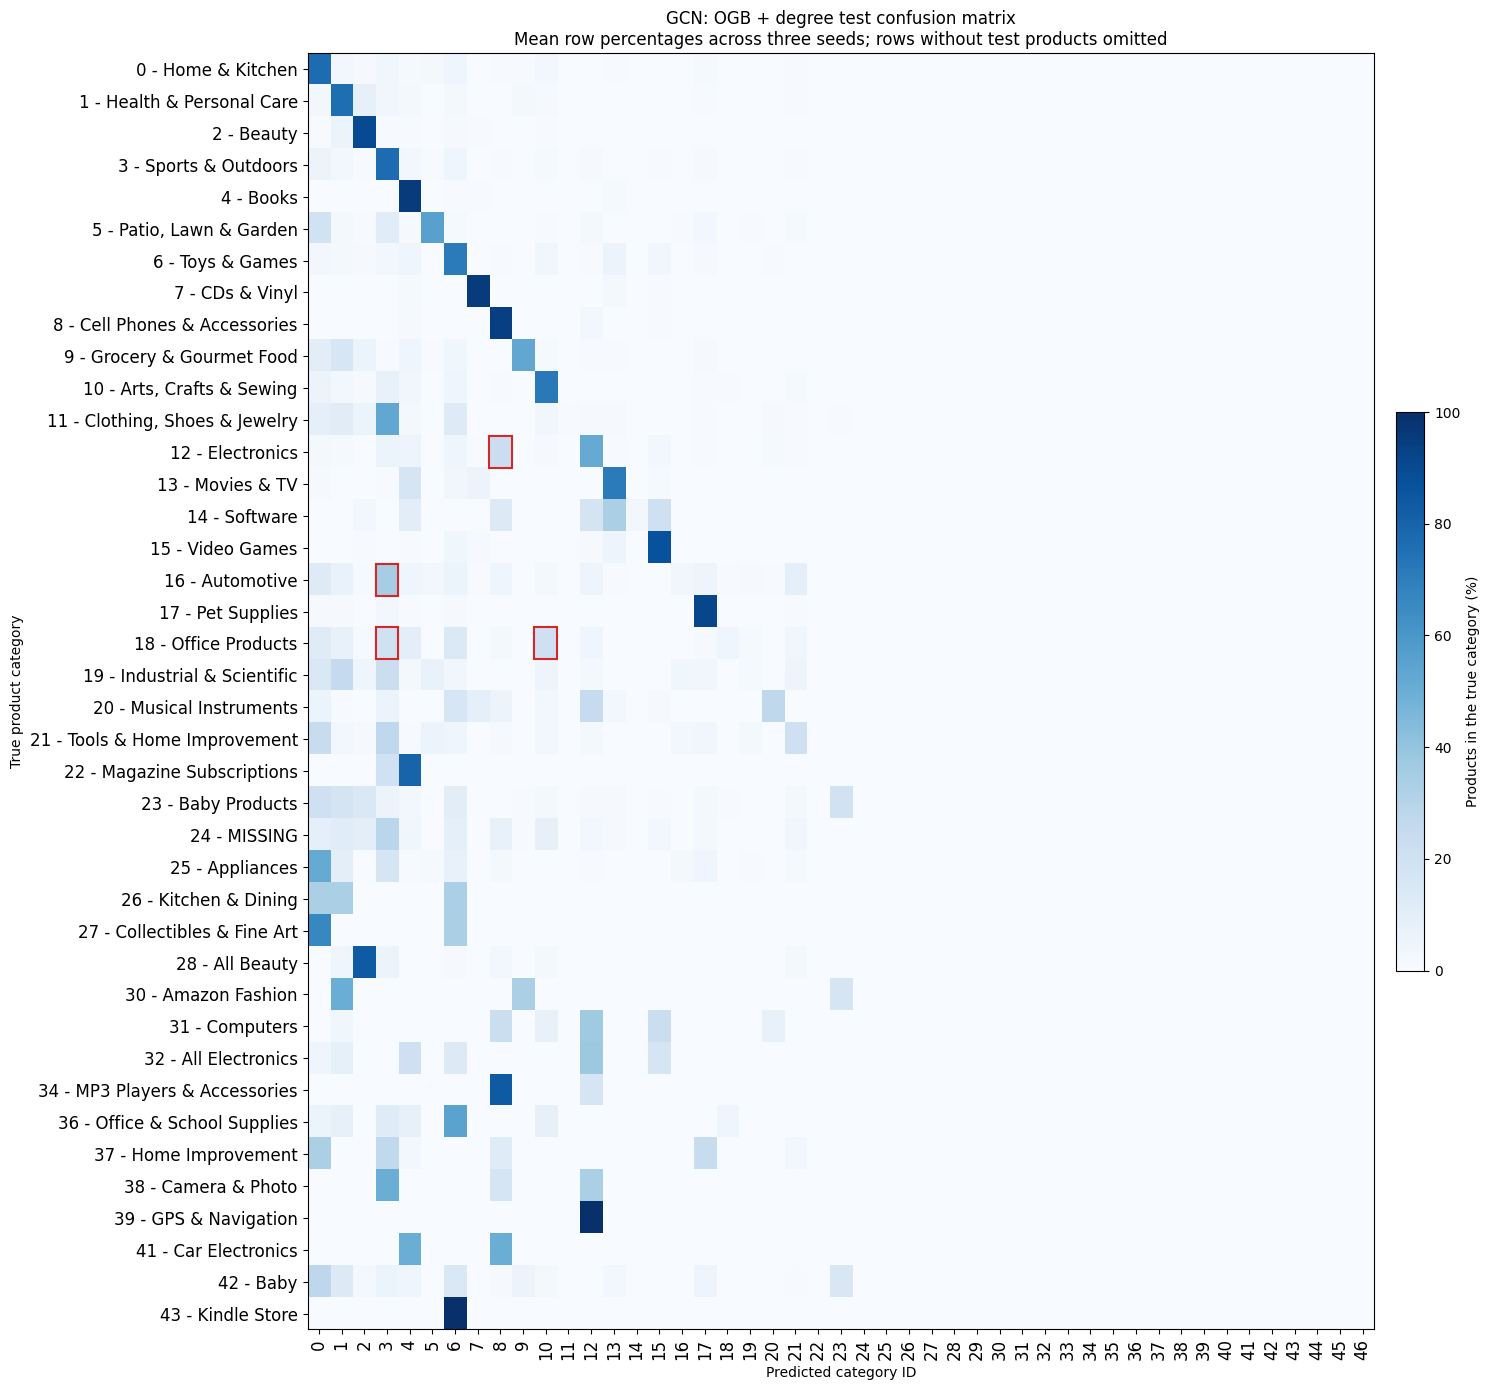

,true_category,predicted_category,percent
0,Electronics,Cell Phones & Accessories,22.0
1,Automotive,Sports & Outdoors,34.8
2,Office Products,"Arts, Crafts & Sewing",20.7
3,Office Products,Sports & Outdoors,19.6


In [52]:
# Figure 2: average row-normalised matrices, without treating seeds as extra products.
# Run Supporting Figure 1 first.
sf_confusions = []
for seed in sf_seeds:
    path = sf_results / sf_architecture / 'per_seed' / f'seed_{seed}' / f'{sf_condition}_test_confusion.csv'
    matrix = pd.read_csv(path, index_col=0)
    matrix.index = matrix.index.astype(int)
    matrix.columns = matrix.columns.astype(int)
    sf_confusions.append(matrix)
sf_counts = sum(sf_confusions) / len(sf_confusions)
sf_normalised = sf_counts.div(sf_counts.sum(axis=1).replace(0, np.nan), axis=0)
sf_rows = sf_means.index[sf_means.support_test > 0].tolist()
fig, ax = plt.subplots(figsize=(15, 14))
im = ax.imshow(100 * sf_normalised.loc[sf_rows], cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_yticks(range(len(sf_rows)), [f'{i} - {sf_names[i]}' for i in sf_rows], fontsize=12)
ax.set_xticks(range(len(sf_counts.columns)), sf_counts.columns, rotation=90, fontsize=12)
ax.set(xlabel='Predicted category ID', ylabel='True product category',
       title='GCN: OGB + degree test confusion matrix\nMean row percentages across three seeds; rows without test products omitted')
fig.colorbar(im, ax=ax, label='Products in the true category (%)', fraction=0.025, pad=0.02)
sf_pairs = [(12, 8), (16, 3), (18, 10), (18, 3)]
sf_pair_rows = []
for true_id, predicted_id in sf_pairs:
    y, x = sf_rows.index(true_id), list(sf_counts.columns).index(predicted_id)
    value = 100 * sf_normalised.loc[true_id, predicted_id]
    ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, edgecolor='#d62728', linewidth=1.5))
    sf_pair_rows.append(dict(true_category=sf_names[true_id], predicted_category=sf_names[predicted_id], percent=value))
fig.tight_layout()
fig.savefig(sf_output / '02_test_confusion_matrix.jpg', dpi=200, bbox_inches='tight')
plt.show()
display(pd.DataFrame(sf_pair_rows).round(1))
sf_normalised.to_csv(sf_output / 'test_confusion_mean_row_normalised.csv')


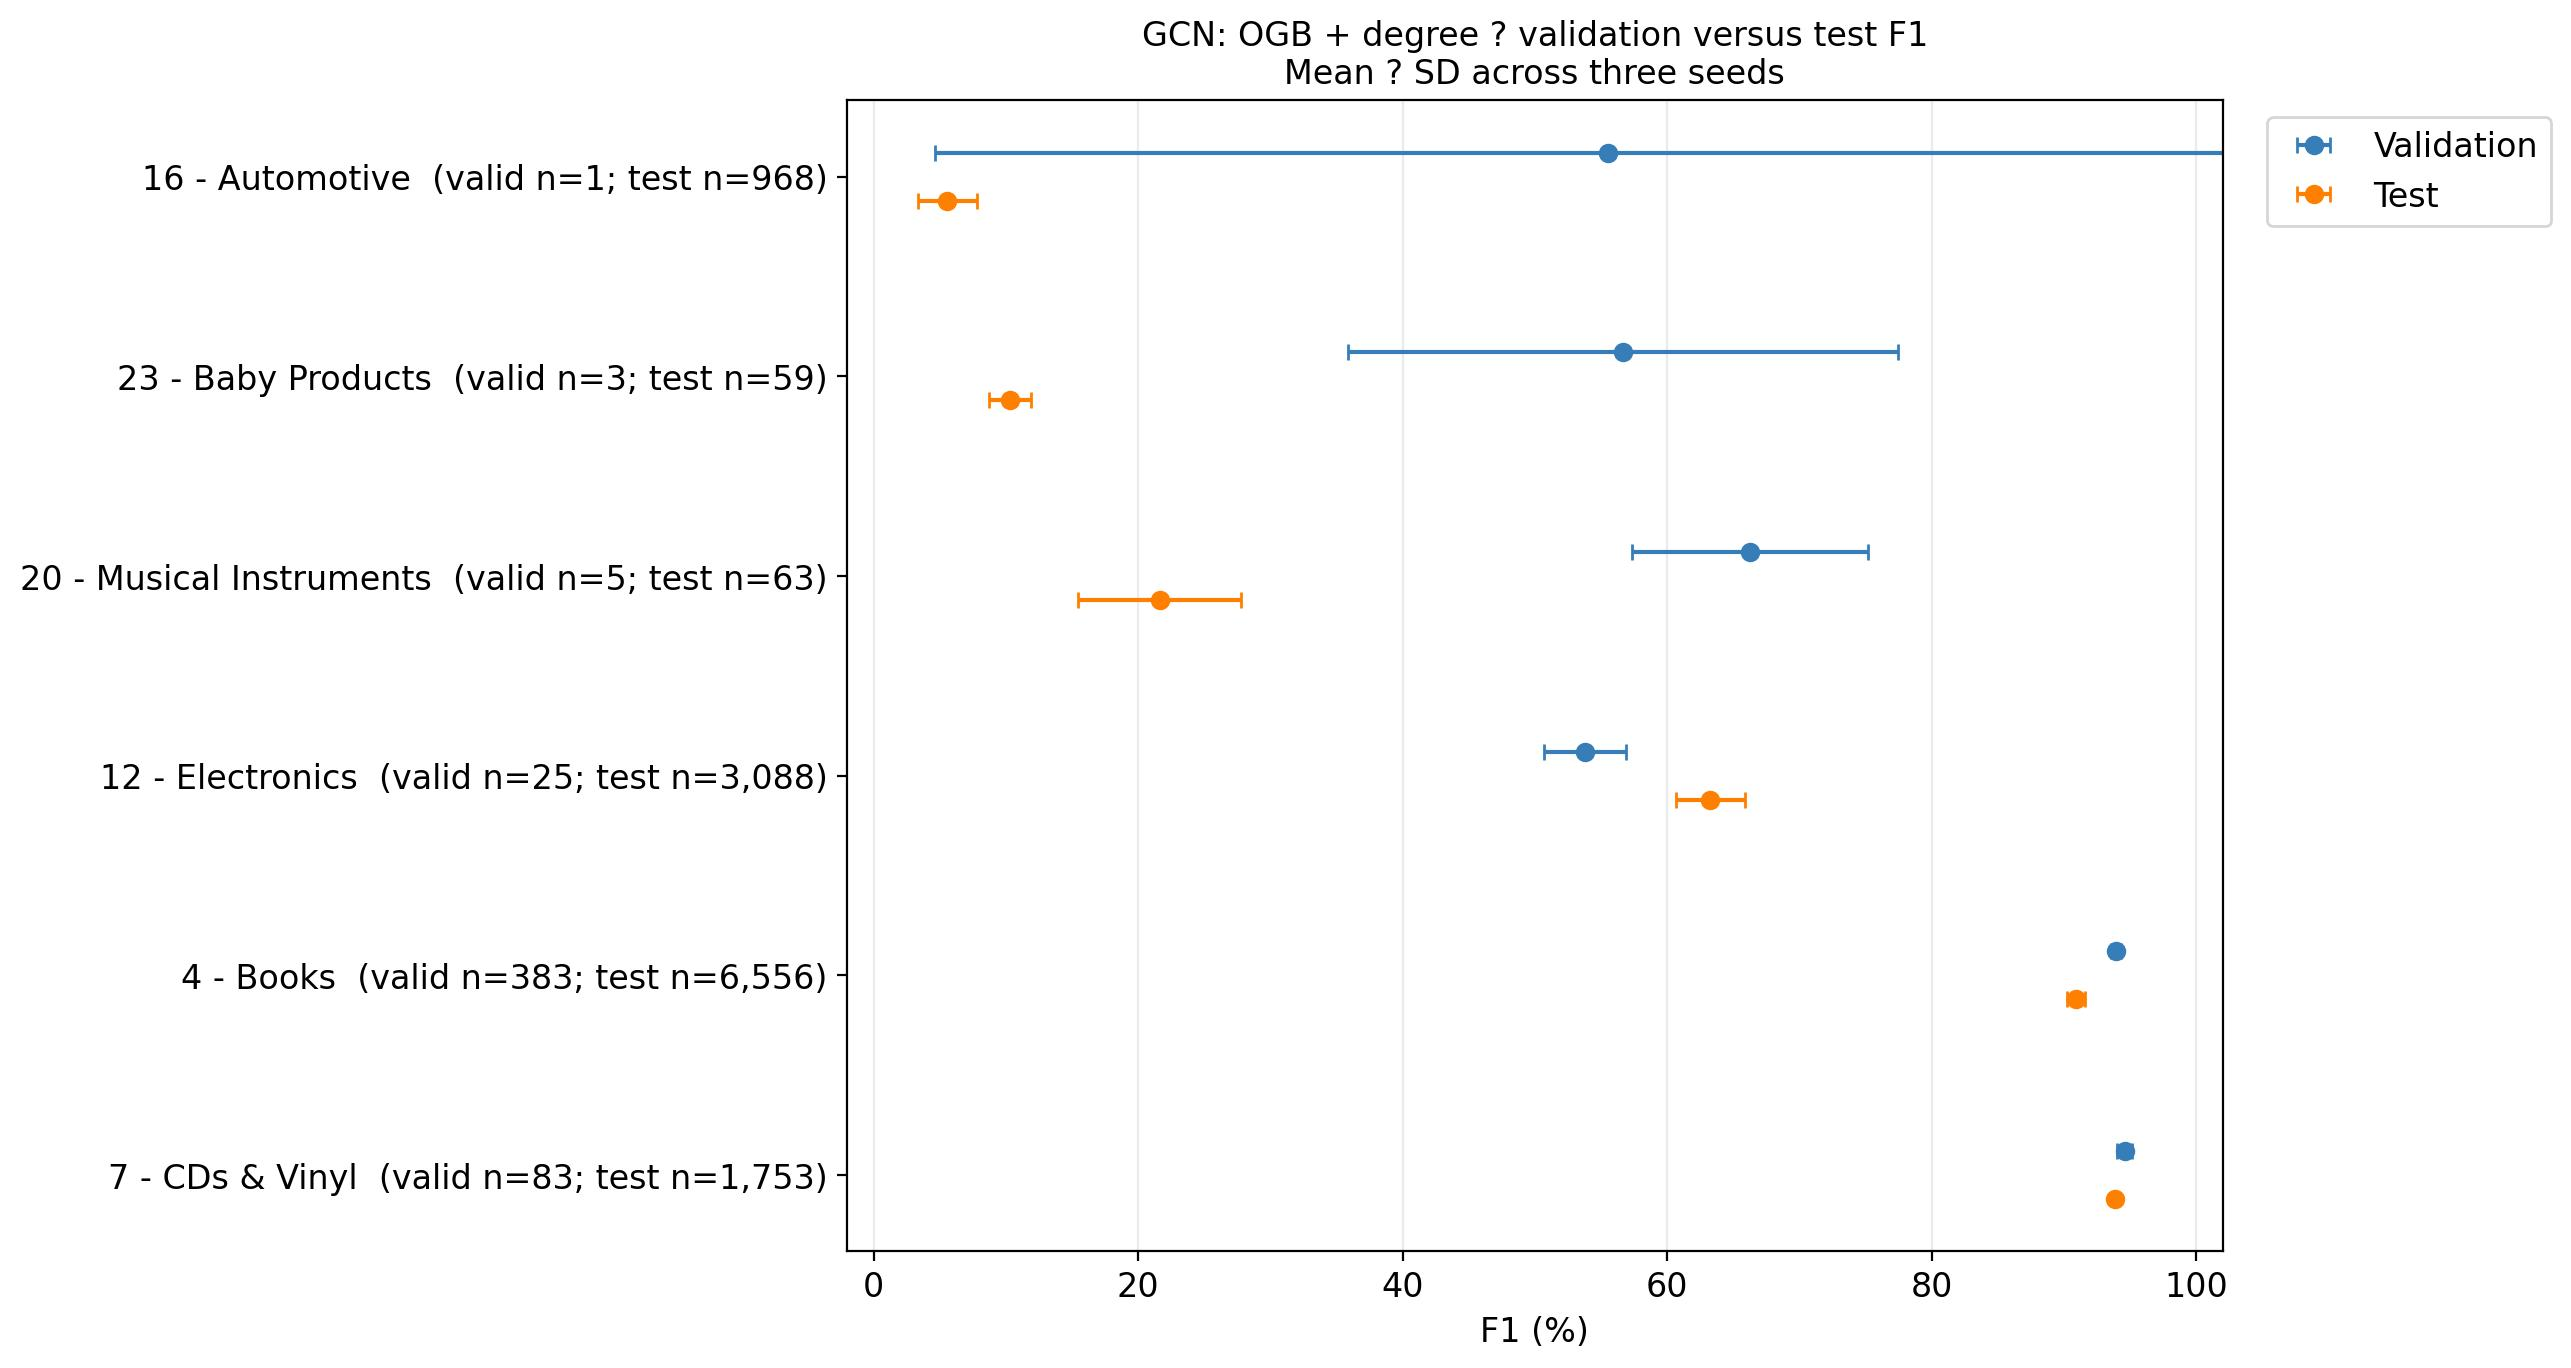

In [53]:
# Figure 3: validation/test F1 variability across seeds and evaluation support.
# Run Supporting Figure 1 first. Categories chosen to illustrate support differences.
sf_selected = [16, 23, 20, 12, 4, 7]
sf_labels = [f'{i} - {sf_names[i]}' for i in sf_selected]
sf_y = np.arange(len(sf_selected))
fig, ax = plt.subplots(figsize=(13, 7))
for offset, split, label, color in [(-0.12, 'valid', 'Validation', '#377eb8'),
                                   (0.12, 'test', 'Test', '#ff7f00')]:
    groups = sf_data.groupby('category_id')[f'f1_{split}']
    mean = groups.mean().loc[sf_selected] * 100
    sd = groups.std().loc[sf_selected] * 100
    ax.errorbar(mean, sf_y + offset, xerr=sd, fmt='o', capsize=3, color=color, label=label)
ax.set_yticks(sf_y, [f'{label}  (valid n={int(sf_means.loc[i, "support_valid"]):,}; test n={int(sf_means.loc[i, "support_test"]):,})'
                    for i, label in zip(sf_selected, sf_labels)])
ax.invert_yaxis()
ax.set(xlim=(-2, 102), xlabel='F1 (%)',
       title='GCN: OGB + degree ? validation versus test F1\nMean ? SD across three seeds')
ax.tick_params(axis='both', labelsize=12)
ax.xaxis.label.set_size(12)
ax.yaxis.label.set_size(12)
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=12)
fig.tight_layout()
fig.savefig(sf_output / '03_validation_test_support_comparison.jpg', dpi=200, bbox_inches='tight')
plt.show()
